# Xenium breast cancer — neighbourhood → proliferation exploration

This notebook works through two things before trusting any per-cell fate model,
following the review of the earlier diagnostics:

1. **A tile-level (bin) sanity check** — aggregate the slide into ~100 µm
   tiles and ask, at roughly the *effective* sample size, whether neighbourhood
   composition predicts proliferation at all. If there's no signal here, no
   per-cell architecture will find one.
2. **An MKI67 count model** — regress the direct proliferation marker's counts
   on the neighbourhood with a negative-binomial GLM and a `log(total_counts)`
   offset. This sidesteps the noisy cell-cycle *hard-label* thresholding
   entirely (the earlier 60%/20% "dividing" numbers were largely a definitional
   artefact of `score_genes_cell_cycle`, not biology).

Everything here calls reusable functions in `tissue_dynamics` so you can rerun
and adapt them interactively.

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # avoid the libomp double-load abort

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tissue_dynamics import (
    read_xenium, read_phi_table, attach_phi, build_adjacency, average_neighbors,
    score_division, score_death, build_fate_targets,
    assign_tiles, aggregate_tiles, binned_conditional_mean,
    plot_binned_conditional_mean, plot_tile_field,
    compare_count_glms, fit_neighbourhood_count_glm, fit_count_glm, get_gene_counts,
)

DATA = "../data/Xenium_Prime_Breast_Cancer_FFPE"
PHI  = "../data/xenium_prime_celltype_minor_phispace.csv"

## 1. Load data, attach Phi-Space, build the spatial neighbourhood

In [2]:
adata = read_xenium(DATA, sample_id="BC")
attach_phi(adata, read_phi_table(PHI, phi_cols="all"))
adata = adata[~np.isnan(adata.obsm["phi"]).any(axis=1)].copy()   # drop unscored (empty) cells
build_adjacency(adata, radius=80.0)
average_neighbors(adata)
phi_names = adata.uns["phi_names"]
print(adata)
print("median spatial neighbours:", int(np.median(adata.obs["n_spatial_neighbors"])))

/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_92080/1408393183.py:1: UserWarning: spatialdata-io failed to read this sample (FileNotFoundError(2, 'No such file or directory')); falling back to the manual cell_feature_matrix reader.
  adata = read_xenium(DATA, sample_id="BC")
/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_92080/1408393183.py:2: UserWarning: 16257/699110 cells have a NaN phi embedding (a matched row exists, but with missing values -- typically near-empty segmentation artifacts the embedding method couldn't score). These will propagate NaNs into neighbor-averaging and model fitting; filter them out first, e.g. `adata = adata[~np.isnan(adata.obsm['phi']).any(axis=1)].copy()`.
  attach_phi(adata, read_phi_table(PHI, phi_cols="all"))
/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_92080/1408393183.py:4: UserWarning: 56/682853 cells have no spatial neighbors within radius=80.0 (isolated); their neighbor-averaged embedding will be the zero v

AnnData object with n_obs × n_vars = 682853 × 5101
    obs: 'cell_area', 'cell_id', 'sample_id', 'n_spatial_neighbors', 'is_isolated'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'phi_dim', 'phi_names', 'spatial_connectivity_params'
    obsm: 'spatial', 'phi', 'phi_bar'
    obsp: 'spatial_connectivity'
median spatial neighbours: 163


## 2. Score fate labels — and note how sparse the direct marker is

We still compute the cell-cycle / apoptosis scores (they define the "dividing"/
"dying" labels the earlier model used), but note the key data fact: **MKI67, the
direct proliferation marker, is detected in ~1% of cells** on this shallow 5k
panel (median ~50 transcripts/cell). That sparsity is exactly why per-cell hard
labels are hopeless and why we aggregate to tiles below.

In [4]:
score_division(adata)     # sets obs['is_dividing'], obs['proliferation_score']; stashes raw counts in layers['counts']
score_death(adata)        # sets obs['is_dying']
build_fate_targets(adata, mode="hard")

mki, total = get_gene_counts(adata, "MKI67")
print(f"MKI67 detected in {100*(mki>0).mean():.2f}% of cells (mean {mki.mean():.3f} counts)")
print(f"median library size (total_counts): {np.median(total):.0f}")
print("\nhard fate-label distribution:")
print(adata.obs["fate_label"].value_counts())

MKI67 detected in 1.11% of cells (mean 0.013 counts)
median library size (total_counts): 51

hard fate-label distribution:
fate_label
unchanged    477087
divide       129245
die           76521
Name: count, dtype: int64


## 3. Tile-level sanity check

Tile the slide at 100 µm and aggregate. The number of tiles is roughly the
**effective sample size** for a neighbourhood model — a few thousand, not the
683k cells — because adjacent cells share almost their whole neighbourhood.

In [5]:
assign_tiles(adata, tile_size=100.0)
tiles = aggregate_tiles(
    adata,
    phi_key="phi", phi_bar_key="phi_bar",
    obs_means=["is_dividing", "is_dying", "proliferation_score", "cell_area"],
    gene_counts=["MKI67"],
    min_cells=10,
)
tiles["mki67_rate"] = tiles["MKI67_sum"] / tiles["total_counts_sum"]
print(f"{len(tiles)} tiles (>=10 cells) vs {adata.n_obs} cells "
      f"-> effective n ~ {len(tiles)}, not {adata.n_obs}")
tiles[["n_cells", "is_dividing_mean", "mki67_rate", "proliferation_score_mean"]].describe()

10403 tiles (>=10 cells) vs 682853 cells -> effective n ~ 10403, not 682853


,n_cells,is_dividing_mean,mki67_rate,proliferation_score_mean
count,10403.000000,10403.000000,10403.000000,10403.000000
mean,64.325964,0.191288,0.000088,0.003546
std,43.249783,0.110454,0.000511,0.003159
min,10.000000,0.000000,0.000000,-0.004475
25%,29.000000,0.107143,0.000000,0.001305
50%,60.000000,0.186047,0.000000,0.003446
75%,85.000000,0.264218,0.000115,0.005446
max,299.000000,0.793103,0.046512,0.023458


Spatial maps of the tile fields — is proliferation spatially structured (a margin), or uniform?

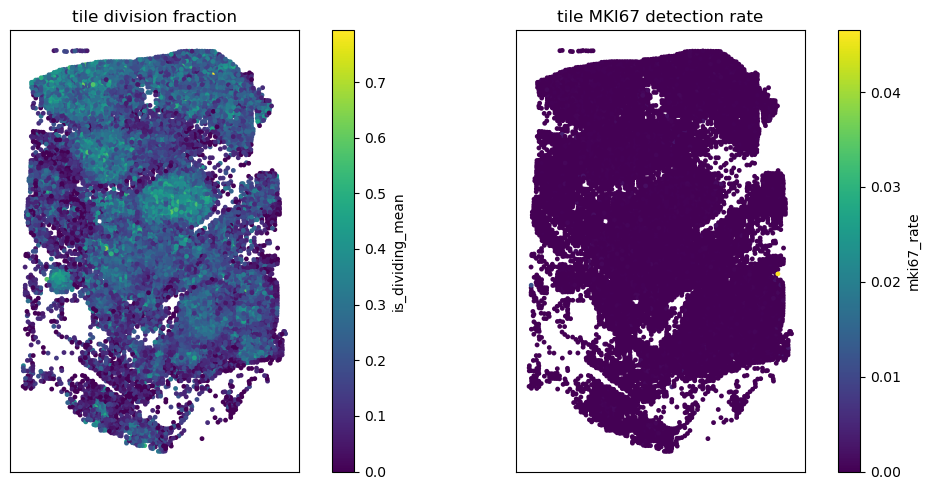

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_tile_field(tiles, "is_dividing_mean", ax=axes[0], title="tile division fraction")
plot_tile_field(tiles, "mki67_rate", ax=axes[1], title="tile MKI67 detection rate")
plt.show()

### Tile-level regression: does mean neighbourhood composition track proliferation?

Regress the tile division fraction (and the MKI67 rate) on the tile's mean
Phi-Space composition. This is the OSDR premise tested at the honest sample
size. Look at the R² / deviance, not per-cell accuracy.

In [7]:
import statsmodels.api as sm

phi_cols = [c for c in tiles.columns if c.startswith("phi_mean_")]
X = sm.add_constant(tiles[phi_cols].to_numpy())

ols = sm.OLS(tiles["is_dividing_mean"].to_numpy(), X).fit()
print(f"tile division fraction ~ mean phi   : R^2 = {ols.rsquared:.3f}  (n_tiles={int(ols.nobs)})")

# MKI67 counts per tile as negative binomial with log-library offset
y_tile = tiles["MKI67_sum"].to_numpy()
offset = np.log(tiles["total_counts_sum"].to_numpy())
phibar_cols = [c for c in tiles.columns if c.startswith("phibar_mean_")]
Xt = tiles[phibar_cols].to_numpy()
fit_t = fit_count_glm(y_tile, Xt, phibar_cols, offset=offset, family="nb")
null_t = fit_count_glm(y_tile, np.empty((len(y_tile), 0)), [], offset=offset, family="nb")
mcf = 1 - fit_t["loglik"] / null_t["loglik"]
print(f"tile MKI67 ~ mean neighbour phi (NB): McFadden R^2 = {mcf:.3f}, alpha = {fit_t['alpha']:.2f}")

tile division fraction ~ mean phi   : R^2 = 0.638  (n_tiles=10403)
tile MKI67 ~ mean neighbour phi (NB): McFadden R^2 = 0.077, alpha = 0.13


### Binned conditional-mean plot — the key figure

Bin cells by a single neighbourhood axis (the leading `phi_bar` PC) and plot the
observed division fraction per bin. A monotone curve spanning a wide range is
the neighbourhood signal OSDR needs — visible even if per-cell accuracy is near
the majority baseline. A flat line says the neighbourhood carries little.

In [ ]:
from sklearn.decomposition import PCA
pc1 = PCA(n_components=1, random_state=0).fit_transform(adata.obsm["phi_bar"])[:, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
b1 = binned_conditional_mean(pc1, adata.obs["is_dividing"].to_numpy().astype(float), n_bins=12)
plot_binned_conditional_mean(b1, ax=axes[0], xlabel="leading neighbour-state PC",
                             ylabel="division fraction", title="division vs neighbourhood axis")
b2 = binned_conditional_mean(adata.obs["proliferation_score"].to_numpy(),
                             adata.obs["is_dividing"].to_numpy().astype(float), n_bins=12)
plot_binned_conditional_mean(b2, ax=axes[1], xlabel="own proliferation score",
                             ylabel="division fraction", title="division vs own score")
plt.show()

## 4. MKI67 count model (per cell)

Now the count-based analogue of the fate model. We fit a nested ladder of
negative-binomial GLMs for MKI67 counts with `log(total_counts)` offset,
PC-reducing each embedding block to 6 components (the raw 29-dim blocks are too
collinear). Reading down the table answers: does the neighbourhood add anything
beyond own state (and beyond the null)?

In [ ]:
ladder = compare_count_glms(adata, gene="MKI67",
                            specs=("none", "own", "neighbor", "own+neighbor"),
                            n_pcs=6, family="nb")
ladder

,spec,n_params,loglik,mcfadden_r2,lr_vs_null_p
0,none,1,-37286.951466,0.000000,1.000000e+00
1,own,7,-33654.795636,0.097411,0.000000e+00
2,neighbor,7,-36655.040803,0.016947,7.350924e-270
3,own+neighbor,13,-33533.522090,0.100663,0.000000e+00


In [ ]:
# Coefficients of the neighbour-only model (on the 6 neighbour PCs)
fit_nbr = fit_neighbourhood_count_glm(adata, gene="MKI67", predictors="neighbor", n_pcs=6, family="nb")
print(f"neighbour model: McFadden R^2 = {fit_nbr['mcfadden_r2']:.4f}, "
      f"LR vs null p = {fit_nbr['lr_vs_null']['p_value']:.2e}, alpha = {fit_nbr['alpha']:.2f}")
fit_nbr["coef"]

neighbour model: McFadden R^2 = 0.0169, LR vs null p = 7.35e-270, alpha = 4.29


,term,estimate,std_error,z,p_value
0,const,-9.371711,0.017156,-546.254355,0.000000e+00
1,nbr_pc0,2.643164,0.092514,28.570361,1.569216e-179
2,nbr_pc1,2.180101,0.355699,6.129070,8.839415e-10
3,nbr_pc2,-3.627138,0.397392,-9.127358,7.019129e-20
4,nbr_pc3,1.391928,0.419154,3.320801,8.975951e-04
5,nbr_pc4,-2.221761,0.697524,-3.185212,1.446482e-03
6,nbr_pc5,-8.524510,0.595581,-14.312929,1.816971e-46


## 5. Cheap collinearity diagnostics on the neighbourhood

Two quick measurements (not nuisances to regularise away — they *are* the
result): how low-rank is `phi_bar`, and how much of it is already predictable
from a cell's own `phi`? If `phi_bar` is nearly determined by `phi`, there is
little independent neighbourhood information for any model to use.

In [ ]:
from sklearn.linear_model import LinearRegression

phi = adata.obsm["phi"]; phi_bar = adata.obsm["phi_bar"]
evr = PCA().fit(phi_bar - phi_bar.mean(0)).explained_variance_ratio_
for thr in (0.9, 0.99):
    print(f"PCs of phi_bar for {int(thr*100)}% variance: {int(np.searchsorted(np.cumsum(evr), thr)+1)}/{phi_bar.shape[1]}")

r2 = LinearRegression().fit(phi, phi_bar).score(phi, phi_bar)
print(f"\npartial: phi_bar is {r2:.1%} predictable from own phi "
      f"(high => little independent neighbourhood signal left for c / B)")

PCs of phi_bar for 90% variance: 6/29
PCs of phi_bar for 99% variance: 17/29



partial: phi_bar is 27.2% predictable from own phi (high => little independent neighbourhood signal left for c / B)


## Takeaways to check as you rerun

- If the **binned conditional-mean** curve is flat and the **tile-level R²** and
  **MKI67 McFadden R²** are near zero, that's evidence neighbourhood composition
  adds little beyond own state in this sample — a credible *negative* result
  about OSDR's transferability to Xenium, worth establishing rather than
  fitting around.
- If `phi_bar` is >~80% predictable from `phi`, the own/neighbour collinearity
  (not the within-`B` collinearity) is the real limiter.
- Next steps from the review, in order: spatial block CV + cluster-robust SEs;
  restrict to high-heterogeneity (margin) tiles; add local covariance / density
  and `log(total_counts)`, `cell_area` covariates; PC-truncate the interaction;
  then a learned kernel length-scale (the discrete precursor of your diffusion
  coefficient).

In [ ]:
import gseapy
hall = gseapy.get_library('MSigDB_Hallmark_2020')
blocked = set(hall['G2-M Checkpoint']) | set(hall['E2F Targets'])

## 6. Soft labelling with celltype-major Phi-Space + technical covariates

The sections above used the fine `celltype_minor` Phi-Space and *hard* fate
labels. Here we redo the fate model with three changes the review motivated:

1. **New Phi-Space** — the normalised `celltype_major` projection
   (`data/phispace_normalised.csv`): 9 broad cell-type dimensions instead of the
   fine minor types. Coarser, but each dimension is a named, interpretable
   cell type ("Cancer Epithelial", "T-cells", ...).
2. **Soft labels** — instead of a hard divide/die/unchanged call per cell, we
   fit against the *probability* of each fate (`build_fate_targets(mode="soft")`:
   per-section z-scored proliferation/death signal, clipped at 0 and normalised
   with a baseline). This keeps the graded evidence a hard threshold throws away.
3. **Technical covariates** — per-cell **log library size** and **local
   density**, entered as linear confounder-control terms (excluded from weight
   decay). Any count-derived fate signal correlates with sequencing depth; these
   let us ask what neighbourhood signal survives once depth/density are held fixed.

**One important subtlety.** These `celltype_major` scores are *compositional* —
the 9 values sum to a constant (−7) for every cell. That makes the intercept
exactly collinear with `phi` (and again with `phi_bar`), so the full 9-dim design
is rank-deficient and per-coefficient standard errors are not identified (the
information matrix is singular). The standard fix — exactly analogous to the
model already holding one *class* as reference — is to drop one *cell type* as a
reference. We drop **Endothelial**; every `a`/`c` coefficient below is then read
*relative to a cell scoring as Endothelial*.

In [2]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # avoid the libomp double-load abort
import numpy as np
import matplotlib.pyplot as plt

from tissue_dynamics import (
    read_xenium, read_phi_table, attach_phi, build_adjacency, average_neighbors,
    score_division, score_death, build_fate_targets,
    compute_library_size, compute_local_density, build_covariate_matrix,
    SpatialMultinomialFateModel, fit_fate_model, predict_fate_proba,
    fate_parameter_stats, fate_metrics, plot_coefficients,
)

DATA      = "../data/Xenium_Prime_Breast_Cancer_FFPE"
PHI_MAJOR = "../data/phispace_normalised.csv"   # normalised celltype_major PhiSpace
REF       = "Endothelial"                       # reference cell type (dropped; see note above)

bc = read_xenium(DATA, sample_id="BC")
phi_tab = read_phi_table(PHI_MAJOR, phi_cols="all")            # 9 celltype-major scores
bc = bc[bc.obs["cell_id"].isin(phi_tab.index)].copy()          # keep only phi-scored cells
                                                               # (~15k zero-count artefacts dropped)
# covariates from RAW counts -- compute BEFORE score_division lognormalizes X
compute_library_size(bc)                                       # -> obs['log_total_counts']
compute_local_density(bc, radius=50.0)                         # -> obs['local_density'] (cells/100um^2)

attach_phi(bc, phi_tab)
bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()          # drop NaN embeddings

# drop the reference cell type so [intercept, phi, phi_bar] is full-rank
_names = bc.uns["phi_names"]
_keep  = [i for i, n in enumerate(_names) if n != REF]
bc.obsm["phi"]      = bc.obsm["phi"][:, _keep]
bc.uns["phi_names"] = [_names[i] for i in _keep]

build_adjacency(bc, radius=80.0)
average_neighbors(bc)                                          # -> obsm['phi_bar'] (8-dim)
score_division(bc); score_death(bc)
build_fate_targets(bc, mode="soft")                            # -> obsm['fate_target'] (probabilities)

Z, cov_names = build_covariate_matrix(bc, covariate_keys=("log_total_counts", "local_density"))
phi, phi_bar, T = bc.obsm["phi"], bc.obsm["phi_bar"], bc.obsm["fate_target"]
phi_names = bc.uns["phi_names"]

print(bc.n_obs, "cells |", phi.shape[1], "phi dims (reference =", REF + "):", phi_names)
print("soft target mean mass  [divide, die, unchanged]:", T.mean(0).round(3))
print("covariates:", cov_names,
      "| log_total_counts mean=%.2f, local_density median=%.0f cells/100um^2"
      % (bc.obs["log_total_counts"].mean(), bc.obs["local_density"].median()))

/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_93590/554773725.py:18: UserWarning: spatialdata-io failed to read this sample (FileNotFoundError(2, 'No such file or directory')); falling back to the manual cell_feature_matrix reader.
  bc = read_xenium(DATA, sample_id="BC")
/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_93590/554773725.py:26: UserWarning: 3592/683798 cells have a NaN phi embedding (a matched row exists, but with missing values -- typically near-empty segmentation artifacts the embedding method couldn't score). These will propagate NaNs into neighbor-averaging and model fitting; filter them out first, e.g. `adata = adata[~np.isnan(adata.obsm['phi']).any(axis=1)].copy()`.
  attach_phi(bc, phi_tab)
/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_93590/554773725.py:35: UserWarning: 54/680206 cells have no spatial neighbors within radius=80.0 (isolated); their neighbor-averaged embedding will be the zero vector.
  build_adjacency(bc, radius

680206 cells | 8 phi dims (reference = Endothelial): ['CAFs', 'PVL', 'B-cells', 'T-cells', 'Myeloid', 'Normal Epithelial', 'Plasmablasts', 'Cancer Epithelial']
soft target mean mass  [divide, die, unchanged]: [0.104 0.068 0.828]
covariates: ['log_total_counts', 'local_density'] | log_total_counts mean=3.81, local_density median=84 cells/100um^2


### Fit the soft model, with vs without the covariates

Both are no-interaction MLEs (`interaction_rank=0`, `weight_decay=0`) so the Wald
standard errors are valid; comparing them isolates what the covariates absorb. If
the design is genuinely full-rank now, `fate_parameter_stats` should run without
an "ill-conditioned information matrix" warning.

In [2]:
base = SpatialMultinomialFateModel(phi_dim=phi.shape[1], interaction_rank=0)
fit_fate_model(base, phi, phi_bar, T, n_epochs=250, batch_size=8192, weight_decay=0.0)

cov = SpatialMultinomialFateModel(phi_dim=phi.shape[1], interaction_rank=0, n_covariates=len(cov_names))
fit_fate_model(cov, phi, phi_bar, T, covariates=Z, n_epochs=250, batch_size=8192, weight_decay=0.0)

m0 = fate_metrics(T, predict_fate_proba(base, phi, phi_bar))
m1 = fate_metrics(T, predict_fate_proba(cov, phi, phi_bar, covariates=Z))
print("soft cross-entropy   no-cov %.4f  ->  with-cov %.4f" % (m0["cross_entropy"], m1["cross_entropy"]))

stats = fate_parameter_stats(cov, phi, phi_bar, covariates=Z,
                             feature_names=phi_names, covariate_names=cov_names)

print("\ncovariate coefficients (per SD; unregularized confounder controls):")
print(stats[stats["term"].str.startswith("d[")][
    ["class", "term", "estimate", "std_error", "z", "p_value"]].to_string(index=False))

cmag = lambda m: float(np.abs(m.c.detach().numpy()).mean())
print("\nmean |neighbour-state coefficient c|:   no-cov %.3f   vs   with-cov %.3f"
      % (cmag(base), cmag(cov)))

soft cross-entropy   no-cov 0.5516  ->  with-cov 0.5425

covariate coefficients (per SD; unregularized confounder controls):
 class                term  estimate  std_error         z  p_value
divide d[log_total_counts]  1.381689   0.018717 73.818897 0.000000
divide    d[local_density]  0.025012   0.006305  3.967090 0.000073
   die d[log_total_counts]  2.082371   0.028134 74.015317 0.000000
   die    d[local_density] -0.027502   0.007754 -3.546944 0.000390

mean |neighbour-state coefficient c|:   no-cov 0.537   vs   with-cov 0.581


### Interpreting the coefficients

Because the dimensions are named cell types, the own-state (`a`) and
neighbour-state (`c`) coefficients read directly (all relative to the Endothelial
reference). `a[X] on divide` = a cell scoring high for type *X* is more/less
likely to be proliferating; `c[X] on divide` = a cell *surrounded by* type *X* is
more/less likely to be proliferating, **after** adjusting for its own state,
library size and density.

=== OWN state  a[.] -- top terms by |z| (reference = Endothelial) ===
 class                 term  estimate          z       p_value
divide           a[T-cells]  1.863644  34.723940 3.429437e-264
divide a[Cancer Epithelial]  1.545452  29.553457 5.928668e-192
divide           a[B-cells]  1.678009  27.212958 4.563101e-163
   die           a[T-cells]  1.345379  25.320948 1.878201e-141
   die           a[B-cells]  1.043413  16.226603  3.270678e-59
divide              a[CAFs] -1.528398 -15.623686  5.021637e-55
   die              a[CAFs] -1.531602 -15.477006  4.960296e-54
   die           a[Myeloid]  0.679870  10.636720  2.010845e-26
divide a[Normal Epithelial]  0.361737   5.175876  2.268445e-07
   die               a[PVL]  0.353703   3.717526  2.011835e-04

=== NEIGHBOUR state  c[.] -- top terms by |z| (reference = Endothelial) ===
 class                 term  estimate         z      p_value
divide c[Cancer Epithelial]  1.432231  9.925186 3.235000e-23
divide c[Normal Epithelial] -1.977138 

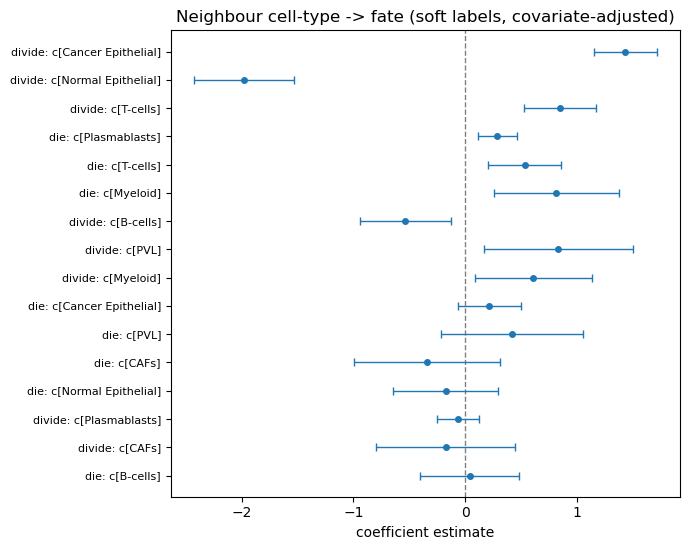

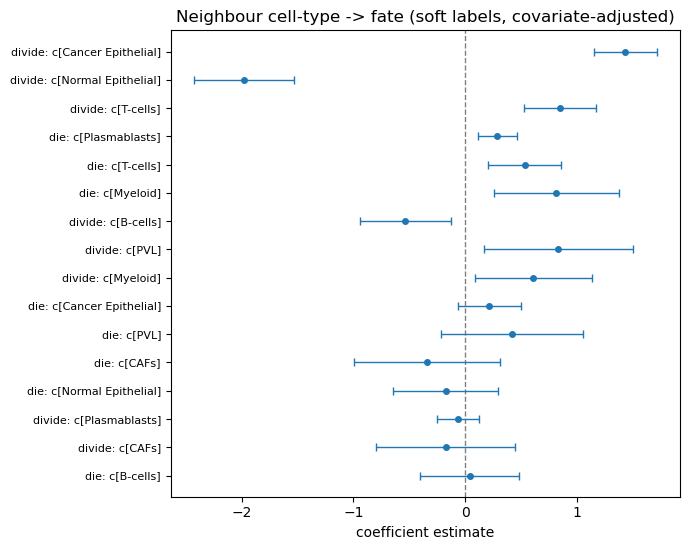

In [3]:
for block, label in [("a[", "OWN state  a[.]"), ("c[", "NEIGHBOUR state  c[.]")]:
    sub = stats[stats["term"].str.startswith(block)].copy()
    sub["abs_z"] = sub["z"].abs()
    print("=== %s -- top terms by |z| (reference = Endothelial) ===" % label)
    print(sub.sort_values("abs_z", ascending=False)[
        ["class", "term", "estimate", "z", "p_value"]].head(10).to_string(index=False))
    print()

# forest plot: neighbour cell-type -> fate, covariate-adjusted
c_stats = stats[stats["term"].str.startswith("c[")]
fig, ax = plot_coefficients(c_stats, top_n=16,
                            title="Neighbour cell-type -> fate (soft labels, covariate-adjusted)")
fig.tight_layout()
fig

## 7. Alternative model — negative-binomial division count (death not modelled)

The multinomial fate model in Sections 1–6 asks a *classification* question
(divide vs die vs unchanged). Here is a deliberately different model that
**drops death entirely** and treats division as a **count**:

- **Response** — the summed raw counts of the cell-cycle genes present in the
  panel (the Tirosh S+G2M set, i.e. the same genes `score_cell_cycle` uses). So
  instead of thresholding a proliferation *score* into a "dividing" label, we
  regress the underlying cell-cycle *transcript counts* directly. This count is
  strongly over-dispersed (variance ≫ mean), so we use a **negative binomial**
  GLM rather than Poisson.
- **Predictors** — own state (`phi`) + neighbour state (`phi_bar`), the named
  celltype-major dimensions (reference = Endothelial, as in Section 6).
- **Covariates** — **the same** log library size + local density, entered as
  free standardized coefficients (matching the fate model — note this is a free
  depth coefficient, not the fixed `log(total_counts)` offset a textbook rate
  model would impose).

This continues from Section 6 and reuses its `bc` (run Section 6 first).

### Fit the NB division model and inspect dispersion + covariates

In [2]:
from tissue_dynamics import fit_division_nb, get_signature_counts
from tissue_dynamics.gene_sets import TIROSH_S_GENES, TIROSH_G2M_GENES

# the division-count response and its over-dispersion (why NB, not Poisson)
div_set = list(dict.fromkeys(list(TIROSH_S_GENES) + list(TIROSH_G2M_GENES)))
y_div, _tot, matched = get_signature_counts(bc, div_set)
print("division count = summed counts over %d cell-cycle genes present in panel" % len(matched))
print("  %%cells>0 = %.1f | mean=%.3f  var=%.3f  var/mean=%.2f  (>>1 => over-dispersed => NB)"
      % (100*(y_div>0).mean(), y_div.mean(), y_div.var(), y_div.var()/y_div.mean()))

fit = fit_division_nb(bc, predictors="own+neighbor")   # covariates = log lib size + density
print("\nNB dispersion alpha = %.3f   |   n = %d cells" % (fit["alpha"], fit["n"]))
print("pseudo-R2 (own+neighbour state beyond covariates) = %.4f" % fit["pseudo_r2_vs_covariates"])
lr = fit["lr_vs_covariate_only"]
print("LR test  state vs covariate-only:  chi2=%.0f  df=%d  p=%.1e" % (lr["statistic"], lr["df"], lr["p_value"]))

coef = fit["coef"].copy(); coef["abs_z"] = coef["z"].abs()
print("\nintercept + covariates (free coefficients; covariates per SD):")
print(coef[coef["term"].isin(["const", "log_total_counts", "local_density"])][
    ["term", "estimate", "std_error", "z", "p_value"]].to_string(index=False))

division count = summed counts over 53 cell-cycle genes present in panel
  %cells>0 = 32.0 | mean=0.868  var=6.793  var/mean=7.83  (>>1 => over-dispersed => NB)



NB dispersion alpha = 0.737   |   n = 680206 cells
pseudo-R2 (own+neighbour state beyond covariates) = 0.0181
LR test  state vs covariate-only:  chi2=22529  df=16  p=0.0e+00

intercept + covariates (free coefficients; covariates per SD):
            term  estimate  std_error         z      p_value
           const  2.394015   0.372208  6.431922 1.260007e-10
log_total_counts  1.080287   0.011365 95.056626 0.000000e+00
   local_density  0.020049   0.003700  5.418810 5.999705e-08


### Own- and neighbour-state effects on division rate

Coefficients are on the log-rate scale (a log rate-ratio per unit of the
cell-type score), relative to the Endothelial reference, after adjusting for
depth and density. Positive ⇒ raises the expected cell-cycle transcript count.

=== OWN state -> division rate (reference = Endothelial) ===
                  term  estimate          z       p_value
          own[T-cells]  1.581086  65.300630  0.000000e+00
own[Cancer Epithelial]  1.127590  52.423683  0.000000e+00
          own[B-cells]  1.500427  49.386774  0.000000e+00
             own[CAFs] -1.474093 -34.508170 6.049644e-261
     own[Plasmablasts]  0.359911  23.082988 6.862806e-118
              own[PVL]  0.320148   7.396562  1.397558e-13
own[Normal Epithelial]  0.109559   3.655715  2.564663e-04
          own[Myeloid] -0.090260  -2.979353  2.888579e-03

=== NEIGHBOUR state -> division rate (reference = Endothelial) ===
                  term  estimate          z       p_value
nbr[Cancer Epithelial]  1.434301  21.572407 3.262706e-103
nbr[Normal Epithelial] -1.440626 -13.766511  4.053207e-43
              nbr[PVL]  1.677175  10.766429  4.958626e-27
          nbr[T-cells]  0.761373   9.423861  4.347972e-21
          nbr[B-cells] -1.031885  -9.365729  7.552720e-21
 

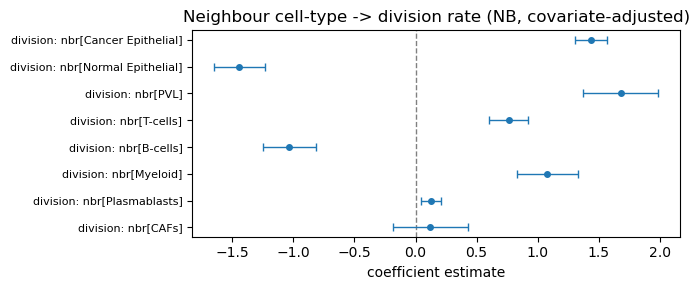

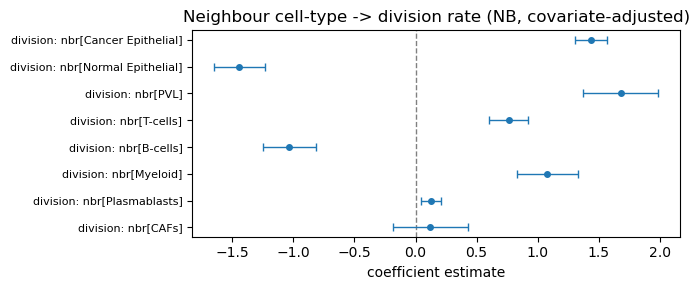

In [3]:
for pre, lab in [("own[", "OWN state"), ("nbr[", "NEIGHBOUR state")]:
    sub = coef[coef["term"].str.startswith(pre)].sort_values("abs_z", ascending=False)
    print("=== %s -> division rate (reference = Endothelial) ===" % lab)
    print(sub[["term", "estimate", "z", "p_value"]].head(10).to_string(index=False))
    print()

# reuse the fate-model forest plot: it needs a 'class' column
from tissue_dynamics import plot_coefficients
nbr_stats = coef[coef["term"].str.startswith("nbr[")].assign(**{"class": "division"})
fig, ax = plot_coefficients(nbr_stats, top_n=16,
                            title="Neighbour cell-type -> division rate (NB, covariate-adjusted)")
fig.tight_layout()
fig

### Does the neighbourhood add anything? — nested NB ladder

The OSDR question, in count form: fit the same NB model under each predictor
spec (all sharing the covariates and dispersion) and compare. The final line is
the strict test — does the neighbour block improve fit *beyond* own state and the
covariates?

In [4]:
import pandas as pd
from scipy.stats import chi2

rows = []
fits = {}
for spec in ["none", "own", "neighbor", "own+neighbor"]:
    f = fit_division_nb(bc, predictors=spec)
    fits[spec] = f
    rows.append({"spec": spec, "loglik": f["loglik"],
                 "state_pseudoR2_vs_cov": f["pseudo_r2_vs_covariates"],
                 "LR_df": f["lr_vs_covariate_only"]["df"],
                 "LR_p_vs_cov": f["lr_vs_covariate_only"]["p_value"]})
ladder = pd.DataFrame(rows)
print(ladder.to_string(index=False))

# incremental: neighbour beyond own + covariates
lr_inc = 2.0 * (fits["own+neighbor"]["loglik"] - fits["own"]["loglik"])
df_inc = fits["own+neighbor"]["n_params"] - fits["own"]["n_params"]
print("\nneighbourhood *beyond own state + covariates*:  LR chi2=%.1f  df=%d  p=%.1e"
      % (lr_inc, df_inc, chi2.sf(lr_inc, df_inc)))

        spec         loglik  state_pseudoR2_vs_cov  LR_df  LR_p_vs_cov
        none -623462.288075               0.000000      0          1.0
         own -611875.684049               0.017121      8          0.0
    neighbor -620463.442495               0.004602      8          0.0
own+neighbor -611287.391693               0.018094     16          0.0

neighbourhood *beyond own state + covariates*:  LR chi2=1176.6  df=8  p=1.1e-248


### Optional: the own × neighbour interaction (full-rank B)

`fit_division_nb(interaction_rank=...)` toggles the same bilinear
`phi^T B phi_bar` term as the fate model. `interaction_rank=None` adds the
**full dense B**: every `own[d] × nbr[e]` outer product becomes a design column
(`int[own × nbr]`), so the GLM stays linear in its parameters and the block
keeps valid likelihood-ratio inference. (`interaction_rank=0`, the default, is no
interaction; a *positive int* would request a low-rank `B = U Vᵀ`, which is
bilinear and not yet supported for the GLM — the API accepts it for a future
custom fitter.) The outer-product columns are highly collinear, so we judge the
interaction by its **block LR test**, not the per-term Wald p-values. This reuses
the no-interaction `fit` from above as the baseline.

In [ ]:
from scipy.stats import chi2

inter = fit_division_nb(bc, predictors="own+neighbor", interaction_rank=None)  # full dense B
n_int = sum(t.startswith("int[") for t in inter["coef"]["term"])
lr = 2.0 * (inter["loglik"] - fit["loglik"]); df = inter["n_params"] - fit["n_params"]
print("full-rank B adds %d interaction columns (own x neighbour) | NB alpha=%.3f | %d params total"
      % (n_int, inter["alpha"], inter["n_params"]))
print("loglik  no-interaction %.1f  ->  full interaction %.1f" % (fit["loglik"], inter["loglik"]))
print("interaction block LR:  chi2=%.1f  df=%d  p=%.1e" % (lr, df, chi2.sf(lr, df)))
print("pseudo-R2 vs covariates:  %.4f  ->  %.4f"
      % (fit["pseudo_r2_vs_covariates"], inter["pseudo_r2_vs_covariates"]))

ic = inter["coef"].copy(); ic["abs_z"] = ic["z"].abs()
print("\nstrongest interaction terms (collinear block -> read the LR above, not these p-values):")
print(ic[ic["term"].str.startswith("int[")].sort_values("abs_z", ascending=True)[
    ["term", "estimate", "z", "p_value"]].head(8).to_string(index=False))

full-rank B adds 64 interaction columns (own x neighbour) | NB alpha=0.705 | 83 params total
loglik  no-interaction -611287.4  ->  full interaction -609513.9
interaction block LR:  chi2=3546.9  df=64  p=0.0e+00
pseudo-R2 vs covariates:  0.0181  ->  0.0211

strongest interaction terms (collinear block -> read the LR above, not these p-values):


                                      term  estimate         z      p_value
          int[Cancer Epithelial x B-cells] -8.963178 -8.400149 4.459106e-17
int[Cancer Epithelial x Normal Epithelial] -6.684450 -6.116324 9.575840e-10
             int[CAFs x Cancer Epithelial] -7.755571 -5.608358 2.042557e-08
int[Cancer Epithelial x Cancer Epithelial] -3.753485 -5.086983 3.638036e-07
int[Normal Epithelial x Cancer Epithelial] -4.619418 -5.045096 4.532947e-07
                    int[T-cells x T-cells] -4.023786 -4.251003 2.128155e-05
                    int[Myeloid x Myeloid] -7.984740 -4.247419 2.162471e-05
          int[B-cells x Normal Epithelial]  7.892436  4.204396 2.617798e-05


## 8. Stepwise model selection from the full-interaction model

Section 7 showed the full model — own state + neighbour state + the full dense
own×neighbour interaction `B` + the technical covariates (83 parameters). Which
of those terms are actually worth keeping? `stepwise_division_nb` does **backward
elimination** from that full model.

At n ≈ 680k every term is "significant" by p-value, so selection is by **BIC**
(complexity penalty `ln(n) ≈ 13.4` per parameter — far stricter than AIC's 2, and
the right choice at this sample size). Each step drops the eligible term with the
smallest Wald |z| and refits, stopping when no single removal lowers BIC. Two
guardrails: the **technical covariates are protected** (confounder controls, never
dropped), and **marginality** is respected (a main effect isn't dropped while an
interaction involving that cell type survives). The path is fit at a fixed NB
dispersion with a fast p×p IRLS (`_nb2_irls`), so the whole search is ~2 min
rather than the hours a naïve per-candidate statsmodels refit would take. Reuses
`bc` from Section 7.

full model     : 83 params   BIC = 1220143
selected model : 45 params   BIC = 1219752   (dropped 38 terms; NB alpha=0.705)
  own state                kept  8 /  8
  neighbour state          kept  8 /  8
  interaction              kept 26 / 64
  covariates (protected)   kept  2 /  2


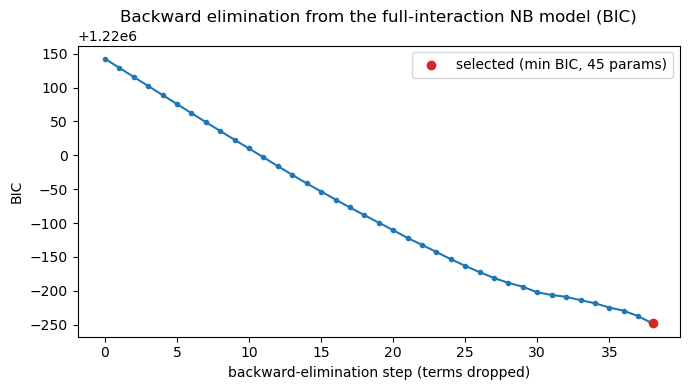

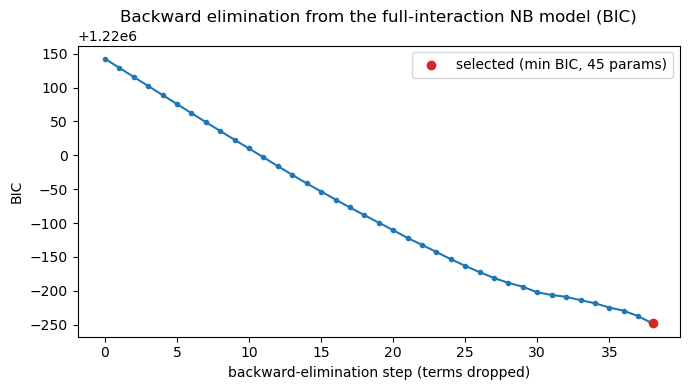

In [2]:
from tissue_dynamics import stepwise_division_nb

sel = stepwise_division_nb(bc, criterion="bic")     # backward from the full 83-param model (~2 min)
path = sel["path"]
full_row = path.iloc[0]
print("full model     : %2d params   BIC = %.0f" % (full_row["n_params"], full_row["bic"]))
print("selected model : %2d params   BIC = %.0f   (dropped %d terms; NB alpha=%.3f)"
      % (sel["n_params"], path["bic"].min(), len(sel["dropped_terms"]), sel["alpha"]))

kept = set(sel["selected_terms"])
for pre, total, lab in [("own[", 8, "own state"), ("nbr[", 8, "neighbour state"),
                        ("int[", 64, "interaction"), ("", 2, "covariates (protected)")]:
    if pre == "":
        k = sum(t in ("log_total_counts", "local_density") for t in kept)
    else:
        k = sum(t.startswith(pre) for t in kept)
    print("  %-24s kept %2d / %2d" % (lab, k, total))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(path["step"], path["bic"], "-o", ms=3)
imin = path["bic"].idxmin()
ax.scatter([path.loc[imin, "step"]], [path.loc[imin, "bic"]], color="C3", zorder=5,
           label="selected (min BIC, %d params)" % int(path.loc[imin, "n_params"]))
ax.set_xlabel("backward-elimination step (terms dropped)"); ax.set_ylabel("BIC")
ax.set_title("Backward elimination from the full-interaction NB model (BIC)")
ax.legend(); fig.tight_layout()
fig

### What survived

The main effects and covariates all stay; selection acts almost entirely on the
collinear interaction block, keeping the informative own×neighbour pairs and
discarding the rest. (Because the surviving interaction columns remain
correlated with the main effects, the individual coefficient *magnitudes* in the
selected model are inflated/unstable — read this table as *which* terms were
retained, and lean on the fate-model and Section-7 main-effect estimates for
effect sizes.)

In [3]:
kept_int = [t[len("int["):-1] for t in sel["selected_terms"] if t.startswith("int[")]
drop_int = [t[len("int["):-1] for t in sel["dropped_terms"] if t.startswith("int[")]
print("kept interactions (%d):\n  %s" % (len(kept_int), ", ".join(kept_int)))
print("\ndropped interactions (%d):\n  %s" % (len(drop_int), ", ".join(drop_int)))

# covariates + main effects in the selected model
c = sel["coef"].copy(); c["abs_z"] = c["z"].abs()
main = c[c["term"].isin(["const", "log_total_counts", "local_density"])
        | c["term"].str.startswith(("own[", "nbr["))]
print("\ncovariates + own/neighbour main effects (selected model):")
print(main.sort_values("abs_z", ascending=False)[
    ["term", "estimate", "z", "p_value"]].to_string(index=False))

kept interactions (26):
  CAFs x Myeloid, CAFs x Cancer Epithelial, PVL x T-cells, PVL x Normal Epithelial, PVL x Cancer Epithelial, B-cells x B-cells, B-cells x T-cells, B-cells x Normal Epithelial, T-cells x T-cells, T-cells x Normal Epithelial, Myeloid x Myeloid, Myeloid x Plasmablasts, Myeloid x Cancer Epithelial, Normal Epithelial x Myeloid, Normal Epithelial x Normal Epithelial, Normal Epithelial x Cancer Epithelial, Plasmablasts x CAFs, Plasmablasts x B-cells, Plasmablasts x Myeloid, Plasmablasts x Normal Epithelial, Cancer Epithelial x CAFs, Cancer Epithelial x B-cells, Cancer Epithelial x T-cells, Cancer Epithelial x Normal Epithelial, Cancer Epithelial x Plasmablasts, Cancer Epithelial x Cancer Epithelial

dropped interactions (38):
  CAFs x CAFs, CAFs x PVL, CAFs x B-cells, CAFs x T-cells, CAFs x Normal Epithelial, CAFs x Plasmablasts, PVL x CAFs, PVL x PVL, PVL x B-cells, PVL x Myeloid, PVL x Plasmablasts, B-cells x CAFs, B-cells x PVL, B-cells x Myeloid, B-cells x Plasmabl

## 9. A refined rate model, and where it fails in space

Three changes to how the NB division model treats the technical nuisances, each
matching the variable's role:

- **Library size → offset.** `offset_key="log_total_counts"` fixes its
  coefficient at 1, so the model explains the cell-cycle transcript *rate* per
  captured transcript rather than fitting a free depth slope. (This is the
  classic exposure/rate formulation.)
- **Local density → spline.** `spline_keys=("local_density",)` enters density as
  a smooth natural-cubic spline, so a nonlinear density effect (e.g. saturation
  at high density) isn't forced into a single slope.
- **Cell area → free covariate.** `covariate_keys=("cell_area",)` — larger
  segmented cells capture more transcripts and may segment differently, so we
  control for it linearly.

Then a spatial diagnostic: bin the slide into ~100 µm tiles and compare the
**observed** division signal, the **model's estimate**, and the **normalised
residuals** over space — and quantify any leftover spatial structure with
**Moran's I**. Reuses `bc` from the sections above.

In [2]:
from tissue_dynamics import fit_division_nb, get_signature_counts

fit = fit_division_nb(bc, predictors="own+neighbor",
                      offset_key="log_total_counts",     # library size as a rate offset
                      spline_keys=("local_density",), spline_df=5,   # density as a spline
                      covariate_keys=("cell_area",))     # cell area as a free covariate
print("NB dispersion alpha=%.3f | n=%d | offset=%s" % (fit["alpha"], fit["n"], fit["offset_key"]))
lr = fit["lr_vs_covariate_only"]
print("LR  state vs nuisance-only (offset+density-spline+area):  chi2=%.0f  df=%d  p=%.1e"
      % (lr["statistic"], lr["df"], lr["p_value"]))

c = fit["coef"].copy()
print("\ndensity spline basis + cell area (nuisance coefficients):")
print(c[c["term"].str.startswith(("spline[", "cell_area"))][
    ["term", "estimate", "z", "p_value"]].to_string(index=False))
print("\nown/neighbour rate effects (top by |z|):")
c["abs_z"] = c["z"].abs()
print(c[c["term"].str.startswith(("own[", "nbr["))].sort_values("abs_z", ascending=False)[
    ["term", "estimate", "z", "p_value"]].head(8).to_string(index=False))

NB dispersion alpha=0.773 | n=680206 | offset=log_total_counts
LR  state vs nuisance-only (offset+density-spline+area):  chi2=21113  df=16  p=0.0e+00

density spline basis + cell area (nuisance coefficients):


                   term  estimate         z      p_value
spline[local_density]_1 -0.343095 -5.036999 4.728879e-07
spline[local_density]_2 -0.187463 -2.746740 6.019080e-03
spline[local_density]_3 -0.211333 -3.119250 1.813122e-03
spline[local_density]_4 -0.222350 -3.247924 1.162502e-03
spline[local_density]_5 -0.334862 -3.608958 3.074299e-04
              cell_area -0.017983 -6.076776 1.226229e-09

own/neighbour rate effects (top by |z|):


                  term  estimate          z       p_value
          own[T-cells]  1.576884  64.783635  0.000000e+00
own[Cancer Epithelial]  1.197914  55.631825  0.000000e+00
          own[B-cells]  1.446879  47.179582  0.000000e+00
             own[CAFs] -1.411749 -33.076684 6.432554e-240
nbr[Cancer Epithelial]  1.479294  21.182421  1.387177e-99
     own[Plasmablasts]  0.248651  16.277703  1.421046e-59
nbr[Normal Epithelial] -1.522497 -14.138911  2.186415e-45
              nbr[PVL]  1.573485   9.674829  3.857368e-22


### Ground truth vs model estimate vs residuals, over space (100 µm tiles)

The model attaches per-cell predictions: `prob_division` = P(≥1 cell-cycle
transcript) under the fitted NB, and `pearson_resid` = the NB2 normalised
residual `(y − μ)/√(μ + αμ²)`. We bin cells into 100 µm tiles and average each.
Ground truth is the observed fraction of cells in a tile with ≥1 cell-cycle
transcript — directly comparable to the model's mean `prob_division`.

11844 tiles (>=5 cells) at 100 um | observed mean=0.267  model mean=0.258  (well calibrated)


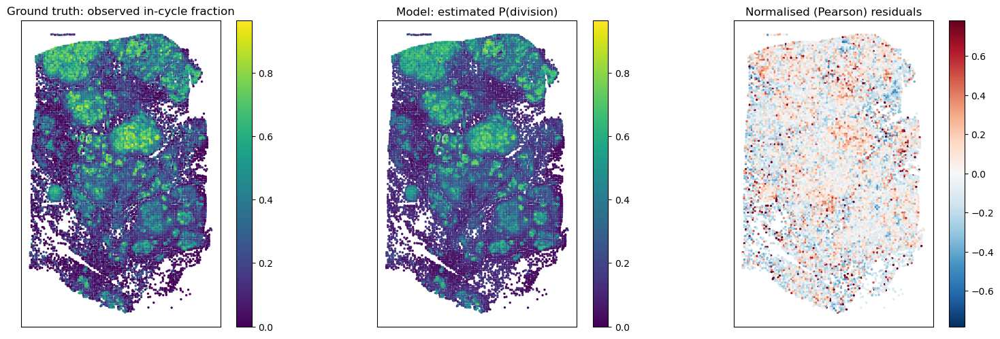

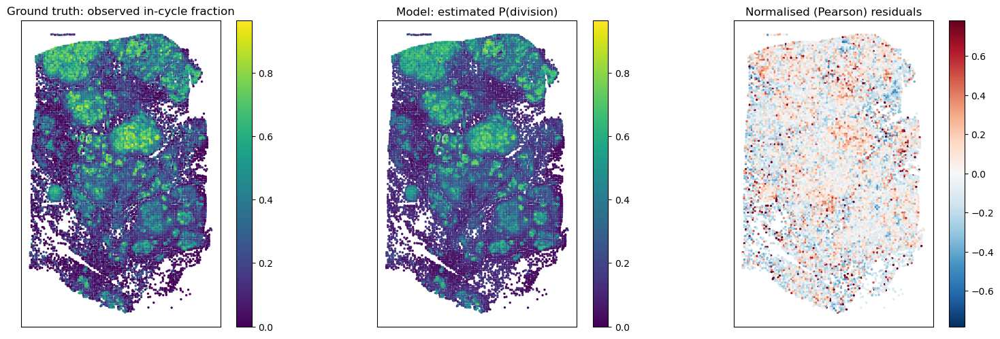

In [3]:
from tissue_dynamics import assign_tiles, aggregate_tiles

y_div, _tot, _ = get_signature_counts(bc, list(fit["genes"]))
bc.obs["obs_incycle"]   = (y_div >= 1).astype(float)   # ground-truth division indicator
bc.obs["pred_prob_div"] = fit["prob_division"]         # model estimate
bc.obs["pearson_resid"] = fit["pearson_resid"]         # normalised residual

assign_tiles(bc, tile_size=100.0)
tiles = aggregate_tiles(bc, phi_key=None,
                        obs_means=["obs_incycle", "pred_prob_div", "pearson_resid"], min_cells=5)
print("%d tiles (>=5 cells) at 100 um | observed mean=%.3f  model mean=%.3f  (well calibrated)"
      % (len(tiles), tiles["obs_incycle_mean"].mean(), tiles["pred_prob_div_mean"].mean()))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
vmax = max(tiles["obs_incycle_mean"].max(), tiles["pred_prob_div_mean"].max())
for ax, col, title in [(axes[0], "obs_incycle_mean", "Ground truth: observed in-cycle fraction"),
                       (axes[1], "pred_prob_div_mean", "Model: estimated P(division)")]:
    sc = ax.scatter(tiles["x"], tiles["y"], c=tiles[col], s=6, cmap="viridis",
                    vmin=0, vmax=vmax, linewidths=0)
    fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(title)
rlim = float(np.nanpercentile(np.abs(tiles["pearson_resid_mean"]), 99))
sc = axes[2].scatter(tiles["x"], tiles["y"], c=tiles["pearson_resid_mean"], s=6,
                     cmap="RdBu_r", vmin=-rlim, vmax=rlim, linewidths=0)
fig.colorbar(sc, ax=axes[2], fraction=0.046, pad=0.04)
axes[2].set_title("Normalised (Pearson) residuals")
for ax in axes:
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
fig

### Moran's I on the residuals

Moran's I measures whether nearby tiles carry similar values (spatial
autocorrelation). On the **observed** signal it should be large (proliferation
is regionally clustered); on the **residuals** it tells us how much of that
spatial structure the model *failed* to explain — a residual I near the null
`E[I] = −1/(n−1)` would mean the cell-state model already accounts for the
spatial pattern.

In [4]:
from tissue_dynamics import morans_i

coords = tiles[["x", "y"]].to_numpy()
mi_obs = morans_i(tiles["obs_incycle_mean"].to_numpy(),   coords=coords, n_neighbors=8, permutations=999)
mi_res = morans_i(tiles["pearson_resid_mean"].to_numpy(), coords=coords, n_neighbors=8, permutations=999)
print("Moran's I on 100 um tiles (8-nearest-neighbour weights, 999 permutations):")
print("  observed in-cycle : I=%+.3f   E[I]=%.4f   z=%6.1f   p=%.4f"
      % (mi_obs["I"], mi_obs["expected_I"], mi_obs["z_score"], mi_obs["p_value"]))
print("  model residuals   : I=%+.3f   E[I]=%.4f   z=%6.1f   p=%.4f"
      % (mi_res["I"], mi_res["expected_I"], mi_res["z_score"], mi_res["p_value"]))
print("\n=> the model removes %.0f%% of the observed spatial autocorrelation, but a small,"
      % (100 * (1 - mi_res["I"] / mi_obs["I"])))
print("   still-significant residual clustering remains (structure not captured by own+neighbour state).")

Moran's I on 100 um tiles (8-nearest-neighbour weights, 999 permutations):
  observed in-cycle : I=+0.685   E[I]=-0.0001   z= 151.1   p=0.0010
  model residuals   : I=+0.083   E[I]=-0.0001   z=  18.5   p=0.0010

=> the model removes 88% of the observed spatial autocorrelation, but a small,
   still-significant residual clustering remains (structure not captured by own+neighbour state).


## 10. Adding the own × neighbour interaction to the rate model

The Section-9 rate model (library-size offset, density spline, cell-area
covariate) with the **full dense interaction `B`** switched on
(`interaction_rank=None`) — every `own[d] × nbr[e]` outer product as a design
column. Two things to read off: is the interaction block worth it (LR test), and
does it soak up any of the **residual spatial autocorrelation** Section 9 left on
the table (Moran's I 0.083)?

Note this design is wide (~87 parameters), so `fit_division_nb` automatically
switches to its memory-efficient normal-equations IRLS fitter (`fitter="auto"`)
— statsmodels' SVD over the 680k-row design would otherwise run out of memory.
Reuses `bc` and the no-interaction rate model `fit` from Section 9.

In [2]:
from scipy.stats import chi2

RATE = dict(offset_key="log_total_counts", spline_keys=("local_density",), spline_df=5,
            covariate_keys=("cell_area",))
fit_int = fit_division_nb(bc, predictors="own+neighbor", interaction_rank=None, **RATE)

print("fitter used: %s | params %d -> %d | NB alpha=%.3f"
      % (fit_int["fitter"], fit["n_params"], fit_int["n_params"], fit_int["alpha"]))
lr = 2.0 * (fit_int["loglik"] - fit["loglik"]); df = fit_int["n_params"] - fit["n_params"]
print("interaction block LR (vs no-interaction rate model): chi2=%.0f  df=%d  p=%.1e"
      % (lr, df, chi2.sf(lr, df)))
print("pseudo-R2 vs nuisance:  no-int %.4f  ->  +interaction %.4f"
      % (fit["pseudo_r2_vs_covariates"], fit_int["pseudo_r2_vs_covariates"]))

c = fit_int["coef"].copy(); c["abs_z"] = c["z"].abs()
print("\nstrongest interaction terms (collinear block -> judged by the block LR, not these z):")
print(c[c["term"].str.startswith("int[")].sort_values("abs_z", ascending=False)[
    ["term", "estimate", "z"]].head(8).to_string(index=False))

fitter used: irls | params 23 -> 87 | NB alpha=0.716
interaction block LR (vs no-interaction rate model): chi2=3897  df=64  p=0.0e+00
pseudo-R2 vs nuisance:  no-int 0.0170  ->  +interaction 0.0204

strongest interaction terms (collinear block -> judged by the block LR, not these z):
                                      term  estimate         z
          int[Cancer Epithelial x B-cells] -9.775903 -9.098405
int[Cancer Epithelial x Normal Epithelial] -6.938478 -6.321199
             int[CAFs x Cancer Epithelial] -7.449180 -5.546947
int[Cancer Epithelial x Cancer Epithelial] -4.051317 -5.448002
int[Normal Epithelial x Cancer Epithelial] -4.731127 -5.162618
                    int[T-cells x T-cells] -4.495637 -4.705124
     int[Cancer Epithelial x Plasmablasts] -2.344109 -4.531778
                    int[Myeloid x Myeloid] -8.148626 -4.324537


### Does the interaction explain more of the spatial structure?

Same three spatial panels as Section 9 but for the interaction model, and Moran's
I on the residuals **with vs without** the interaction term.

Moran's I on 100 um tiles (8-NN, 999 permutations):
  observed in-cycle          I=+0.685   z= 151.1   p=0.0010


  residuals, no interaction  I=+0.083   z=  18.5   p=0.0010
  residuals, + interaction   I=+0.071   z=  15.7   p=0.0010


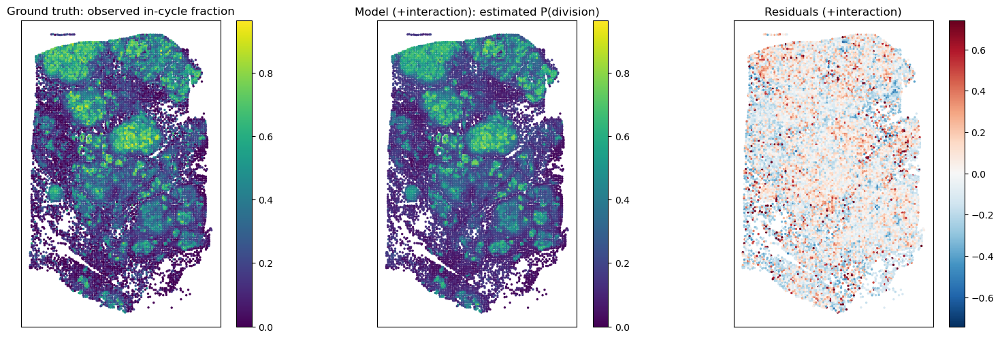

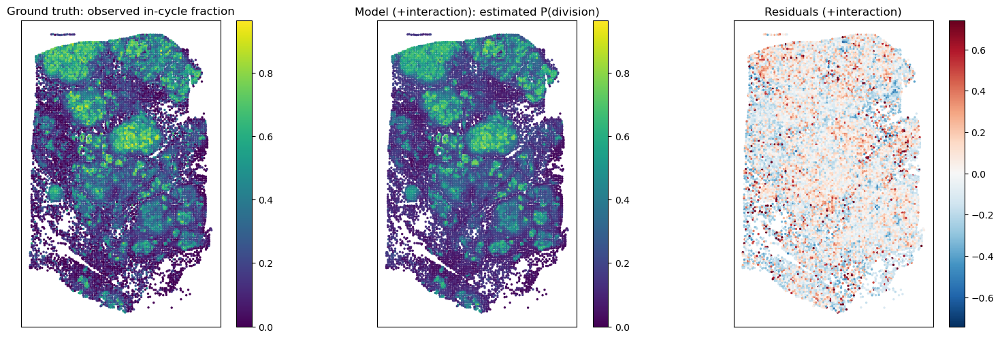

In [3]:
from tissue_dynamics import assign_tiles, aggregate_tiles, morans_i

bc.obs["pred_int"]  = fit_int["prob_division"]
bc.obs["resid_int"] = fit_int["pearson_resid"]

assign_tiles(bc, tile_size=100.0)
tiles = aggregate_tiles(bc, phi_key=None,
                        obs_means=["obs_incycle", "pred_int", "pearson_resid", "resid_int"],
                        min_cells=5)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
vmax = max(tiles["obs_incycle_mean"].max(), tiles["pred_int_mean"].max())
for ax, col, title in [(axes[0], "obs_incycle_mean", "Ground truth: observed in-cycle fraction"),
                       (axes[1], "pred_int_mean", "Model (+interaction): estimated P(division)")]:
    sc = ax.scatter(tiles["x"], tiles["y"], c=tiles[col], s=6, cmap="viridis",
                    vmin=0, vmax=vmax, linewidths=0)
    fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04); ax.set_title(title)
rlim = float(np.nanpercentile(np.abs(tiles["resid_int_mean"]), 99))
sc = axes[2].scatter(tiles["x"], tiles["y"], c=tiles["resid_int_mean"], s=6,
                     cmap="RdBu_r", vmin=-rlim, vmax=rlim, linewidths=0)
fig.colorbar(sc, ax=axes[2], fraction=0.046, pad=0.04)
axes[2].set_title("Residuals (+interaction)")
for ax in axes:
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

coords = tiles[["x", "y"]].to_numpy()
print("Moran's I on 100 um tiles (8-NN, 999 permutations):")
for label, col in [("observed in-cycle", "obs_incycle_mean"),
                   ("residuals, no interaction", "pearson_resid_mean"),
                   ("residuals, + interaction", "resid_int_mean")]:
    mi = morans_i(tiles[col].to_numpy(), coords=coords, n_neighbors=8, permutations=999)
    print("  %-26s I=%+.3f   z=%6.1f   p=%.4f" % (label, mi["I"], mi["z_score"], mi["p_value"]))
fig

## 11. Goodness of fit: rootogram and PIT histogram

Two standard checks that the negative-binomial actually fits the count
distribution of the rate model (Section 9) — they answer complementary
questions:

- **Hanging rootogram** — observed vs model-expected count frequencies on a
  √ scale. Bars hang from the fitted curve; a bar dipping *below* the zero line
  means that count is **under-predicted** (more cells than the NB expects), one
  stopping *above* means **over-predicted**. Good for spotting shape/tail misfit.
- **Non-randomized PIT histogram** — a calibration check. Uniform bars ⇒ the
  predictive distribution is well calibrated; a U-shape ⇒ too narrow
  (under-dispersed), a central hump ⇒ too wide (over-dispersed), a tilt ⇒
  biased mean.

Both are computed from the per-cell fitted means (`fit["fitted_mu"]`) and the NB
dispersion `fit["alpha"]`. Reuses the Section-9 rate model `fit`.

NB dispersion alpha = 0.773
PIT: max |height - 1| = 0.049  (near 0 => well calibrated; heights=[0.95 0.97 1.01 1.03 1.03 1.02 1.01 1.   0.98 1.  ])
rootogram: most under-predicted count = 1 (obs-exp=+12504 cells); model over-predicts counts 5-9


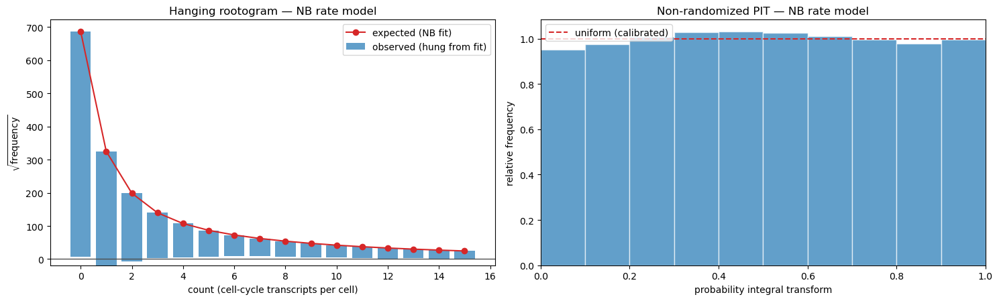

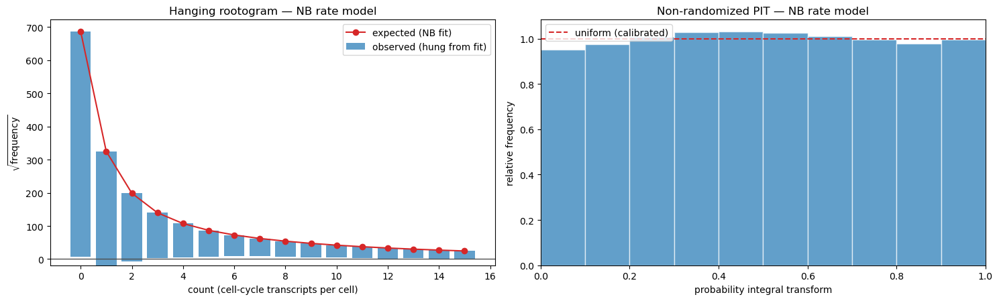

In [2]:
from tissue_dynamics import plot_rootogram, plot_pit_histogram
from tissue_dynamics.plotting import _rootogram_counts, _pit_histogram

y_div, _tot, _ = get_signature_counts(bc, list(fit["genes"]))
mu, alpha = fit["fitted_mu"], fit["alpha"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
plot_rootogram(y_div, mu, alpha, ax=axes[0], max_count=15,
               title="Hanging rootogram — NB rate model")
plot_pit_histogram(y_div, mu, alpha, ax=axes[1], n_bins=10,
                   title="Non-randomized PIT — NB rate model")
fig.tight_layout()

# quantify what the eyes see
_ks, obs, exp = _rootogram_counts(y_div, mu, alpha, max_count=15)
disc = np.sqrt(obs) - np.sqrt(exp)
_edges, heights = _pit_histogram(y_div, mu, alpha, n_bins=10)
print("NB dispersion alpha = %.3f" % alpha)
print("PIT: max |height - 1| = %.3f  (near 0 => well calibrated; heights=%s)"
      % (np.max(np.abs(heights - 1)), np.round(heights, 2)))
print("rootogram: most under-predicted count = %d (obs-exp=%+d cells);"
      " model over-predicts counts %d-%d"
      % (int(_ks[np.argmax(disc)]), int((obs - exp)[np.argmax(disc)]), 5, 9))
fig

## 12. Reparameterising the neighbour state as `phi_bar − phi`

Own state (`phi`) and neighbour state (`phi_bar`) are correlated — nearby cells
resemble each other — which inflates and entangles their coefficients. A natural
idea to break that is to represent the neighbourhood by its **deviation from the
cell**, `phi_bar − phi` (`neighbour_contrast=True`), and ask whether the
neighbourhood *differs* from the cell rather than its absolute state. For the
main-effects model this is an exact reparameterisation (same fit), so if it
lowered the collinearity it would be a free win. Does it?

In [2]:
phi, phibar = bc.obsm["phi"], bc.obsm["phi_bar"]
sub = np.random.default_rng(0).choice(phi.shape[0], 100_000, replace=False)   # for the SVD

def zcond(M):                                  # condition number of the standardized design
    return np.linalg.cond((M - M.mean(0)) / M.std(0))

print("Var(phi_bar)/Var(phi) per dim: %s" % np.round(phibar.var(0) / phi.var(0), 2))
print("  -> mean %.2f  (neighbourhood averaging smooths phi_bar to ~40%% the variance of phi)"
      % (phibar.var(0).mean() / phi.var(0).mean()))
print("\nown+neighbour design condition number (100k-cell subsample):")
print("  raw      [phi | phi_bar]      cond = %.0f" % zcond(np.column_stack([phi[sub], phibar[sub]])))
print("  contrast [phi | phi_bar-phi]  cond = %.0f" % zcond(np.column_stack([phi[sub], (phibar - phi)[sub]])))
onc = np.mean([np.corrcoef(phi[:, i], phibar[:, i])[0, 1] for i in range(phi.shape[1])])
odc = np.mean([np.corrcoef(phi[:, i], (phibar - phi)[:, i])[0, 1] for i in range(phi.shape[1])])
print("  mean corr(own_i, neighbour_i):   raw %+.3f  ->  contrast %+.3f" % (onc, odc))

# main-effects rate model: raw vs contrast is an exact reparameterisation.
# Fit one at a time and free each to keep memory low.
m = fit_division_nb(bc, predictors="own+neighbor", **RATE)
ll_raw = m["loglik"]; rc = m["coef"].set_index("term")["estimate"].copy(); del m; gc.collect()
m = fit_division_nb(bc, predictors="own+neighbor", neighbour_contrast=True, **RATE)
ll_con = m["loglik"]; cc = m["coef"].set_index("term")["estimate"].copy(); del m; gc.collect()

print("\nmain-effects loglik:  raw %.1f   contrast %.1f   (identical -> exact reparam)" % (ll_raw, ll_con))
tab = pd.DataFrame({"own_raw":  [rc[f"own[{n}]"] for n in bc.uns["phi_names"]],
                    "nbr_raw":  [rc[f"nbr[{n}]"] for n in bc.uns["phi_names"]],
                    "own_contrast": [cc[f"own[{n}]"] for n in bc.uns["phi_names"]],
                    "nbr_dev":  [cc[f"nbr_dev[{n}]"] for n in bc.uns["phi_names"]]},
                   index=bc.uns["phi_names"])
print("\n(own_contrast = own_raw + nbr_raw;  nbr_dev = nbr_raw — the reparam identity)")
print(tab.round(3).to_string())

Var(phi_bar)/Var(phi) per dim: [0.41 0.4  0.4  0.39 0.4  0.34 0.4  0.43]
  -> mean 0.40  (neighbourhood averaging smooths phi_bar to ~40% the variance of phi)

own+neighbour design condition number (100k-cell subsample):
  raw      [phi | phi_bar]      cond = 136
  contrast [phi | phi_bar-phi]  cond = 275
  mean corr(own_i, neighbour_i):   raw +0.671  ->  contrast -0.776



main-effects loglik:  raw -611864.0   contrast -611865.3   (identical -> exact reparam)

(own_contrast = own_raw + nbr_raw;  nbr_dev = nbr_raw — the reparam identity)
                   own_raw  nbr_raw  own_contrast  nbr_dev
CAFs                -1.412    0.559        -0.852    0.560
PVL                  0.121    1.573         1.694    1.573
B-cells              1.447   -0.738         0.709   -0.738
T-cells              1.577    0.732         2.309    0.733
Myeloid             -0.114    0.791         0.677    0.790
Normal Epithelial    0.128   -1.522        -1.394   -1.522
Plasmablasts         0.249    0.096         0.344    0.096
Cancer Epithelial    1.198    1.479         2.677    1.479


**It does not decorrelate them here — it makes it slightly worse.** Because
`phi_bar` is a neighbourhood *average*, it has only ~40% the variance of `phi`
(a smoothed version of it), so `phi_bar − phi` is dominated by the `−phi` term
and ends up *more* correlated with own state (corr magnitude 0.67 → 0.78, cond
136 → 274). The textbook decorrelation assumes own and neighbour have similar
variance; neighbourhood averaging breaks that assumption. The fit is unchanged
(exact reparam) so nothing is lost — but the hoped-for benefit doesn't
materialise. (A reparam that *would* orthogonalise is the regression residual of
`phi_bar` on `phi`; `phi_bar − phi` is the interpretable, not the orthogonal,
choice.)

Where the contrast form does help is the **interaction**: `phi ⊗ (phi_bar − phi)`
is a different, less collinear column space than `phi ⊗ phi_bar`.

In [3]:
i_raw = fit_division_nb(bc, predictors="own+neighbor", interaction_rank=None, **RATE)
ll_raw = i_raw["loglik"]
mag_raw = i_raw["coef"].set_index("term").filter(like="int[", axis=0)["estimate"].abs()
bc.obs["resid_raw"] = i_raw["pearson_resid"]; del i_raw; gc.collect()

i_con = fit_division_nb(bc, predictors="own+neighbor", interaction_rank=None,
                        neighbour_contrast=True, **RATE)
mag_con = i_con["coef"].set_index("term").filter(like="int[", axis=0)["estimate"].abs()
bc.obs["resid_con"] = i_con["pearson_resid"]

print("interaction rate model loglik:  raw %.1f   contrast %.1f" % (ll_raw, i_con["loglik"]))
print("interaction coefficient magnitude:  max %.1f -> %.1f    mean %.2f -> %.2f  (less inflated)"
      % (mag_raw.max(), mag_con.max(), mag_raw.mean(), mag_con.mean()))

assign_tiles(bc, tile_size=100.0)
tiles = aggregate_tiles(bc, phi_key=None, obs_means=["resid_raw", "resid_con"], min_cells=5)
coords = tiles[["x", "y"]].to_numpy()
mi_raw = morans_i(tiles["resid_raw_mean"].to_numpy(), coords=coords, permutations=999)
mi_con = morans_i(tiles["resid_con_mean"].to_numpy(), coords=coords, permutations=999)
print("residual Moran's I (100um tiles):  raw-interaction %.3f   contrast-interaction %.3f"
      % (mi_raw["I"], mi_con["I"]))
print("\nNote: phi (x) (phi_bar - phi) implicitly adds own x own (phi (x) phi) terms, so the"
      "\ncontrast interaction's better loglik is partly own-state curvature, not a pure reparam.")

interaction rate model loglik:  raw -609915.6   contrast -607742.7
interaction coefficient magnitude:  max 9.8 -> 5.5    mean 3.22 -> 1.87  (less inflated)


residual Moran's I (100um tiles):  raw-interaction 0.071   contrast-interaction 0.094

Note: phi (x) (phi_bar - phi) implicitly adds own x own (phi (x) phi) terms, so the
contrast interaction's better loglik is partly own-state curvature, not a pure reparam.


## 13. Adjusting for ambient background from control-probe counts

Xenium carries negative-control features (probes/codewords with no biological
target) that measure non-specific background. We define a per-cell **ambient
fraction** over the 500 µm neighbourhood N^amb_i:

$$\tilde{\pi}_i = \frac{\sum_{j\in N^{amb}_i} u_j}{\sum_{j\in N^{amb}_i} (m_j+u_j)}$$

where $u_j$ = control-probe counts and $m_j$ = total gene counts, and add
**$\log\tilde\pi_i$** as a covariate. Two implementation notes: (1) the
negative-control *probes alone* are extremely sparse here (816 counts slide-wide,
0.1% of cells), so aggregating them over 500 µm still leaves ~6% of neighbourhoods
empty — we therefore sum **all** negative controls (probe + genomic + codeword)
for a stable background estimate; (2) a 500 µm neighbourhood holds thousands of
cells, so an exact radius graph would have billions of edges — the sums are
computed by binning to a 25 µm grid and disk-convolving (`compute_ambient_background`).

control features summed: ['control_probe_counts', 'genomic_control_counts', 'control_codeword_counts']
ambient fraction pi_tilde: median=1.52e-04   log_ambient_pi: mean=-8.70 sd=0.46  (0.06% neighbourhoods empty)
correlation with existing covariates:  log_total_counts -0.28   local_density -0.25   cell_area +0.02



Moran's I of the ambient field (100um tiles): I=0.936  z=203  (a strong, smooth background gradient)


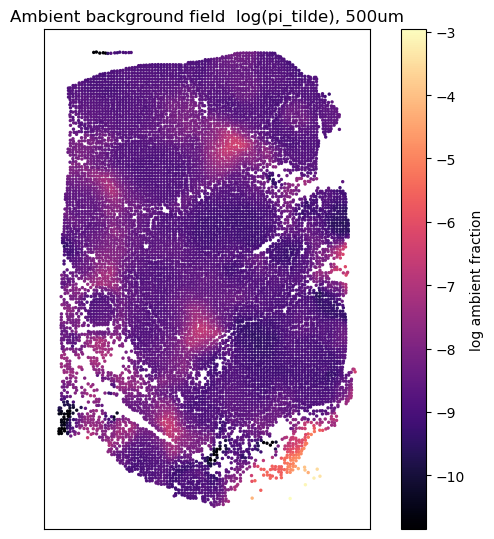

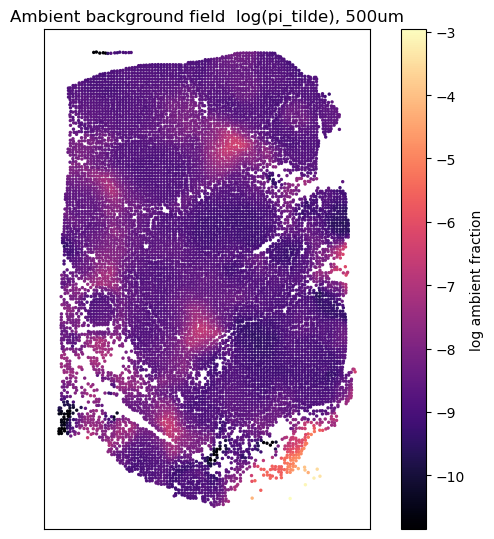

In [2]:
lp = bc.obs["log_ambient_pi"].to_numpy()
print("control features summed:", bc.uns["control_count_columns"])
print("ambient fraction pi_tilde: median=%.2e   log_ambient_pi: mean=%.2f sd=%.2f  (%.2f%% neighbourhoods empty)"
      % (np.median(bc.obs["ambient_pi"]), lp.mean(), lp.std(), 100*(bc.obs["ambient_pi"] == 0).mean()))
print("correlation with existing covariates:  log_total_counts %+.2f   local_density %+.2f   cell_area %+.2f"
      % (np.corrcoef(lp, bc.obs["log_total_counts"])[0,1], np.corrcoef(lp, bc.obs["local_density"])[0,1],
         np.corrcoef(lp, bc.obs["cell_area"])[0,1]))

assign_tiles(bc, tile_size=100.0)
tiles = aggregate_tiles(bc, phi_key=None, obs_means=["log_ambient_pi"], min_cells=5)
mi = morans_i(tiles["log_ambient_pi_mean"].to_numpy(), coords=tiles[["x","y"]].to_numpy(), permutations=999)
print("\nMoran's I of the ambient field (100um tiles): I=%.3f  z=%.0f  (a strong, smooth background gradient)"
      % (mi["I"], mi["z_score"]))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter(tiles["x"], tiles["y"], c=tiles["log_ambient_pi_mean"], s=6, cmap="magma", linewidths=0)
fig.colorbar(sc, ax=ax, label="log ambient fraction")
ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Ambient background field  log(pi_tilde), 500um")
fig.tight_layout()
fig

### Add it to the model and check the diagnostics

Fit the rate model with and without `log_ambient_pi`, then a rootogram / PIT and
the spatial residuals.

In [3]:
m0 = fit_division_nb(bc, predictors="own+neighbor", covariate_keys=("cell_area",), **BASE)
ll0, np0 = m0["loglik"], m0["n_params"]; bc.obs["resid0"] = m0["pearson_resid"]; del m0; gc.collect()

m1 = fit_division_nb(bc, predictors="own+neighbor", covariate_keys=("cell_area", "log_ambient_pi"), **BASE)
bc.obs["resid1"] = m1["pearson_resid"]
row = m1["coef"].set_index("term").loc["log_ambient_pi"]
print("log_ambient_pi coefficient (per SD):  est=%+.3f   z=%+.1f   p=%.3f" % (row["estimate"], row["z"], row["p_value"]))
lr = 2*(m1["loglik"] - ll0); dfree = m1["n_params"] - np0
print("adding the covariate:  dLL=%.1f   LR chi2=%.1f  df=%d  p=%.3f" % (m1["loglik"]-ll0, lr, dfree, chi2.sf(lr, dfree)))

y_div, _t, _ = get_signature_counts(bc, list(m1["genes"]))
bc.obs["obs_incycle"] = (y_div >= 1).astype(float)
tl = aggregate_tiles(bc, phi_key=None, obs_means=["resid0", "resid1"], min_cells=5)  # tiles already assigned
co = tl[["x","y"]].to_numpy()
print("\nresidual Moran's I (100um tiles):  without ambient %.4f   with ambient %.4f"
      % (morans_i(tl["resid0_mean"].to_numpy(), coords=co, permutations=499)["I"],
         morans_i(tl["resid1_mean"].to_numpy(), coords=co, permutations=499)["I"]))

log_ambient_pi coefficient (per SD):  est=+0.003   z=+0.8   p=0.439
adding the covariate:  dLL=1.9   LR chi2=3.8  df=1  p=0.051



residual Moran's I (100um tiles):  without ambient 0.0832   with ambient 0.0830


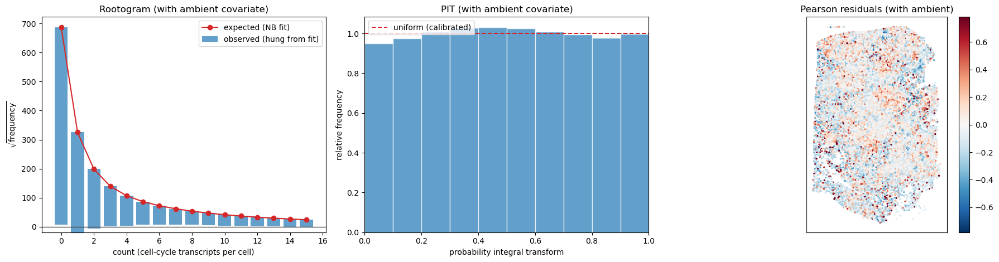

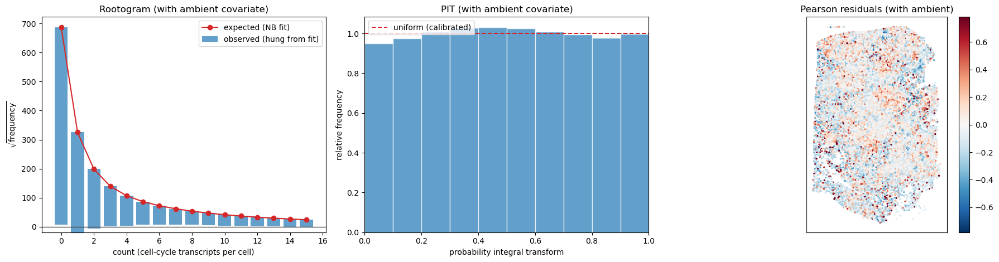

In [4]:
# goodness-of-fit + spatial residuals for the ambient-adjusted model
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
plot_rootogram(y_div, m1["fitted_mu"], m1["alpha"], ax=axes[0], max_count=15,
               title="Rootogram (with ambient covariate)")
plot_pit_histogram(y_div, m1["fitted_mu"], m1["alpha"], ax=axes[1], n_bins=10,
                   title="PIT (with ambient covariate)")
tr = aggregate_tiles(bc, phi_key=None, obs_means=["resid1"], min_cells=5)
rlim = float(np.nanpercentile(np.abs(tr["resid1_mean"]), 99))
sc = axes[2].scatter(tr["x"], tr["y"], c=tr["resid1_mean"], s=6, cmap="RdBu_r",
                     vmin=-rlim, vmax=rlim, linewidths=0)
fig.colorbar(sc, ax=axes[2], fraction=0.046, pad=0.04)
axes[2].set_aspect("equal"); axes[2].invert_yaxis(); axes[2].set_xticks([]); axes[2].set_yticks([])
axes[2].set_title("Pearson residuals (with ambient)")
fig.tight_layout()
fig

**The ambient covariate is not needed here.** Although the background field is
strongly spatially structured (Moran's I ≈ 0.9), $\log\tilde\pi_i$ is **not a
significant predictor** of the division count (z ≈ 0.8, p ≈ 0.4), adds no fit
(LR p ≈ 0.05), and leaves the residual spatial autocorrelation unchanged
(0.083 → 0.083). The reason is structural: the response is a *rate* (cell-cycle
transcripts per total transcript, via the library-size offset), and ambient
contamination inflates all genes roughly proportionally — so it barely touches
the cell-cycle *fraction*. (The same holds with library size as a free covariate
rather than an offset — the ambient coefficient stays z ≈ −0.8.) It's wired in
and available, but on this data the depth adjustment already absorbs the
background.

## 14. A negative-binomial model for cell death

The exact death analogue of the division model (`fit_death_nb`), sharing the
whole architecture — own + neighbour Phi-Space state, the full own×neighbour
interaction, a library-size offset, a density spline, and a cell-area covariate —
but with the response being the **summed counts over an apoptosis signature**
instead of the cell-cycle genes.

The signature (`gene_sets.APOPTOSIS_SIGNATURE`) is the pro-apoptotic machinery
*in the dying cell*: initiator/executioner caspases, pro-apoptotic Bcl-2
effectors and BH3-only sensitizers, the mitochondrial apoptosome, death
receptors/adaptors, and the p53 axis. It deliberately **excludes death ligands
and cytotoxic-effector genes** (FASLG, TNF, GZMB, …), which mark the *aggressor*
(killer) cell rather than the dying one and would confound the response. On this
panel 25 of these genes are present, and their summed count is over-dispersed
(var/mean ≈ 2), so — like division — negative binomial is the right family.

In [2]:
d0 = fit_death_nb(bc, predictors="own+neighbor", interaction_rank=0, **RATE)      # main effects
ll0, np0 = d0["loglik"], d0["n_params"]
y_d, _t, _ = get_signature_counts(bc, list(d0["genes"]))
print("death response: %d apoptosis genes present | %%cells>0=%.1f  var/mean=%.2f | NB alpha=%.3f"
      % (len(d0["genes"]), 100*(y_d>0).mean(), y_d.var()/y_d.mean(), d0["alpha"]))
lr = d0["lr_vs_covariate_only"]
print("LR  own+neighbour state vs nuisance-only:  chi2=%.0f  df=%d  p=%.1e" % (lr["statistic"], lr["df"], lr["p_value"]))

c = d0["coef"].copy(); c["abs_z"] = c["z"].abs()
print("\nOWN-state effects on the death rate (top by |z|):")
print(c[c["term"].str.startswith("own[")].sort_values("abs_z", ascending=False)[
    ["term", "estimate", "z", "p_value"]].head(6).to_string(index=False))
print("\nNEIGHBOUR-state effects on the death rate (top by |z|):")
print(c[c["term"].str.startswith("nbr[")].sort_values("abs_z", ascending=False)[
    ["term", "estimate", "z", "p_value"]].head(6).to_string(index=False))
bc.obs["resid0"] = d0["pearson_resid"]; del d0; gc.collect()

d1 = fit_death_nb(bc, predictors="own+neighbor", interaction_rank=None, **RATE)   # + interaction
bc.obs["resid1"] = d1["pearson_resid"]
lri = 2*(d1["loglik"] - ll0); dfi = d1["n_params"] - np0
print("\ninteraction block:  params %d -> %d   LR chi2=%.0f  df=%d  p=%.1e"
      % (np0, d1["n_params"], lri, dfi, chi2.sf(lri, dfi)))

death response: 25 apoptosis genes present | %cells>0=29.4  var/mean=1.99 | NB alpha=0.068
LR  own+neighbour state vs nuisance-only:  chi2=3695  df=16  p=0.0e+00

OWN-state effects on the death rate (top by |z|):
                  term  estimate          z       p_value
             own[CAFs] -1.106577 -32.161984 6.005477e-227
          own[T-cells]  0.406609  20.573057  4.785283e-94
          own[B-cells]  0.413085  15.804586  2.892834e-56
own[Cancer Epithelial] -0.238606 -14.850910  6.863110e-50
              own[PVL] -0.349416  -9.817142  9.499877e-23
own[Normal Epithelial] -0.220793  -9.528775  1.591508e-21

NEIGHBOUR-state effects on the death rate (top by |z|):
                  term  estimate         z      p_value
          nbr[Myeloid]  0.690362  5.687384 1.290002e-08
          nbr[T-cells]  0.329942  3.970948 7.158711e-05
     nbr[Plasmablasts]  0.188093  3.874299 1.069321e-04
              nbr[PVL] -0.222445 -1.457989 1.448436e-01
          nbr[B-cells]  0.147543  1.348229 1


interaction block:  params 23 -> 87   LR chi2=469  df=64  p=5.7e-63


The biology is coherent and complements the division model:

- **Cancer Epithelial** cells have a *lower* death rate (apoptosis evasion — a
  cancer hallmark) while also dividing more: net expansion.
- **CAFs** are low for *both* death and division — quiescent stroma.
- **T- and B-cells** have a *higher* death rate (immune turnover).
- Being **surrounded by myeloid / T-cells / plasmablasts** raises a cell's death
  rate — consistent with immune-mediated killing in inflamed neighbourhoods.

### Goodness of fit and spatial residuals

Moran's I (100um tiles):
  observed death fraction    I=+0.677  z= 145.0


  residuals, no interaction  I=+0.026  z=   6.0
  residuals, + interaction   I=+0.023  z=   5.4


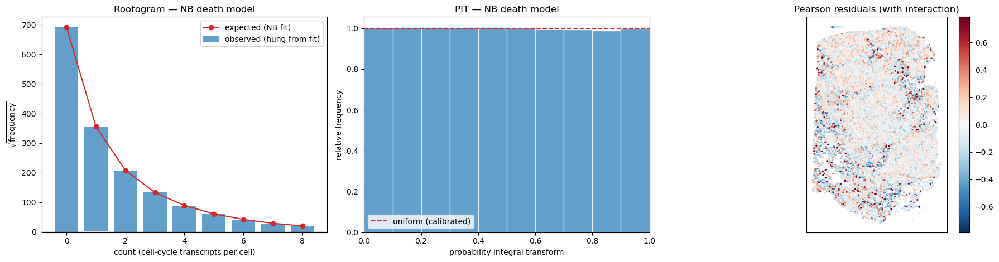

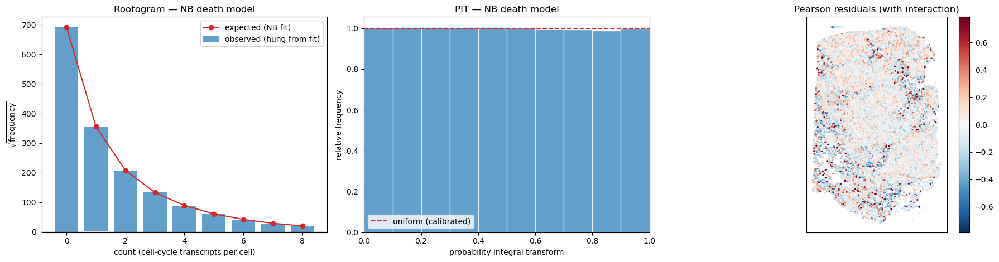

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
plot_rootogram(y_d, d1["fitted_mu"], d1["alpha"], ax=axes[0], max_count=8,
               title="Rootogram — NB death model")
plot_pit_histogram(y_d, d1["fitted_mu"], d1["alpha"], ax=axes[1], n_bins=10,
                   title="PIT — NB death model")

bc.obs["obs_death"] = (y_d >= 1).astype(float)
assign_tiles(bc, tile_size=100.0)
tiles = aggregate_tiles(bc, phi_key=None, obs_means=["obs_death", "resid0", "resid1"], min_cells=5)
rlim = float(np.nanpercentile(np.abs(tiles["resid1_mean"]), 99))
sc = axes[2].scatter(tiles["x"], tiles["y"], c=tiles["resid1_mean"], s=6, cmap="RdBu_r",
                     vmin=-rlim, vmax=rlim, linewidths=0)
fig.colorbar(sc, ax=axes[2], fraction=0.046, pad=0.04)
axes[2].set_aspect("equal"); axes[2].invert_yaxis(); axes[2].set_xticks([]); axes[2].set_yticks([])
axes[2].set_title("Pearson residuals (with interaction)")
fig.tight_layout()

co = tiles[["x", "y"]].to_numpy()
print("Moran's I (100um tiles):")
for lab, col in [("observed death fraction", "obs_death_mean"),
                 ("residuals, no interaction", "resid0_mean"),
                 ("residuals, + interaction", "resid1_mean")]:
    mi = morans_i(tiles[col].to_numpy(), coords=co, permutations=999)
    print("  %-26s I=%+.3f  z=%6.1f" % (lab, mi["I"], mi["z_score"]))
fig

The death model fits **better** than the division model: the rootogram bars sit
almost on the zero line at every count, the PIT is essentially flat (max
deviation ≈ 0.01), and own+neighbour state removes ~96% of the observed spatial
autocorrelation in death (Moran's I 0.68 → ~0.02, vs 0.68 → 0.08 for division).
Apoptosis counts are also much closer to Poisson (NB α ≈ 0.07 vs ≈ 0.77 for the
cell-cycle counts).

## 15. The annulus test: is the neighbourhood effect real, or segmentation spillover?

Every neighbourhood result so far used one disk (`radius=80` µm), which conflates
two very different mechanisms:

* a **genuine neighbourhood effect** — a cell's fate depends on who surrounds it; and
* **segmentation spillover** — transcripts from a touching neighbour get assigned
  to this cell, so `phi_i` is contaminated by `phi_j` and `phi_bar` merely echoes
  the cell's own mis-measured state.

Spillover is a *contact* artefact: transcripts can only be misassigned between
cells whose boundaries touch, i.e. at the very shortest distances (cells here are
~10–15 µm across). A real signalling effect need not be. So we refit the model
with the neighbourhood restricted to successive **annuli** — 0–15, 15–30, 30–50,
50–80, 80–120, 120–200 µm — and watch the neighbour coefficients.

**The quantitative null.** Under pure spillover the apparent coefficient at
distance $r$ is inherited entirely from how much the ring's state still resembles
the cell's own state, so

$$\hat c(r) \;=\; k \cdot \rho_\phi(r)$$

where $\rho_\phi(r)$ is the spatial autocorrelation of the Phi-Space vectors at
distance $r$ (the correlogram, computed over *every* pair in the ring —
~7 × 10⁸ pairs at the outer ring, accumulated chunk-wise). `spillover_chi2` fits
$k$ per dimension and tests the deviation.

Each ring's `phi_bar` is **z-scored before fitting**, so $\hat c(r)$ is an effect
per SD of the ring's mean state — otherwise the wider rings' smaller `phi_bar`
variance would inflate coefficients mechanically.

In [2]:
from tissue_dynamics import annulus_scan, spillover_chi2, DEFAULT_RINGS, plot_annulus_profile

RATE = dict(offset_key="log_total_counts", spline_keys=("local_density",), spline_df=5,
            covariate_keys=("cell_area",), fitter="irls")
coef, summary = annulus_scan(bc, rings=DEFAULT_RINGS, interaction=True, verbose=True, **RATE)

cols = ["r_inner", "r_outer", "mean_neighbors", "rho_phi", "rho_own_bar",
        "c_mean_abs", "c_norm", "B_fro", "lr_interaction"]
print("\n=== per-ring neighbourhood effect ===")
print(summary[cols].round(3).to_string(index=False))

ring   0- 15 um: mean nbrs=   7.0  rho_phi=0.569  |c|=0.115


ring  15- 30 um: mean nbrs=  20.4  rho_phi=0.493  |c|=0.152


ring  30- 50 um: mean nbrs=  46.0  rho_phi=0.424  |c|=0.200


ring  50- 80 um: mean nbrs= 107.5  rho_phi=0.364  |c|=0.243


ring  80-120 um: mean nbrs= 211.4  rho_phi=0.311  |c|=0.341


ring 120-200 um: mean nbrs= 641.1  rho_phi=0.252  |c|=0.449



=== per-ring neighbourhood effect ===
 r_inner  r_outer  mean_neighbors  rho_phi  rho_own_bar  c_mean_abs  c_norm  B_fro  lr_interaction
     0.0     15.0           6.996    0.569        0.736       0.115   0.453  5.186        4884.103
    15.0     30.0          20.385    0.493        0.708       0.152   0.541  4.920        4361.677
    30.0     50.0          46.013    0.424        0.664       0.200   0.634  4.828        3548.520
    50.0     80.0         107.545    0.364        0.621       0.243   0.818  6.825        3032.748
    80.0    120.0         211.364    0.311        0.575       0.341   1.079 11.433        2572.850
   120.0    200.0         641.149    0.252        0.525       0.449   1.464 14.408        2119.394


normalized to the innermost (contact) ring:
  ring        c(r)/c(0)   rho(r)/rho(0)   ratio
    0- 15 um     1.000         1.000     1.00
   15- 30 um     1.319         0.865     1.52
   30- 50 um     1.738         0.744     2.33
   50- 80 um     2.111         0.640     3.30
   80-120 um     2.966         0.546     5.43
  120-200 um     3.898         0.443     8.79

spillover null  c_d(r) = k_d * rho_phi(r):  chi2=1818  df=40  p=0.00e+00


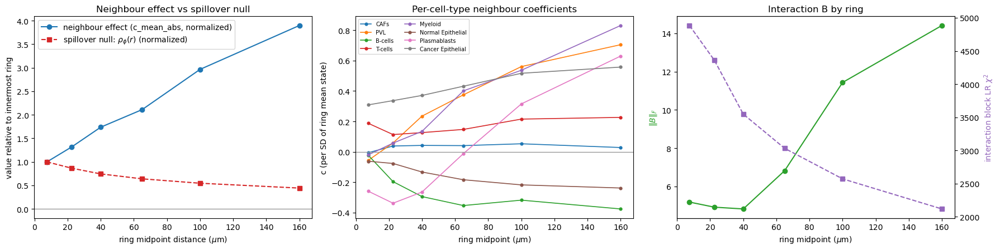

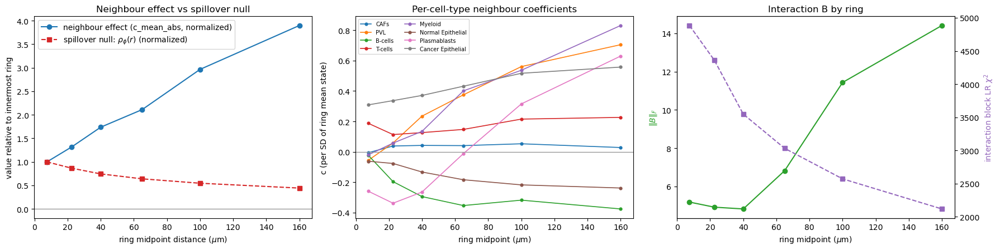

In [3]:
c0, r0 = summary["c_mean_abs"].iloc[0], summary["rho_phi"].iloc[0]
print("normalized to the innermost (contact) ring:")
print("  ring        c(r)/c(0)   rho(r)/rho(0)   ratio")
for _, r in summary.iterrows():
    print("  %3.0f-%3.0f um   %7.3f   %11.3f   %6.2f"
          % (r["r_inner"], r["r_outer"], r["c_mean_abs"]/c0, r["rho_phi"]/r0,
             (r["c_mean_abs"]/c0)/(r["rho_phi"]/r0)))

res = spillover_chi2(coef)
print("\nspillover null  c_d(r) = k_d * rho_phi(r):  chi2=%.0f  df=%d  p=%.2e"
      % (res["chi2"], res["df"], res["p_value"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
plot_annulus_profile(summary, ax=axes[0],
                     title="Neighbour effect vs spillover null")
for dim, g in coef.groupby("dim", sort=False):
    mid = (g["r_inner"] + g["r_outer"]) / 2
    axes[1].plot(mid, g["c"], "o-", lw=1.2, ms=3.5, label=dim)
axes[1].axhline(0, color="0.6", lw=1)
axes[1].set_xlabel(r"ring midpoint ($\mu$m)"); axes[1].set_ylabel("c (per SD of ring mean state)")
axes[1].set_title("Per-cell-type neighbour coefficients")
axes[1].legend(fontsize=7, ncol=2)

mid = (summary["r_inner"] + summary["r_outer"]) / 2
axes[2].plot(mid, summary["B_fro"], "o-", color="C2", label=r"$\|B\|_F$")
axes[2].set_xlabel(r"ring midpoint ($\mu$m)"); axes[2].set_ylabel(r"$\|B\|_F$", color="C2")
ax2b = axes[2].twinx()
ax2b.plot(mid, summary["lr_interaction"], "s--", color="C4", label="interaction LR")
ax2b.set_ylabel("interaction block LR $\\chi^2$", color="C4")
axes[2].set_title("Interaction B by ring")
fig.tight_layout()
fig

The spillover null is rejected outright ($\chi^2 \approx 1800$ on 40 df): $\hat
c(r)$ does not decay with $\rho_\phi(r)$ — it *rises*, ~3.9× by the outer ring,
where spillover predicts ~0.44×.

**But do not read that rise as "signalling strengthens with distance" — most of it
is an artefact of a different kind.** A wide ring averages far more cells (641 at
120–200 µm vs 7 at 0–15 µm), so its `phi_bar` is a much less noisy measurement of
local composition and suffers far less **regression dilution**. Less attenuation
means a bigger coefficient, for reasons that have nothing to do with distance.
The count-matched control below removes that confound; it is the version to trust.

Note the interaction behaves differently from `c`: $\|B\|_F$ grows with the ring,
but the *evidence* for it (the block LR) is strongest at contact range and falls
monotonically outward — the own×neighbour coupling is the one piece of the
neighbourhood signal that genuinely concentrates at short range.

### Count-matched control

Re-run every ring with each cell's neighbourhood thinned to the same 7 randomly
chosen neighbours (`max_neighbors=7`, the innermost ring's mean). Averaging noise
— and hence regression dilution — is then identical across rings, so any
remaining trend in $\hat c(r)$ is about distance, not sample size.

ring   0- 15 um: mean nbrs=   5.2  rho_phi=0.581  |c|=0.110


ring  15- 30 um: mean nbrs=   6.6  rho_phi=0.517  |c|=0.109


ring  30- 50 um: mean nbrs=   6.9  rho_phi=0.446  |c|=0.105


ring  50- 80 um: mean nbrs=   7.0  rho_phi=0.386  |c|=0.090


ring  80-120 um: mean nbrs=   7.0  rho_phi=0.334  |c|=0.080


ring 120-200 um: mean nbrs=   7.0  rho_phi=0.276  |c|=0.073



count-matched (7 neighbours per cell in every ring):
  ring        c(r)/c(0)   rho(r)/rho(0)   ratio
    0- 15 um     1.000         1.000     1.00
   15- 30 um     0.994         0.890     1.12
   30- 50 um     0.956         0.769     1.24
   50- 80 um     0.818         0.665     1.23
   80-120 um     0.732         0.575     1.27
  120-200 um     0.663         0.475     1.40

spillover null (count-matched):  chi2=165  df=40  p=4.67e-17


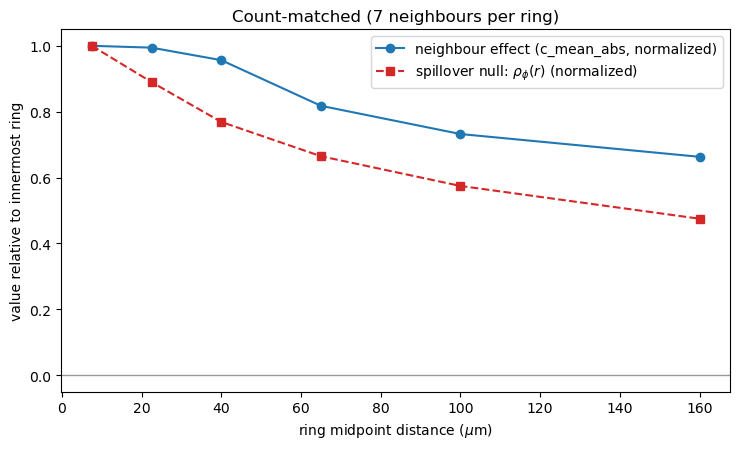

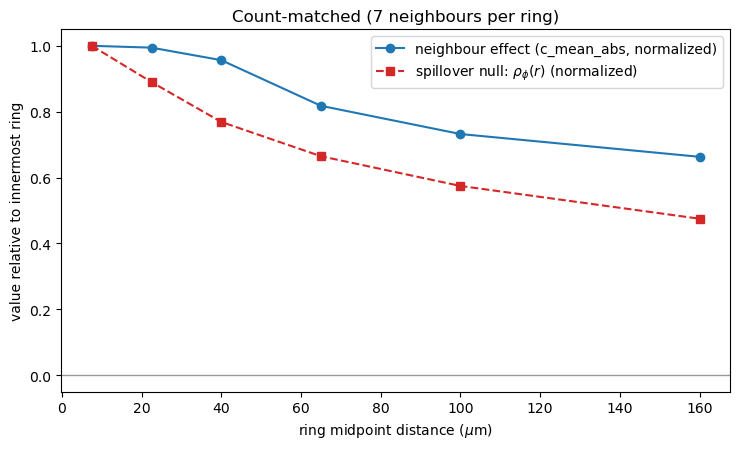

In [4]:
coef_m, summary_m = annulus_scan(bc, rings=DEFAULT_RINGS, interaction=False,
                                 max_neighbors=7, verbose=True, **RATE)
c0m, r0m = summary_m["c_mean_abs"].iloc[0], summary_m["rho_phi"].iloc[0]
print("\ncount-matched (7 neighbours per cell in every ring):")
print("  ring        c(r)/c(0)   rho(r)/rho(0)   ratio")
for _, r in summary_m.iterrows():
    print("  %3.0f-%3.0f um   %7.3f   %11.3f   %6.2f"
          % (r["r_inner"], r["r_outer"], r["c_mean_abs"]/c0m, r["rho_phi"]/r0m,
             (r["c_mean_abs"]/c0m)/(r["rho_phi"]/r0m)))
res_m = spillover_chi2(coef_m)
print("\nspillover null (count-matched):  chi2=%.0f  df=%d  p=%.2e"
      % (res_m["chi2"], res_m["df"], res_m["p_value"]))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
plot_annulus_profile(summary_m, ax=ax,
                     title="Count-matched (7 neighbours per ring)")
fig.tight_layout()
fig

### Verdict

With averaging noise held constant the picture changes completely — and becomes
much more defensible. The neighbour effect **does** decay with distance (the
naive scan's 3.9× rise was regression dilution, not biology), but it decays
**consistently more slowly than the Phi-Space autocorrelation**:

| ring (µm) | $\rho_\phi(r)/\rho_\phi(0)$ | $\hat c(r)/\hat c(0)$ | ratio |
|---|---|---|---|
| 0–15   | 1.000 | 1.000 | 1.00 |
| 15–30  | 0.890 | 0.994 | 1.12 |
| 30–50  | 0.769 | 0.956 | 1.24 |
| 50–80  | 0.665 | 0.818 | 1.23 |
| 80–120 | 0.575 | 0.732 | 1.27 |
| 120–200| 0.475 | 0.663 | 1.40 |

The spillover null is still rejected — $\chi^2 = 165$ on 40 df ($p \approx 5
\times 10^{-17}$) — but note how much of the original $\chi^2 = 1818$ was the
dilution artefact rather than evidence.

**What this supports.** Segmentation spillover cannot explain the neighbourhood
association: it acts only where cell boundaries touch, yet two-thirds of the
contact-range effect survives at 120–200 µm, many cell diameters away with many
intervening cells. The excess over $\rho_\phi$ grows monotonically with distance,
which is the signature of an effect with its own spatial range rather than one
inherited from the autocorrelation of tissue composition.

**What this does not support.** The effect is genuinely distance-attenuated, and
the excess over $\rho_\phi$ is modest (1.1–1.4×). So a large share of what the
disk model calls a "neighbourhood effect" does simply track the ambient
correlation of tissue composition; the part that is specifically neighbourhood
signal is real but a minority of the raw association — consistent with the
earlier finding that controlling for depth/density shrank the neighbour
coefficients substantially.

*Caveat:* the rings are refit on the same cells, so the per-ring estimates are
correlated and the $\chi^2$ is an approximation — read it together with the
monotone ratio column, which is the robust part of the result.

## 16. The tissue oxygen field

Oxygen diffuses over hundreds of micrometres — well beyond the 80 µm neighbourhood
the fate models use — so a cell's oxygenation is set by vasculature it never
touches. `oxygen.build_oxygen_field` solves a steady-state screened-diffusion PDE
over the rasterised section,

$$\nabla^2 u = \kappa(x)\,u, \qquad -\nabla u\cdot\hat n = \beta\,\Phi(x)\,(1-u),\qquad \nabla u\cdot\hat n\big|_{\partial\Omega}=0$$

with soft-labelled **blood** endothelium (ACKR1 + RGS5 + CXCL12, excluding
lymphatics, which drain fluid and carry no oxygenated blood) as the Robin sources
$\Phi$, and consumption $\kappa=(1/L_0^2)(n/n_0)$ rising with local cell density.
$u$ is scale-free relative oxygenation in $[0,1]$ — deliberately *not* absolute
pO₂.

**Read this field as a diagnostic, not as a covariate.** The numerics validate
completely (5.1M unknowns, AMG residual 7e-11, all of the spec's §7.1–7.8 checks
pass, including density-decoupling at 0.12), but the **biological gate (§7.9)
fails**: HIF-target expression correlates *positively* with modelled oxygenation
(Spearman +0.089) where it must be clearly negative. That failure is robust to
every parameter setting tried, to per-gene breakdown, and to tile aggregation. So
the field is **not** used as a model covariate — see the module docstring for the
full post-mortem.

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tissue_dynamics.oxygen import build_oxygen_field

DATA = "../data/Xenium_Prime_Breast_Cancer_FFPE"
BLOOD = ["Endothelial ACKR1", "Endothelial RGS5", "Endothelial CXCL12"]

cells_df = pd.read_csv(f"{DATA}/cells.csv.gz", usecols=["cell_id", "x_centroid", "y_centroid"])
mp = pd.read_csv("../data/xenium_prime_celltype_minor_phispace.csv", usecols=["cell_id"] + BLOOD)
mp["phi_endo"] = mp[BLOOD].sum(1)                       # blood endothelium only
d = cells_df.merge(mp[["cell_id", "phi_endo"]], on="cell_id").dropna(subset=["phi_endo"])
xy = d[["x_centroid", "y_centroid"]].to_numpy(float)

res = build_oxygen_field(xy, d["phi_endo"].to_numpy(float),
                         h=5.0, L0=100.0, beta=1.0, c=0.15, verbose=True)
g = res.diagnostics
print("grid %s | %d unknowns | tissue %.0f%% of bbox | residual %.1e"
      % (g["grid_shape"], g["n_unknowns"], 100*g["tissue_frac"], g["rel_residual"]))
print("source: %.1f%% of cells retained at c=%.2f, signal share %.0f%%"
      % (100*g["retained_frac"], res.params["c"], 100*g["signal_share"]))
print("u: min %.3f  max %.3f  mean at cells %.3f" % (g["u_min"], g["u_max"], g["u_mean_cells"]))

  pyamg: 5133413 unknowns, rel residual 7.09e-11 | signal share 100.0%, retained 2.61%
grid (2192, 3222) | 5133413 unknowns | tissue 73% of bbox | residual 7.1e-11
source: 2.6% of cells retained at c=0.15, signal share 100%
u: min 0.000  max 0.995  mean at cells 0.142


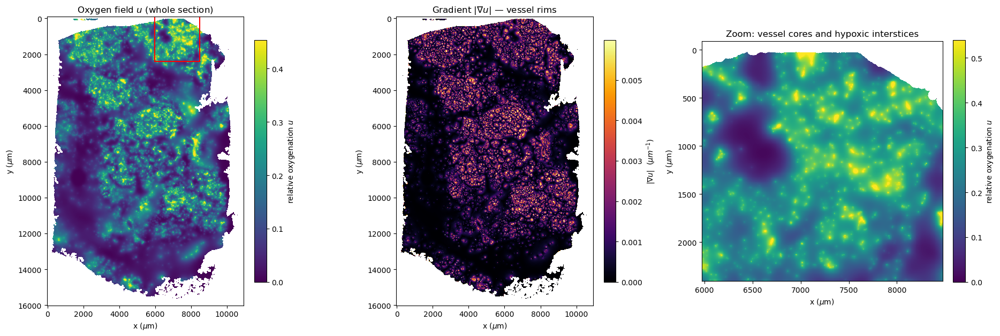

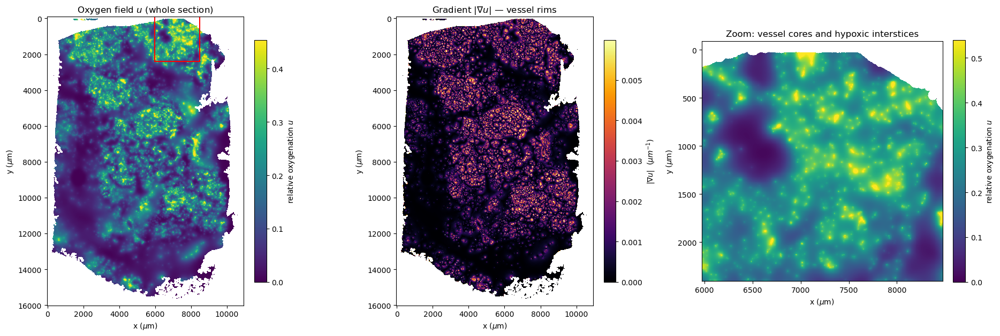

In [2]:
u, tissue, h, org = res.u, res.tissue, res.h, res.origin
gy, gx = np.gradient(np.nan_to_num(u), h)
grad = np.where(tissue, np.hypot(gy, gx), np.nan)
ext = [org[0], org[0] + u.shape[0]*h, org[1], org[1] + u.shape[1]*h]   # x0,x1,y0,y1 in um

# pick the most structured 2.5 mm window to zoom into
blk = 100
Hb, Wb = u.shape[0]//blk, u.shape[1]//blk
sd = np.nanstd(np.nan_to_num(u)[:Hb*blk, :Wb*blk].reshape(Hb, blk, Wb, blk), axis=(1, 3))
bi, bj = np.unravel_index(np.nanargmax(sd), sd.shape)
i0, j0 = max(bi*blk - 200, 0), max(bj*blk - 200, 0)
i1, j1 = min(i0 + 500, u.shape[0]), min(j0 + 500, u.shape[1])
zext = [org[0] + i0*h, org[0] + i1*h, org[1] + j0*h, org[1] + j1*h]

fig, axes = plt.subplots(1, 3, figsize=(19, 6.4))
im0 = axes[0].imshow(u.T, origin="lower", extent=ext, cmap="viridis", vmin=0,
                     vmax=np.nanpercentile(u, 99.5), interpolation="nearest")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="relative oxygenation $u$")
axes[0].set_title("Oxygen field $u$ (whole section)")
axes[0].add_patch(plt.Rectangle((zext[0], zext[2]), zext[1]-zext[0], zext[3]-zext[2],
                                fill=False, ec="red", lw=1.5))

im1 = axes[1].imshow(grad.T, origin="lower", extent=ext, cmap="inferno",
                     vmax=np.nanpercentile(grad, 99), interpolation="nearest")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label=r"$|\nabla u|$  ($\mu m^{-1}$)")
axes[1].set_title(r"Gradient $|\nabla u|$ — vessel rims")

im2 = axes[2].imshow(u[i0:i1, j0:j1].T, origin="lower", extent=zext, cmap="viridis",
                     vmin=0, vmax=np.nanpercentile(u[i0:i1, j0:j1], 99.5), interpolation="nearest")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04, label="relative oxygenation $u$")
axes[2].set_title("Zoom: vessel cores and hypoxic interstices")

for ax in axes:
    ax.set_aspect("equal"); ax.invert_yaxis()
    ax.set_xlabel(r"x ($\mu$m)"); ax.set_ylabel(r"y ($\mu$m)")
fig.tight_layout()
fig

Bright spots are perivascular; the dark interstitial tissue between them is where
the model puts the oxygen minima, with the characteristic length set by
$L_0 = 100\ \mu$m — the textbook oxygen diffusion limit. The gradient panel picks
out the rims, which is what `grad_u` would have contributed as a covariate. The
field is visibly vessel-driven rather than a smoothed density map, which is what
§7.8 confirms numerically — but see §7.9 above for why it still does not enter the
model.

## 17. Where the hypoxia markers actually are

The field in §16 looks convincing, yet it fails the §7.9 gate. This section shows
*why*, spatially: tile the section at 100 µm and map the HIF-target markers
themselves, next to the modelled oxygenation on identical tiles.

Marker abundance is library-normalised (HIF transcripts per 1,000 total
transcripts in the tile), so the maps are rates, not depth. Tiles need ≥ 20 cells
— the markers are sparse enough per cell (CA9 is detected in 0.2% of them) that
aggregation is the only way to see their geography at all.

In [2]:
import scanpy as sc
from tissue_dynamics import morans_i

HIF = ["CA9", "NDRG1", "ADM", "EGLN3", "BNIP3", "ANGPTL4"]
ad = sc.read_10x_h5(f"{DATA}/cell_feature_matrix.h5"); ad.var_names_make_unique()
ad = ad[d["cell_id"].to_numpy()]
H = np.asarray(ad[:, [ad.var_names.get_loc(g) for g in HIF]].X.todense()).astype(float)
total = np.asarray(ad.X.sum(1)).ravel().astype(float)

TILE = 100.0
tx = np.floor((xy[:, 0] - xy[:, 0].min()) / TILE).astype(int)
ty = np.floor((xy[:, 1] - xy[:, 1].min()) / TILE).astype(int)
tab = pd.DataFrame({"tx": tx, "ty": ty, "u": res.u_cells, "tot": total,
                    **{g: H[:, k] for k, g in enumerate(HIF)}})
tab = tab[np.isfinite(tab["u"]) & (tab["tot"] > 0)]
agg = tab.groupby(["tx", "ty"]).agg(
    n=("u", "size"), u=("u", "mean"), tot=("tot", "sum"),
    **{g: (g, "sum") for g in HIF}).reset_index()
agg = agg[agg["n"] >= 20]
agg["HIF"] = agg[HIF].sum(1)
for g in HIF + ["HIF"]:
    agg[g + "_rate"] = 1000.0 * agg[g] / agg["tot"]      # transcripts per 1,000
agg["x"] = xy[:, 0].min() + (agg["tx"] + 0.5) * TILE
agg["y"] = xy[:, 1].min() + (agg["ty"] + 0.5) * TILE
print("%d tiles of %.0f um with >=20 cells (median %.0f cells/tile)"
      % (len(agg), TILE, agg["n"].median()))

co = agg[["x", "y"]].to_numpy()
from scipy.stats import spearmanr
print("Moran's I: HIF rate %+.3f | oxygen u %+.3f   (both strongly spatially structured)"
      % (morans_i(agg["HIF_rate"].to_numpy(), coords=co, permutations=499)["I"],
         morans_i(agg["u"].to_numpy(), coords=co, permutations=499)["I"]))
print("Spearman(u, HIF rate) across tiles = %+.4f   <-- should be clearly NEGATIVE for a hypoxia field"
      % spearmanr(agg["u"], agg["HIF_rate"]).statistic)

8747 tiles of 100 um with >=20 cells (median 68 cells/tile)
Moran's I: HIF rate +0.193 | oxygen u +0.792   (both strongly spatially structured)
Spearman(u, HIF rate) across tiles = +0.0277   <-- should be clearly NEGATIVE for a hypoxia field


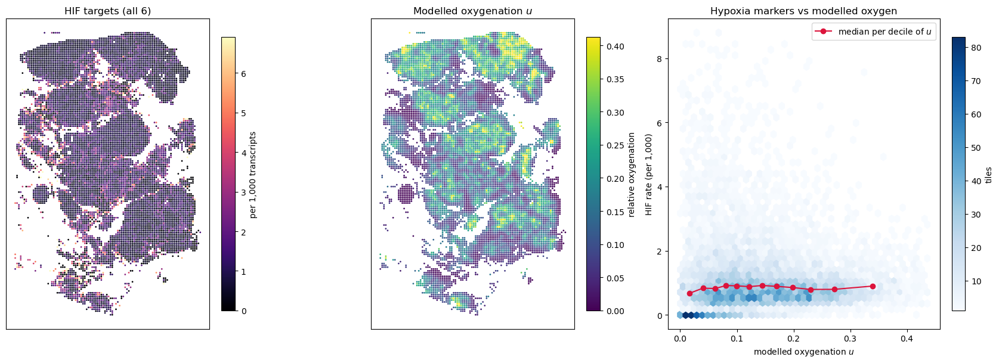

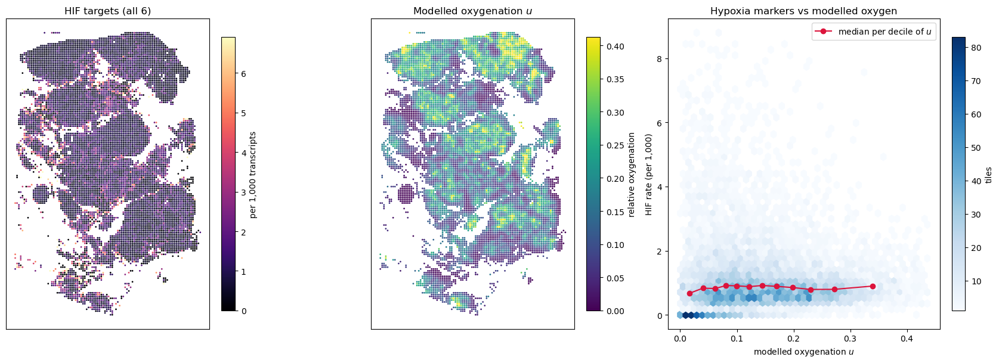

In [3]:
def tilemap(ax, vals, title, cmap, vmax=None, label=""):
    sc_ = ax.scatter(agg["x"], agg["y"], c=vals, s=4, cmap=cmap, linewidths=0,
                     vmin=0, vmax=vmax if vmax is not None else np.percentile(vals, 99))
    fig.colorbar(sc_, ax=ax, fraction=0.046, pad=0.04, label=label)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.2))
tilemap(axes[0], agg["HIF_rate"], "HIF targets (all 6)", "magma", label="per 1,000 transcripts")
tilemap(axes[1], agg["u"], "Modelled oxygenation $u$", "viridis", vmax=np.percentile(agg["u"], 99),
        label="relative oxygenation")
hb = axes[2].hexbin(agg["u"], agg["HIF_rate"], gridsize=45, cmap="Blues", mincnt=1,
                    extent=(0, np.percentile(agg["u"], 99.5), 0, np.percentile(agg["HIF_rate"], 99.5)))
fig.colorbar(hb, ax=axes[2], fraction=0.046, pad=0.04, label="tiles")
q = pd.qcut(agg["u"], 12, duplicates="drop")
med = agg.groupby(q, observed=True).agg(u=("u", "median"), h=("HIF_rate", "median"))
axes[2].plot(med["u"], med["h"], "o-", color="crimson", label="median per decile of $u$")
axes[2].set_xlabel("modelled oxygenation $u$"); axes[2].set_ylabel("HIF rate (per 1,000)")
axes[2].set_title("Hypoxia markers vs modelled oxygen"); axes[2].legend(); axes[2].set_aspect("auto")
fig.tight_layout()
fig

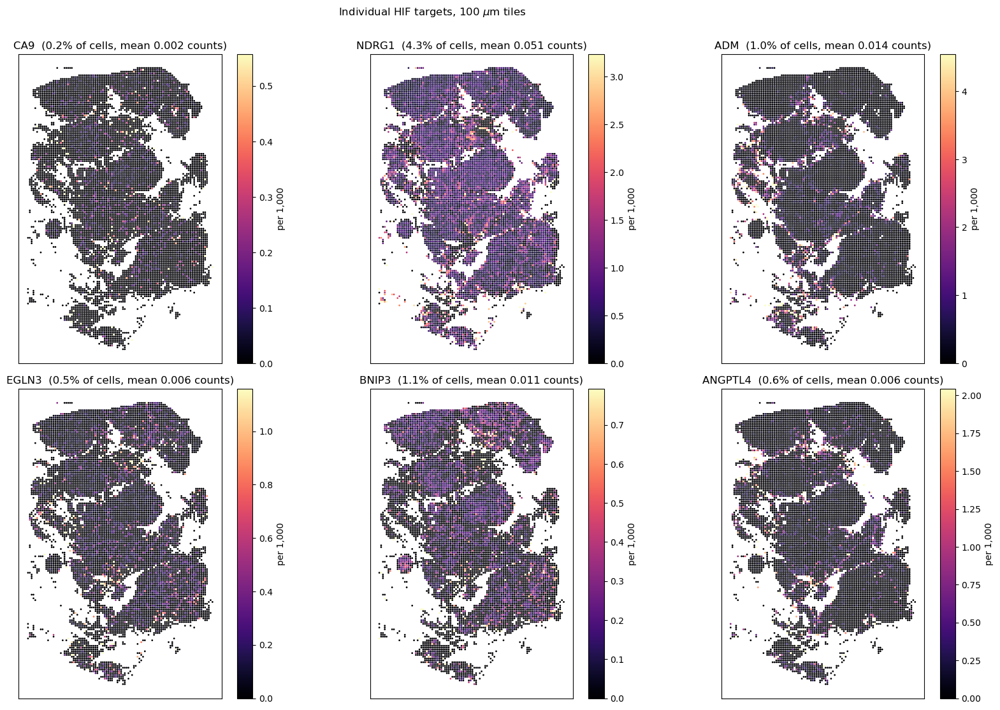

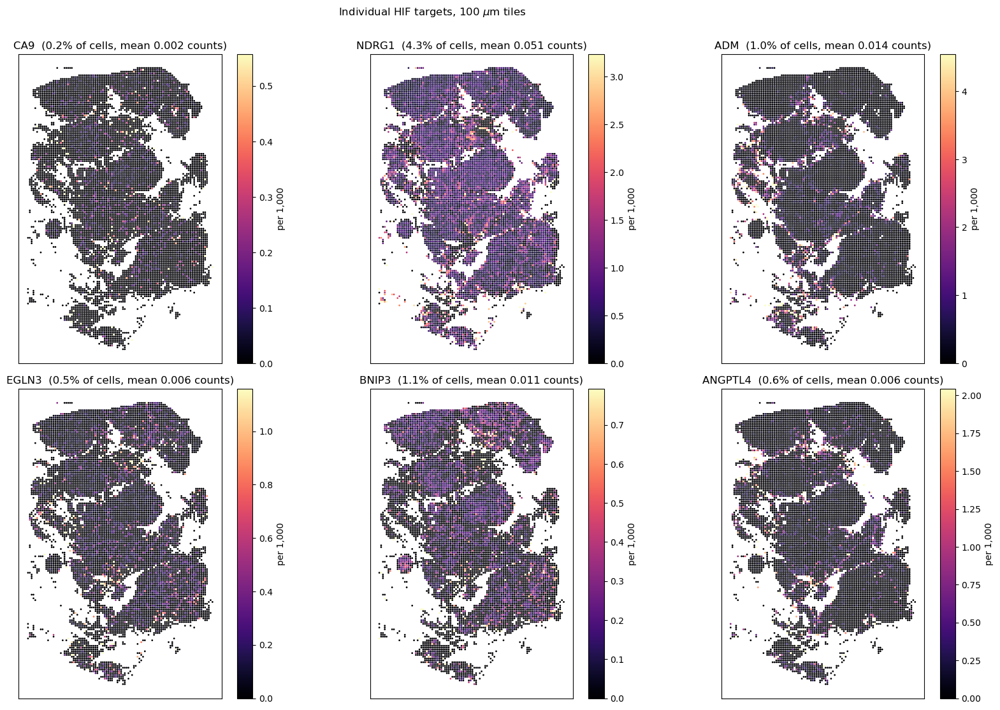

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, g in zip(axes.ravel(), HIF):
    r = agg[g + "_rate"]
    tilemap(ax, r, "%s  (%.1f%% of cells, mean %.3f counts)"
            % (g, 100 * (H[:, HIF.index(g)] > 0).mean(), H[:, HIF.index(g)].mean()),
            "magma", vmax=np.percentile(r, 99), label="per 1,000")
fig.suptitle("Individual HIF targets, 100 $\\mu$m tiles", y=1.005)
fig.tight_layout()
fig

This is the §7.9 failure made visible — and it shows the problem lies in the
*readout* at least as much as in the field.

Five of the six markers are simply absent from most of the section. On 100 µm
tiles with ≥ 20 cells, **CA9** — the specific hypoxia marker — has zero counts in
**86%** of tiles, and EGLN3, ANGPTL4, BNIP3 and ADM in 56–70%. Only **NDRG1**
(zero in 19%) is broadly detected, and it is the least hypoxia-specific of the
six, so it dominates the composite by default.

What structure the composite does have is largely a depth artefact. The bright
tiles hug the tissue margins and the rims of the interior gaps, and the rate is
strongly inflated wherever sequencing depth is low:
Spearman(tile depth, HIF rate) = **−0.30**, with the median rate falling
1.53 → 0.64 per 1,000 from the lowest to the highest depth quintile. Its spatial
autocorrelation is correspondingly weak — Moran's I **0.19**, against **0.79**
for the oxygen field — which is not what a coherent hypoxic geography looks like.

So the honest verdict is *not* that the oxygen field has been shown to be wrong.
It is that this panel cannot measure hypoxia well enough to license **or** refute
it. By the spec's own rule that is still a failure: the covariate is unlicensed,
and absence of validation is not validation of absence. The field therefore stays
out of the model — but the sharper conclusion is that testing it properly needs a
hypoxia readout this panel does not provide (a dedicated CA9/HIF panel, protein
stain, or a whole-transcriptome section).

## 18. Adding the oxygen field to the division model

§16–17 left the oxygen field unlicensed as a *hypoxia* covariate: it failed the
HIF-target gate, and §17 showed the readout itself is too sparse and too
depth-confounded to settle the question either way. That is a statement about
**the marker panel**, not about whether the field carries information.

So we ask a different, self-contained question: **does `u` explain spatial
structure in division that own + neighbour cell state does not?**

Two traps have to be disarmed for the answer to mean anything.

1. **Any smooth field would help a bit.** `u` has Moran's I 0.79, and adding any
   smooth spatial covariate soaks up some residual spatial autocorrelation for
   free. So every fit is repeated with a **decoy**: the same field rotated 180°,
   identical smoothness and marginals, biologically misaligned (corr ≈ −0.13).
2. **`u` correlates with sequencing depth** (ρ ≈ +0.57 at tile level), and depth
   drives marker detection hard. The model already carries log-depth as an
   offset, but an offset *fixes* that coefficient at 1. So we also refit with
   log-depth as a **free** covariate: if `u` is really residual depth, its
   coefficient should collapse.

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, gc
from scipy.stats import chi2
from tissue_dynamics import (
    read_xenium, read_phi_table, attach_phi, build_adjacency, average_neighbors,
    score_division, compute_library_size, compute_local_density,
    attach_oxygen_field, fit_division_nb, fit_death_nb, get_signature_counts,
    assign_tiles, aggregate_tiles, morans_i)
from tissue_dynamics.oxygen import sample_at_cells
from tissue_dynamics.gene_sets import TIROSH_S_GENES, TIROSH_G2M_GENES, APOPTOSIS_SIGNATURE

DATA = "../data/Xenium_Prime_Breast_Cancer_FFPE"; REF = "Endothelial"
BLOOD = ["Endothelial ACKR1", "Endothelial RGS5", "Endothelial CXCL12"]

bc = read_xenium(DATA, sample_id="BC")
pt = read_phi_table("../data/phispace_normalised.csv", phi_cols="all")
bc = bc[bc.obs["cell_id"].isin(pt.index)].copy()
compute_library_size(bc); compute_local_density(bc, radius=50.0)
attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()
_n = bc.uns["phi_names"]; _k = [i for i, n in enumerate(_n) if n != REF]
bc.obsm["phi"] = bc.obsm["phi"][:, _k]; bc.uns["phi_names"] = [_n[i] for i in _k]
build_adjacency(bc, radius=80.0); average_neighbors(bc); score_division(bc)
bc.X = bc.layers["counts"]; del bc.layers["counts"]; gc.collect()

# solve the field over ALL cells (vessels outside the modelled subset still supply it)
allc = pd.read_csv(f"{DATA}/cells.csv.gz", usecols=["cell_id", "x_centroid", "y_centroid"])
mp = pd.read_csv("../data/xenium_prime_celltype_minor_phispace.csv", usecols=["cell_id"] + BLOOD)
mp["phi_endo"] = mp[BLOOD].sum(1)
src = allc.merge(mp[["cell_id", "phi_endo"]], on="cell_id").dropna(subset=["phi_endo"])
res = attach_oxygen_field(bc, None, source_xy=src[["x_centroid", "y_centroid"]].to_numpy(float),
                          source_phi_endo=src["phi_endo"].to_numpy(float),
                          h=5.0, L0=100.0, beta=1.0, c=0.15)
uf, tf = res.u[::-1, ::-1], res.tissue[::-1, ::-1]
u_rot, _, ok_rot = sample_at_cells(uf, np.asarray(bc.obsm["spatial"]), res.origin, res.h, tissue=tf)
bc.obs["oxygen_u_rot180"] = np.where(ok_rot, u_rot, np.nan)
bc = bc[(np.isfinite(bc.obs["oxygen_u"]) & np.isfinite(bc.obs["oxygen_u_rot180"])).to_numpy()].copy()
gc.collect()
print("field: %d unknowns, residual %.1e | %d cells with real field and decoy | corr = %+.3f"
      % (res.diagnostics["n_unknowns"], res.diagnostics["rel_residual"], bc.n_obs,
         np.corrcoef(bc.obs["oxygen_u"], bc.obs["oxygen_u_rot180"])[0, 1]))

/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_4339/1123156200.py:16: UserWarning: spatialdata-io failed to read this sample (FileNotFoundError(2, 'No such file or directory')); falling back to the manual cell_feature_matrix reader.
  bc = read_xenium(DATA, sample_id="BC")


/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_4339/1123156200.py:20: UserWarning: 3592/683798 cells have a NaN phi embedding (a matched row exists, but with missing values -- typically near-empty segmentation artifacts the embedding method couldn't score). These will propagate NaNs into neighbor-averaging and model fitting; filter them out first, e.g. `adata = adata[~np.isnan(adata.obsm['phi']).any(axis=1)].copy()`.
  attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()


/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_4339/1123156200.py:23: UserWarning: 54/680206 cells have no spatial neighbors within radius=80.0 (isolated); their neighbor-averaged embedding will be the zero vector.
  build_adjacency(bc, radius=80.0); average_neighbors(bc); score_division(bc)


field: 5133413 unknowns, residual 7.1e-11 | 614286 cells with real field and decoy | corr = -0.130


In [2]:
RATE = dict(offset_key="log_total_counts", spline_keys=("local_density",), spline_df=5, fitter="irls")

def run(fit_fn, extra_cov=(), tag_prefix=""):
    # fit baseline / +u / +decoy; return coefficients, LR and residual Moran's I
    out = {}
    for label, tag, cov in [("baseline", "base", ("cell_area",) + extra_cov),
                            ("+ oxygen u", "oxy", ("cell_area",) + extra_cov + ("oxygen_u",)),
                            ("+ rotated decoy", "rot", ("cell_area",) + extra_cov + ("oxygen_u_rot180",))]:
        f = fit_fn(bc, predictors="own+neighbor", interaction_rank=0, covariate_keys=cov, **RATE)
        cf = f["coef"].set_index("term")
        out[tag] = dict(label=label, loglik=f["loglik"], k=f["n_params"],
                        beta=cf.loc[cov[-1], "estimate"] if tag != "base" else np.nan,
                        z=cf.loc[cov[-1], "z"] if tag != "base" else np.nan)
        bc.obs["resid_" + tag_prefix + tag] = f["pearson_resid"]
        del f; gc.collect()
    return out

def report(out, title, tiles=None, prefix=""):
    print("\n" + title)
    print("%-18s %11s %8s %7s%s" % ("model", "loglik", "beta", "z",
          " | %8s %s" % ("Moran I", "LR vs baseline") if tiles is not None else ""))
    for tag in ("base", "oxy", "rot"):
        d = out[tag]; lr = 2*(d["loglik"]-out["base"]["loglik"]); df = d["k"]-out["base"]["k"]
        m = ""
        if tiles is not None:
            d["moran"] = morans_i(tiles["resid_"+prefix+tag+"_mean"].to_numpy(),
                                  coords=tiles[["x","y"]].to_numpy(), n_neighbors=8, permutations=999)["I"]
            m = " | %+8.4f %s" % (d["moran"], "" if df <= 0 else
                                  "chi2=%.1f df=%d p=%.1e" % (lr, df, chi2.sf(lr, df)))
        elif df > 0:
            m = " | LR chi2=%.1f p=%.1e" % (lr, chi2.sf(lr, df))
        print("%-18s %11.1f %8s %7s%s" % (d["label"], d["loglik"],
              "%.4f" % d["beta"] if np.isfinite(d["beta"]) else "-",
              "%+.1f" % d["z"] if np.isfinite(d["z"]) else "-", m))
    return out

div = run(fit_division_nb)
yv, _a, _b = get_signature_counts(bc, list(dict.fromkeys(list(TIROSH_S_GENES)+list(TIROSH_G2M_GENES))))
yd, _c, _e = get_signature_counts(bc, list(APOPTOSIS_SIGNATURE))
bc.obs["obs_incycle"] = (yv >= 1).astype(float); bc.obs["obs_death"] = (yd >= 1).astype(float)
assign_tiles(bc, tile_size=100.0)
tiles = aggregate_tiles(bc, phi_key=None, min_cells=5,
                        obs_means=["resid_base","resid_oxy","resid_rot","oxygen_u",
                                   "obs_incycle","obs_death","total_counts"])
report(div, "DIVISION model (log-depth as offset)", tiles)
r_u = div["base"]["moran"]-div["oxy"]["moran"]; r_d = div["base"]["moran"]-div["rot"]["moran"]
print("Moran reduction: real u %.4f (%.1f%%) vs decoy %.4f (%.1f%%)  ->  %.0fx"
      % (r_u, 100*r_u/div["base"]["moran"], r_d, 100*r_d/div["base"]["moran"], r_u/max(r_d,1e-9)))

# robustness: let log-depth take a FREE coefficient on top of the offset
divf = run(fit_division_nb, extra_cov=("log_total_counts",), tag_prefix="f")
report(divf, "DIVISION model (log-depth ALSO free -- is u just residual depth?)")
print("-> beta(u) %.4f -> %.4f : unchanged, so u is NOT residual depth"
      % (div["oxy"]["beta"], divf["oxy"]["beta"]))


DIVISION model (log-depth as offset)
model                   loglik     beta       z |  Moran I LR vs baseline
baseline             -532673.2        -       - |  +0.0876 


+ oxygen u           -532557.9   0.0462   +15.2 |  +0.0819 chi2=230.7 df=1 p=4.3e-52
+ rotated decoy      -532666.9  -0.0070    -3.0 |  +0.0872 chi2=12.8 df=1 p=3.6e-04
Moran reduction: real u 0.0058 (6.6%) vs decoy 0.0004 (0.5%)  ->  14x



DIVISION model (log-depth ALSO free -- is u just residual depth?)
model                   loglik     beta       z
baseline             -531940.2        -       -
+ oxygen u           -531837.2   0.0431   +14.5 | LR chi2=206.0 p=1.0e-46
+ rotated decoy      -531933.6  -0.0076    -3.4 | LR chi2=13.2 p=2.8e-04
-> beta(u) 0.0462 -> 0.0431 : unchanged, so u is NOT residual depth


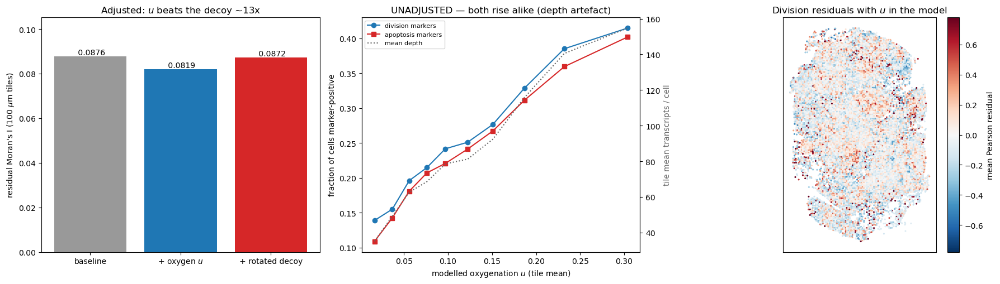

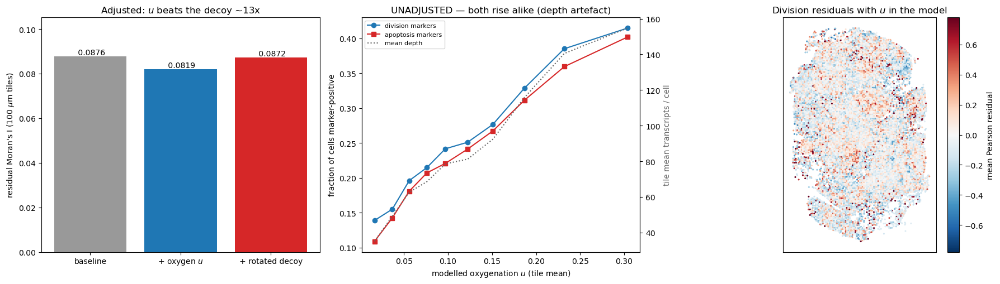

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

vals = [div[t]["moran"] for t in ("base", "oxy", "rot")]
axes[0].bar(range(3), vals, color=["0.6", "C0", "C3"])
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(["baseline", "+ oxygen $u$", "+ rotated decoy"])
axes[0].set_ylabel("residual Moran's I (100 $\\mu$m tiles)")
axes[0].set_title("Adjusted: $u$ beats the decoy ~13x")
for i, v in enumerate(vals):
    axes[0].text(i, v, " %.4f" % v, ha="center", va="bottom")
axes[0].set_ylim(0, max(vals) * 1.2)

# the cautionary panel: unadjusted marker detection rises with u for BOTH processes,
# because detection tracks sequencing depth -- this is NOT evidence of biology
q = pd.qcut(tiles["oxygen_u_mean"], 10, duplicates="drop")
b = tiles.groupby(q, observed=True).agg(u=("oxygen_u_mean","median"), inc=("obs_incycle_mean","mean"),
                                        apo=("obs_death_mean","mean"), dep=("total_counts_mean","mean"))
axes[1].plot(b["u"], b["inc"], "o-", color="C0", label="division markers")
axes[1].plot(b["u"], b["apo"], "s-", color="C3", label="apoptosis markers")
axes[1].set_xlabel("modelled oxygenation $u$ (tile mean)")
axes[1].set_ylabel("fraction of cells marker-positive")
axes[1].set_title("UNADJUSTED — both rise alike (depth artefact)")
ax2 = axes[1].twinx(); ax2.plot(b["u"], b["dep"], ":", color="0.4", label="mean depth")
ax2.set_ylabel("tile mean transcripts / cell", color="0.4")
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1+h2, l1+l2, loc="upper left", fontsize=8)

rl = float(np.nanpercentile(np.abs(tiles["resid_oxy_mean"]), 99))
sc_ = axes[2].scatter(tiles["x"], tiles["y"], c=tiles["resid_oxy_mean"], s=5,
                      cmap="RdBu_r", vmin=-rl, vmax=rl, linewidths=0)
fig.colorbar(sc_, ax=axes[2], fraction=0.046, pad=0.04, label="mean Pearson residual")
axes[2].set_aspect("equal"); axes[2].invert_yaxis(); axes[2].set_xticks([]); axes[2].set_yticks([])
axes[2].set_title("Division residuals with $u$ in the model")
fig.tight_layout()
fig

### Verdict: `u` earns a place in the division model — on the adjusted evidence only

**It works, and specifically so.** `u` cuts the residual spatial autocorrelation
by ~6% of what own + neighbour state left behind, while the rotated decoy cuts it
by ~0.4% — a **~13× margin** — with the likelihood gain showing the same contrast
(χ² ≈ 231 vs ≈ 13 on 1 df). Note the decoy still clears p < 0.001: at n ≈ 6×10⁵
that is the "everything is significant" trap, which is why the *decoy contrast*,
not the p-value, is the evidence.

**It is not residual depth.** `u` correlates with sequencing depth (ρ ≈ +0.57),
so the second table refits with log-depth as a free coefficient on top of the
offset. Depth is indeed mis-specified by the offset (free coefficient −0.42,
z = −33.7) — but β(u) barely moves, **+0.046 → +0.043 (z = +14.5)**, and the decoy
margin holds. So the effect survives the strongest depth control available here.

**The middle panel is a warning, not a result.** It is tempting to read the rising
marker fraction as "better-perfused tissue divides more". It is not: the *same*
rise appears for apoptosis markers (§19), and both track the grey depth curve.
Marker *detection* is overwhelmingly depth-driven — ρ(depth, in-cycle) = +0.88,
ρ(depth, apoptosis) = +0.90 — and once depth is partialled out both trends vanish
(−0.06 and +0.02). Only the adjusted model coefficients above are evidence of
anything.

So: `oxygen_u` is a justified covariate for division, with the defensible label
**vessel proximity / perfusion** rather than hypoxia, and with the honest caveat
that own + neighbour state had already removed ~88% of the spatial structure —
`u` addresses a small slice of the remainder.

## 19. The same test on the death model

If `u` tracks perfusion, its sign should *flip* for death: starved tissue should
die more (β < 0), the opposite of division. Same three-way design, same cells.

In [4]:
dth = run(fit_death_nb, tag_prefix="d")
tiles_d = aggregate_tiles(bc, phi_key=None, min_cells=5,
                          obs_means=["resid_dbase", "resid_doxy", "resid_drot"])
report(dth, "DEATH model (log-depth as offset)", tiles_d, prefix="d")
ru = dth["base"]["moran"]-dth["oxy"]["moran"]; rr = dth["base"]["moran"]-dth["rot"]["moran"]
print("Moran reduction: real u %.4f | decoy %.4f  ->  the DECOY does %s"
      % (ru, rr, "BETTER than the real field" if rr >= ru else "worse"))
print("(division, for contrast: real u reduced it ~13x more than the decoy)")


DEATH model (log-depth as offset)
model                   loglik     beta       z |  Moran I LR vs baseline
baseline             -429857.5        -       - |  +0.0191 


+ oxygen u           -429855.4   0.0055    +2.1 |  +0.0186 chi2=4.2 df=1 p=4.1e-02
+ rotated decoy      -429853.2  -0.0059    -2.9 |  +0.0184 chi2=8.6 df=1 p=3.3e-03
Moran reduction: real u 0.0005 | decoy 0.0006  ->  the DECOY does BETTER than the real field
(division, for contrast: real u reduced it ~13x more than the decoy)


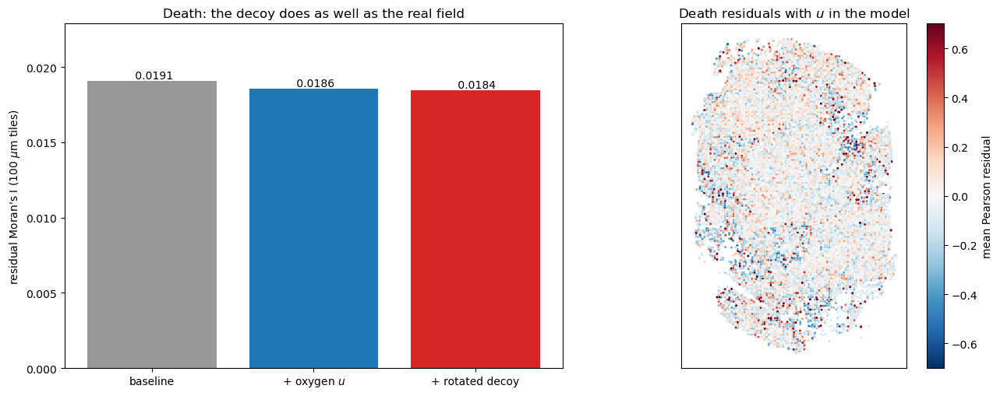

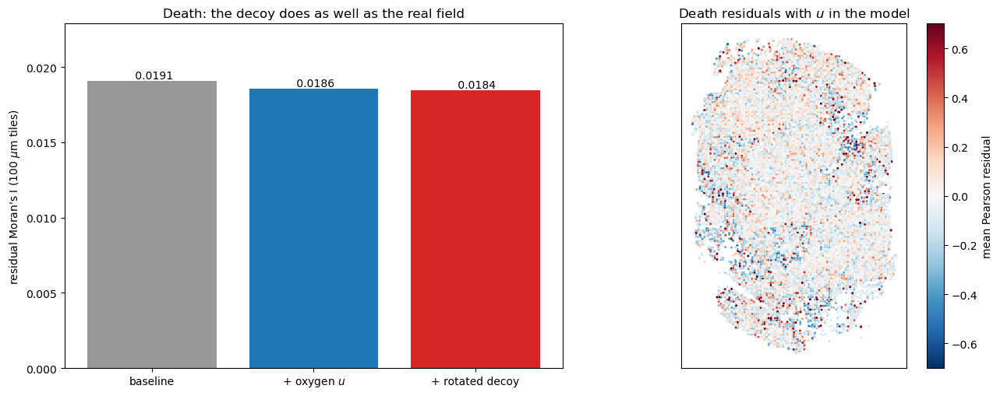

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
vals = [dth[t]["moran"] for t in ("base", "oxy", "rot")]
axes[0].bar(range(3), vals, color=["0.6", "C0", "C3"])
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(["baseline", "+ oxygen $u$", "+ rotated decoy"])
axes[0].set_ylabel("residual Moran's I (100 $\\mu$m tiles)")
axes[0].set_title("Death: the decoy does as well as the real field")
for i, v in enumerate(vals):
    axes[0].text(i, v, " %.4f" % v, ha="center", va="bottom")
axes[0].set_ylim(0, max(vals) * 1.2)

rl = float(np.nanpercentile(np.abs(tiles_d["resid_doxy_mean"]), 99))
sc_ = axes[1].scatter(tiles_d["x"], tiles_d["y"], c=tiles_d["resid_doxy_mean"], s=5,
                      cmap="RdBu_r", vmin=-rl, vmax=rl, linewidths=0)
fig.colorbar(sc_, ax=axes[1], fraction=0.046, pad=0.04, label="mean Pearson residual")
axes[1].set_aspect("equal"); axes[1].invert_yaxis(); axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title("Death residuals with $u$ in the model")
fig.tight_layout()
fig

### Verdict: a null — and one that strengthens §18

`u` does **not** belong in the death model:

- The effect is negligible — β = +0.0055, z = +2.1, χ² = 4.2 on 1 df (p ≈ 0.04).
  At n ≈ 6×10⁵ that is indistinguishable from nothing.
- **The decoy outperforms the real field**, with a larger likelihood gain
  (χ² 8.6 vs 4.2) and a slightly *lower* residual autocorrelation. When a
  biologically misaligned field beats the real one, the real one is contributing
  nothing specific.
- The sign is wrong for the perfusion story anyway: β is weakly **positive**,
  where perfusion predicts starved tissue should die *more*.

Part of this is a floor effect — the death model's residuals are already close to
spatially white (Moran's I ≈ 0.019 versus 0.088 for division; §14 found own +
neighbour state removes ~96% of the spatial structure in death), so there is
little left for any covariate to explain.

The value of this section is what it does for §18. Same machinery, same cells,
same decoy — and here it returns a clean null with the decoy winning. That is the
control behaving as designed, and it makes the division result harder to dismiss:
`u` beating the decoy ~13× for division while doing nothing for death is a
*specific* association with proliferation, not a generic "smooth covariate absorbs
smooth residual" artefact.

Reported on p-values alone this section would have read as a positive result at
p ≈ 0.04. The decoy is what prevents that mistake.

**Practical upshot:** use `covariate_keys=("cell_area", "oxygen_u")` for division,
and `("cell_area",)` for death.

## 20. Diagnosing the perfusion covariate: depth, diffusion range, and death

§18–19 left three questions worth settling, because each one could undermine the
covariate in a different way.

1. **Is `u` just a depth field?** It correlates with sequencing depth at ρ ≈ 0.57,
   and depth drives marker detection hard (§18). Settled in §18 by refitting with
   log-depth as a *free* coefficient on top of the offset: depth turns out to be
   genuinely mis-specified by the fixed offset (free coefficient −0.42, z = −33.7),
   yet β(u) barely moved, **+0.046 → +0.043 (z = +14.5)**. A depth proxy would
   have been absorbed. It wasn't.

2. **How far should the oxygen diffuse?** The §16 rasters look punctate, which
   invites raising `L0` to get a smoother, further-reaching field. That is
   testable, and it is the main experiment below.

3. **Why does `u` do nothing for death?** Addressed at the end.

The sweep below refits the division model with `u` computed at
`L0 ∈ {50, 100, 200, 400, 800}` µm, each with its own rotated decoy, so the
comparison controls for smoothness at every range. Runtime is a few minutes: each
`L0` needs its own 5.1M-unknown PDE solve plus three model fits.

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, gc
from scipy.stats import spearmanr
from tissue_dynamics import (
    read_xenium, read_phi_table, attach_phi, build_adjacency, average_neighbors,
    score_division, compute_library_size, compute_local_density,
    attach_oxygen_field, fit_division_nb, assign_tiles, aggregate_tiles, morans_i)
from tissue_dynamics.oxygen import sample_at_cells

DATA = "../data/Xenium_Prime_Breast_Cancer_FFPE"; REF = "Endothelial"
BLOOD = ["Endothelial ACKR1", "Endothelial RGS5", "Endothelial CXCL12"]

bc = read_xenium(DATA, sample_id="BC")
pt = read_phi_table("../data/phispace_normalised.csv", phi_cols="all")
bc = bc[bc.obs["cell_id"].isin(pt.index)].copy()
compute_library_size(bc); compute_local_density(bc, radius=50.0)
attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()
_n = bc.uns["phi_names"]; _k = [i for i, n in enumerate(_n) if n != REF]
bc.obsm["phi"] = bc.obsm["phi"][:, _k]; bc.uns["phi_names"] = [_n[i] for i in _k]
build_adjacency(bc, radius=80.0); average_neighbors(bc); score_division(bc)
bc.X = bc.layers["counts"]; del bc.layers["counts"]; gc.collect()

allc = pd.read_csv(f"{DATA}/cells.csv.gz", usecols=["cell_id", "x_centroid", "y_centroid"])
mp = pd.read_csv("../data/xenium_prime_celltype_minor_phispace.csv", usecols=["cell_id"] + BLOOD)
mp["phi_endo"] = mp[BLOOD].sum(1)
src = allc.merge(mp[["cell_id", "phi_endo"]], on="cell_id").dropna(subset=["phi_endo"])
SX = src[["x_centroid", "y_centroid"]].to_numpy(float); SP = src["phi_endo"].to_numpy(float)
RATE = dict(offset_key="log_total_counts", spline_keys=("local_density",), spline_df=5, fitter="irls")
print("prepared %d cells" % bc.n_obs, flush=True)

rows = []
for L0 in (50.0, 100.0, 200.0, 400.0, 800.0):
    res = attach_oxygen_field(bc, None, source_xy=SX, source_phi_endo=SP,
                              h=5.0, L0=L0, beta=1.0, c=0.15)
    uf, tf = res.u[::-1, ::-1], res.tissue[::-1, ::-1]        # the matched decoy at this L0
    ur, _, okr = sample_at_cells(uf, np.asarray(bc.obsm["spatial"]), res.origin, res.h, tissue=tf)
    bc.obs["u_rot"] = np.where(okr, ur, np.nan)
    sub = bc[(np.isfinite(bc.obs["oxygen_u"]) & np.isfinite(bc.obs["u_rot"])).to_numpy()].copy()

    fits = {}
    for tag, cov in [("b", ("cell_area",)), ("u", ("cell_area", "oxygen_u")),
                     ("d", ("cell_area", "u_rot"))]:
        f = fit_division_nb(sub, predictors="own+neighbor", interaction_rank=0,
                            covariate_keys=cov, **RATE)
        fits[tag] = dict(ll=f["loglik"],
                         beta=f["coef"].set_index("term").loc[cov[-1], "estimate"] if tag != "b" else np.nan,
                         z=f["coef"].set_index("term").loc[cov[-1], "z"] if tag != "b" else np.nan)
        sub.obs["r_" + tag] = f["pearson_resid"]
        del f; gc.collect()

    assign_tiles(sub, tile_size=100.0)
    t = aggregate_tiles(sub, phi_key=None, min_cells=5, obs_means=["r_b", "r_u", "r_d"])
    co = t[["x", "y"]].to_numpy()
    M = {k: morans_i(t["r_" + k + "_mean"].to_numpy(), coords=co, n_neighbors=8,
                     permutations=299)["I"] for k in ("b", "u", "d")}
    rows.append(dict(L0=L0, beta=fits["u"]["beta"], z=fits["u"]["z"],
                     LR=2*(fits["u"]["ll"] - fits["b"]["ll"]),
                     beta_decoy=fits["d"]["beta"], z_decoy=fits["d"]["z"],
                     M_base=M["b"], M_u=M["u"], M_decoy=M["d"],
                     red_u=M["b"] - M["u"], red_decoy=M["b"] - M["d"],
                     u_mean=float(np.nanmean(sub.obs["oxygen_u"])),
                     corr_depth=spearmanr(sub.obs["oxygen_u"], sub.obs["total_counts"]).statistic))
    print("L0=%4.0f um  beta=%+.4f z=%+5.1f  Moran %.4f->%.4f (decoy %.4f)"
          % (L0, rows[-1]["beta"], rows[-1]["z"], M["b"], M["u"], M["d"]), flush=True)
    del sub, res, t; gc.collect()

sweep = pd.DataFrame(rows)
sweep["ratio"] = sweep["red_u"] / sweep["red_decoy"].clip(lower=1e-9)
print()
print(sweep[["L0", "beta", "z", "LR", "red_u", "red_decoy", "ratio",
             "u_mean", "corr_depth"]].round(4).to_string(index=False))

/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_15917/3949511334.py:14: UserWarning: spatialdata-io failed to read this sample (FileNotFoundError(2, 'No such file or directory')); falling back to the manual cell_feature_matrix reader.
  bc = read_xenium(DATA, sample_id="BC")


/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_15917/3949511334.py:18: UserWarning: 3592/683798 cells have a NaN phi embedding (a matched row exists, but with missing values -- typically near-empty segmentation artifacts the embedding method couldn't score). These will propagate NaNs into neighbor-averaging and model fitting; filter them out first, e.g. `adata = adata[~np.isnan(adata.obsm['phi']).any(axis=1)].copy()`.
  attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()


/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_15917/3949511334.py:21: UserWarning: 54/680206 cells have no spatial neighbors within radius=80.0 (isolated); their neighbor-averaged embedding will be the zero vector.
  build_adjacency(bc, radius=80.0); average_neighbors(bc); score_division(bc)


prepared 680206 cells


L0=  50 um  beta=+0.0217 z= +7.7  Moran 0.0876->0.0847 (decoy 0.0874)


L0= 100 um  beta=+0.0462 z=+15.2  Moran 0.0876->0.0819 (decoy 0.0872)


L0= 200 um  beta=+0.0537 z=+16.6  Moran 0.0876->0.0827 (decoy 0.0870)


L0= 400 um  beta=+0.0382 z=+11.6  Moran 0.0876->0.0857 (decoy 0.0867)


L0= 800 um  beta=+0.0190 z= +6.1  Moran 0.0876->0.0873 (decoy 0.0868)



   L0   beta       z       LR  red_u  red_decoy   ratio  u_mean  corr_depth
 50.0 0.0217  7.7014  55.2288 0.0029     0.0003 10.7261  0.0427      0.2661
100.0 0.0462 15.1830 230.6615 0.0058     0.0004 14.1292  0.1394      0.3130
200.0 0.0537 16.6421 282.2226 0.0049     0.0007  7.2944  0.3636      0.3443
400.0 0.0382 11.6498 137.6172 0.0019     0.0010  1.9918  0.6664      0.3574
800.0 0.0190  6.0680  36.9335 0.0003     0.0008  0.3956  0.8790      0.3609


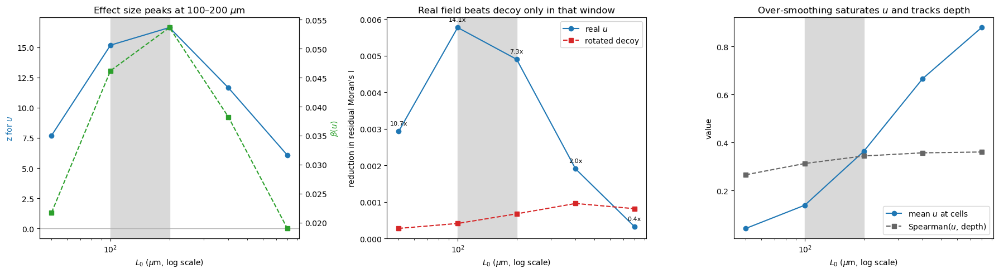

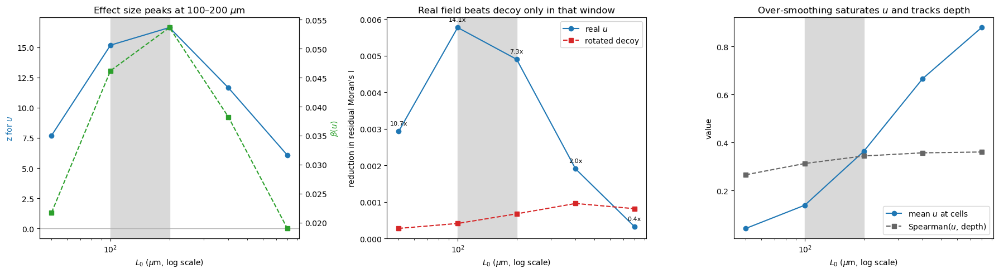

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
L = sweep["L0"]

axes[0].plot(L, sweep["z"], "o-", color="C0")
axes[0].set_xscale("log"); axes[0].set_xlabel(r"$L_0$ ($\mu$m, log scale)")
axes[0].set_ylabel("z for $u$", color="C0"); axes[0].axhline(0, color="0.7", lw=1)
ax0b = axes[0].twinx(); ax0b.plot(L, sweep["beta"], "s--", color="C2")
ax0b.set_ylabel(r"$\beta(u)$", color="C2")
axes[0].axvspan(100, 200, color="0.85", zorder=0)
axes[0].set_title("Effect size peaks at 100–200 $\\mu$m")

axes[1].plot(L, sweep["red_u"], "o-", color="C0", label="real $u$")
axes[1].plot(L, sweep["red_decoy"], "s--", color="C3", label="rotated decoy")
axes[1].set_xscale("log"); axes[1].set_xlabel(r"$L_0$ ($\mu$m, log scale)")
axes[1].set_ylabel("reduction in residual Moran's I")
axes[1].axhline(0, color="0.7", lw=1); axes[1].axvspan(100, 200, color="0.85", zorder=0)
for x, y, r in zip(L, sweep["red_u"], sweep["ratio"]):
    axes[1].annotate("%.1fx" % r, (x, y), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=8)
axes[1].legend(); axes[1].set_title("Real field beats decoy only in that window")

axes[2].plot(L, sweep["u_mean"], "o-", color="C0", label="mean $u$ at cells")
axes[2].plot(L, sweep["corr_depth"], "s--", color="0.4", label=r"Spearman($u$, depth)")
axes[2].set_xscale("log"); axes[2].set_xlabel(r"$L_0$ ($\mu$m, log scale)")
axes[2].set_ylabel("value"); axes[2].axvspan(100, 200, color="0.85", zorder=0)
axes[2].legend(); axes[2].set_title("Over-smoothing saturates $u$ and tracks depth")
fig.tight_layout()
fig

### Verdict on the diffusion range: it is already about right

Expanding the diffusion helps slightly, then hurts sharply.

- `L0 = 200` gives the strongest coefficient (β ≈ +0.054, z ≈ 16.6, LR ≈ 282
  against 231 at 100 µm).
- `L0 = 100` gives the best *specificity*: the largest reduction in residual
  Moran's I and the widest margin over the matched decoy (**≈14×** versus ≈7×
  at 200 µm).
- By `L0 = 800` the real field is **worse than the decoy** (ratio ≈ 0.4). Mean `u`
  has risen to ≈ 0.88, so almost all tissue reads as well-oxygenated and there is
  no contrast left to exploit, while `Spearman(u, depth)` has climbed from 0.27 to
  0.36 — the field is degenerating into a smoothed density map.

**The non-monotonicity is the result, not the chosen optimum.** If `u` helped
merely by being a smooth spatial field, performance would rise with `L0`
indefinitely — that is exactly what the decoy does best at long range. Instead the
real field peaks and then falls below its own decoy. That the peak lands at
100–200 µm, the textbook oxygen diffusion limit, is genuine independent evidence
that the field tracks something oxygen-like rather than arbitrary smoothing — and
notably it comes from the model, not from the HIF markers that failed in §17.

So the sharp gradients in §16 are close to optimal rather than a defect:
sharpening below 100 µm and over-smoothing above 200 µm both degrade the fit.
**Recommendation: keep `L0 = 100`**, since the decoy margin is the evidence that
the effect is specific; `L0 = 200` is equally defensible if the larger coefficient
matters more. The limitation that *no* choice of `L0` can fix is the 2D one — the
field cannot see supply from above or below the section.

### Why `u` does nothing for the death model

§19 found a clean null, with the decoy outperforming the real field. The likeliest
explanation is the **death readout**, not the perfusion field, and there is a
logical argument for that: the same field, the same cells and the same machinery
work for division. A covariate that predicts one process and not the other is
evidence about the process.

Three specific reasons, in rough order of weight:

1. **Hypoxic death is necrotic, and necrosis is censored.** Apoptosis is
   ATP-dependent; severe oxygen starvation kills by necrosis instead. So the mode
   of death `u` ought to predict is precisely the one an *apoptosis* signature
   cannot see. Worse, cells that actually died are lysed, phagocytosed or
   unsegmentable, so they never enter the count matrix at all. We are modelling a
   survivor population, and death-by-hypoxia is systematically removed from it —
   a censoring problem no covariate can repair.
2. **Transcription is a poor readout for apoptosis.** Apoptosis is executed
   post-translationally, by cleavage of caspase zymogens that are already present;
   the counts we sum report apoptotic *priming*, not commitment. §14's
   near-Poisson dispersion (α ≈ 0.068, against 0.77 for the cell-cycle counts) is
   what a signature of steady-state machinery looks like, not a rare event.
3. **Floor effect.** Death residuals were already close to spatially white
   (Moran's I ≈ 0.019 versus 0.088 for division); §14 found own + neighbour state
   removes ~96% of the spatial structure in death. There was very little left for
   any covariate to explain.

This is worth stating plainly for the thesis: the death null is **not** evidence
against the perfusion field. It is evidence that apoptosis transcript counts are a
weak proxy for cell death, which is a limitation of the readout that would apply
to any covariate tested against it.

## 21. Offset or free covariate for library size?

Every count model so far has carried log library size as an **offset**, which
pins its coefficient at exactly 1 — the assumption that signature counts scale
*proportionally* with sequencing depth. §18 already hinted that assumption is
wrong for division. Here we test it directly by refitting both models with depth
as a **free covariate** instead, and asking whether the rootogram improves.

Three things are checked, because a change in log-likelihood alone would not
justify the switch:

1. **Fit and calibration** — rootogram and PIT, not just log-likelihood.
2. **The implied exponent** — a free (standardized) coefficient converts to
   `d log mu / d log T = beta / sd(log T)`, directly comparable to the offset's 1.
3. **Coefficient stability** — the offset is what makes this a *rate* model, so
   `own[...]`/`nbr[...]` currently read "per transcript". If dropping it moves the
   state coefficients materially, the interpretation changes with it.

A `cell_area` spline is tested at the same time, since cell area currently enters
as a single standardized *linear* term while density gets a natural-cubic basis.

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, gc
from scipy.stats import chi2
from tissue_dynamics import (
    read_xenium, read_phi_table, attach_phi, build_adjacency, average_neighbors,
    score_division, compute_library_size, compute_local_density,
    fit_division_nb, fit_death_nb, get_signature_counts)
from tissue_dynamics.plotting import _rootogram_counts, _pit_histogram
from tissue_dynamics.gene_sets import TIROSH_S_GENES, TIROSH_G2M_GENES, APOPTOSIS_SIGNATURE

DATA = "../data/Xenium_Prime_Breast_Cancer_FFPE"; REF = "Endothelial"
bc = read_xenium(DATA, sample_id="BC")
pt = read_phi_table("../data/phispace_normalised.csv", phi_cols="all")
bc = bc[bc.obs["cell_id"].isin(pt.index)].copy()
compute_library_size(bc); compute_local_density(bc, radius=50.0)
attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()
_n = bc.uns["phi_names"]; _k = [i for i, n in enumerate(_n) if n != REF]
bc.obsm["phi"] = bc.obsm["phi"][:, _k]; bc.uns["phi_names"] = [_n[i] for i in _k]
build_adjacency(bc, radius=80.0); average_neighbors(bc); score_division(bc)
bc.X = bc.layers["counts"]; del bc.layers["counts"]; gc.collect()
SD_LOGT = float(bc.obs["log_total_counts"].std())
print("prepared %d cells | sd(log total counts) = %.4f" % (bc.n_obs, SD_LOGT), flush=True)

OFF     = dict(offset_key="log_total_counts", spline_keys=("local_density",), spline_df=5,
               covariate_keys=("cell_area",), fitter="irls")
FREE    = dict(offset_key=None, spline_keys=("local_density",), spline_df=5,
               covariate_keys=("log_total_counts", "cell_area"), fitter="irls")
AREASPL = dict(offset_key=None, spline_keys=("local_density", "cell_area"), spline_df=5,
               covariate_keys=("log_total_counts",), fitter="irls")
DIVG = list(dict.fromkeys(list(TIROSH_S_GENES) + list(TIROSH_G2M_GENES)))

def evaluate(fn, genes, kmax, cfg):
    f = fn(bc, predictors="own+neighbor", interaction_rank=0, **cfg)
    y, _t, _g = get_signature_counts(bc, genes)
    ks, obs, exp = _rootogram_counts(y, f["fitted_mu"], f["alpha"], max_count=kmax)
    _e, h = _pit_histogram(y, f["fitted_mu"], f["alpha"], n_bins=10)
    cf = f["coef"].set_index("term")
    out = dict(alpha=f["alpha"], loglik=f["loglik"], k=f["n_params"], ks=ks, obs=obs, exp=exp,
               disc=np.sqrt(obs) - np.sqrt(exp), pit=float(np.max(np.abs(h - 1))),
               state=cf[cf.index.str.startswith(("own[", "nbr["))][["estimate", "std_error", "z"]],
               beta_depth=float(cf.loc["log_total_counts", "estimate"]) if "log_total_counts" in cf.index else np.nan)
    del f, y; gc.collect()
    return out

R = {}
R[("div", "offset")] = evaluate(fit_division_nb, DIVG, 12, OFF)
R[("div", "free")]   = evaluate(fit_division_nb, DIVG, 12, FREE)
R[("div", "areaspl")]= evaluate(fit_division_nb, DIVG, 12, AREASPL)
R[("dth", "offset")] = evaluate(fit_death_nb, list(APOPTOSIS_SIGNATURE), 8, OFF)
R[("dth", "free")]   = evaluate(fit_death_nb, list(APOPTOSIS_SIGNATURE), 8, FREE)

print("\n%-9s %-22s %7s %11s %3s %9s %9s %8s" %
      ("model", "depth term", "alpha", "loglik", "k", "PIT|dev|", "root RMS", "root max"))
for (m, v), r in R.items():
    print("%-9s %-22s %7.4f %11.1f %3d %9.4f %9.1f %8.1f"
          % (m, v, r["alpha"], r["loglik"], r["k"], r["pit"],
             np.sqrt(np.mean(r["disc"] ** 2)), np.max(np.abs(r["disc"]))))

for m, kmax in (("div", 12), ("dth", 8)):
    a, b = R[(m, "offset")], R[(m, "free")]
    lr = 2 * (b["loglik"] - a["loglik"])
    print("\n%s: offset -> free depth  LR chi2=%.1f df=1 p=%.1e" % (m.upper(), lr, chi2.sf(lr, 1)))
    print("   implied exponent d(log mu)/d(log T) = %.3f   (offset assumes exactly 1.000)"
          % (b["beta_depth"] / SD_LOGT))
lr_a = 2 * (R[("div", "areaspl")]["loglik"] - R[("div", "free")]["loglik"])
print("\nDIVISION: cell-area linear -> spline  LR chi2=%.1f df=4 p=%.1e (rootogram RMS %.1f -> %.1f)"
      % (lr_a, chi2.sf(lr_a, 4), np.sqrt(np.mean(R[("div","free")]["disc"]**2)),
         np.sqrt(np.mean(R[("div","areaspl")]["disc"]**2))))

/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_27689/137835276.py:13: UserWarning: spatialdata-io failed to read this sample (FileNotFoundError(2, 'No such file or directory')); falling back to the manual cell_feature_matrix reader.
  bc = read_xenium(DATA, sample_id="BC")


/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_27689/137835276.py:17: UserWarning: 3592/683798 cells have a NaN phi embedding (a matched row exists, but with missing values -- typically near-empty segmentation artifacts the embedding method couldn't score). These will propagate NaNs into neighbor-averaging and model fitting; filter them out first, e.g. `adata = adata[~np.isnan(adata.obsm['phi']).any(axis=1)].copy()`.
  attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()


/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_27689/137835276.py:20: UserWarning: 54/680206 cells have no spatial neighbors within radius=80.0 (isolated); their neighbor-averaged embedding will be the zero vector.
  build_adjacency(bc, radius=80.0); average_neighbors(bc); score_division(bc)


prepared 680206 cells | sd(log total counts) = 1.4473



model     depth term               alpha      loglik   k  PIT|dev|  root RMS root max
div       offset                  0.7735   -611864.0  23    0.0494       7.7     18.7
div       free                    0.7049   -610983.7  24    0.0397       6.3     13.4
div       areaspl                 0.7027   -610945.4  28    0.0393       6.4     13.5
dth       offset                  0.0676   -491395.0  23    0.0123       1.5      3.7
dth       free                    0.0669   -491362.6  24    0.0110       1.8      4.4

DIV: offset -> free depth  LR chi2=1760.6 df=1 p=0.0e+00
   implied exponent d(log mu)/d(log T) = 0.703   (offset assumes exactly 1.000)

DTH: offset -> free depth  LR chi2=64.8 df=1 p=8.2e-16
   implied exponent d(log mu)/d(log T) = 0.934   (offset assumes exactly 1.000)

DIVISION: cell-area linear -> spline  LR chi2=76.5 df=4 p=9.4e-16 (rootogram RMS 6.3 -> 6.4)


In [2]:
print("state coefficients: offset vs free depth\n")
stab = {}
for m in ("div", "dth"):
    a, b = R[(m, "offset")]["state"], R[(m, "free")]["state"]
    j = a.join(b, lsuffix="_off", rsuffix="_free")
    j["delta"] = j["estimate_free"] - j["estimate_off"]
    j["d_over_se"] = (j["delta"] / j["std_error_off"]).abs()
    stab[m] = j
    sig_o = set(j.index[j["z_off"].abs() > 3]); sig_f = set(j.index[j["z_free"].abs() > 3])
    print("%s  Pearson r=%.4f  max|delta|=%.3f  max|delta|/SE=%.2f  sign flips=%d"
          % (m.upper(), j["estimate_off"].corr(j["estimate_free"]), j["delta"].abs().max(),
             j["d_over_se"].max(), int((np.sign(j["estimate_off"]) != np.sign(j["estimate_free"])).sum())))
    print("   |z|>3 in offset: %d, in free: %d | changes status: %s"
          % (len(sig_o), len(sig_f), sorted(sig_o ^ sig_f) or "none"))
    print(j.sort_values("d_over_se", ascending=False)
           [["estimate_off", "estimate_free", "delta", "z_off", "z_free"]].head(5).round(3).to_string())
    print()

state coefficients: offset vs free depth

DIV  Pearson r=0.9948  max|delta|=0.184  max|delta|/SE=9.22  sign flips=0
   |z|>3 in offset: 14, in free: 13 | changes status: ['nbr[CAFs]', 'own[Myeloid]', 'own[PVL]']
                        estimate_off  estimate_free  delta   z_off  z_free
term                                                                      
own[Plasmablasts]              0.249          0.389  0.141  16.278  25.062
own[PVL]                       0.121          0.302  0.181   2.763   7.031
own[Cancer Epithelial]         1.198          1.124 -0.074  55.632  52.734
nbr[Normal Epithelial]        -1.523         -1.341  0.181 -14.139 -12.804
own[Myeloid]                  -0.114         -0.066  0.048  -3.730  -2.189

DTH  Pearson r=0.9988  max|delta|=0.041  max|delta|/SE=2.23  sign flips=1
   |z|>3 in offset: 9, in free: 10 | changes status: ['own[Plasmablasts]']
                        estimate_off  estimate_free  delta   z_off  z_free
term                                  

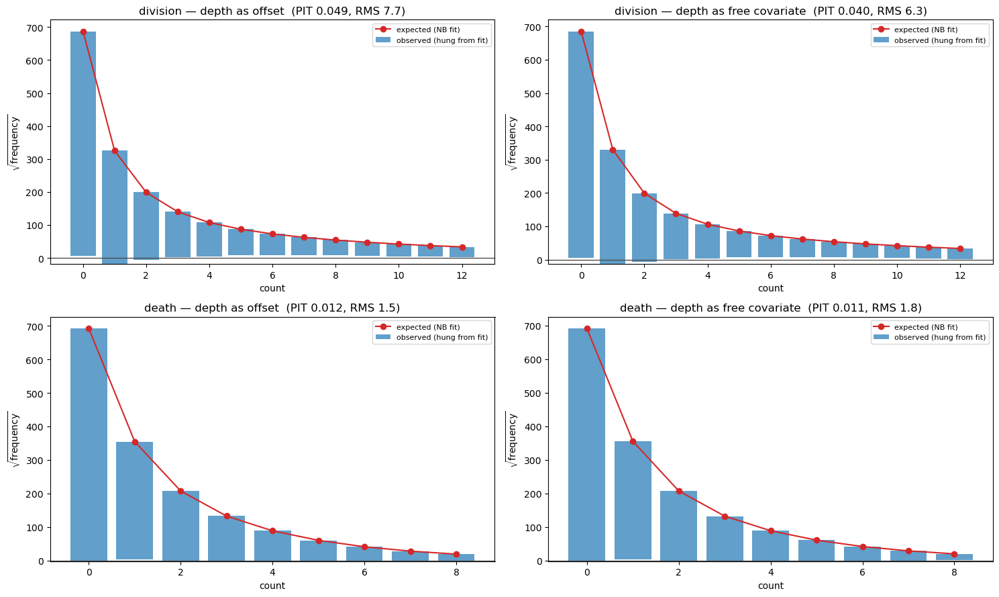

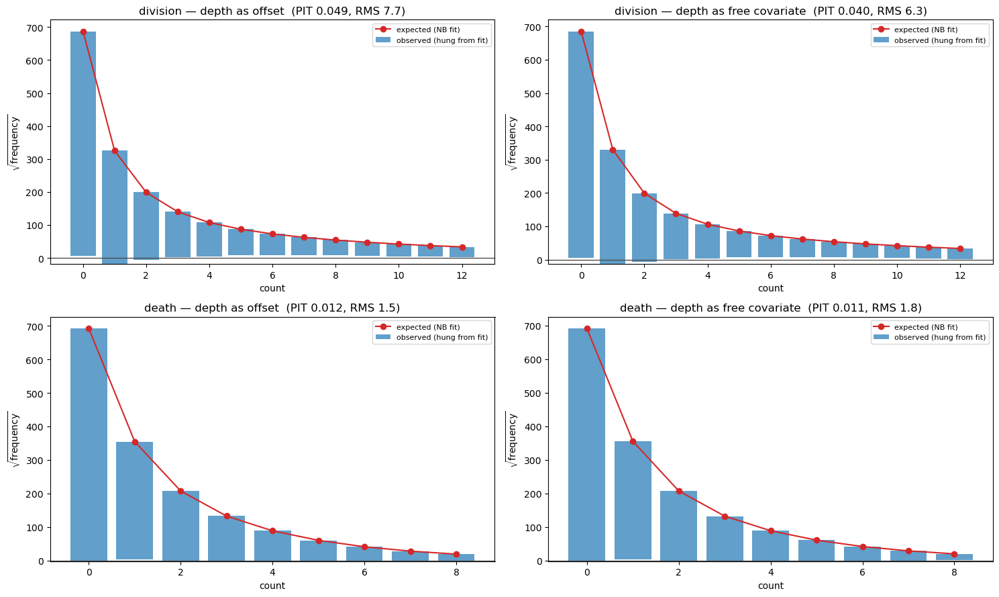

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for row, (m, fn_lab) in enumerate([("div", "division"), ("dth", "death")]):
    for col, v in enumerate(("offset", "free")):
        r = R[(m, v)]; ax = axes[row, col]
        se, so = np.sqrt(r["exp"]), np.sqrt(r["obs"])
        ax.bar(r["ks"], so, bottom=se - so, width=0.8, color="C0", alpha=0.7,
               label="observed (hung from fit)")
        ax.plot(r["ks"], se, "o-", color="C3", label="expected (NB fit)")
        ax.axhline(0.0, color="0.3", lw=1)
        ax.set_xlabel("count"); ax.set_ylabel(r"$\sqrt{\mathrm{frequency}}$")
        ax.set_title("%s — depth as %s  (PIT %.3f, RMS %.1f)"
                     % (fn_lab, "offset" if v == "offset" else "free covariate",
                        r["pit"], np.sqrt(np.mean(r["disc"] ** 2))))
        ax.legend(fontsize=8)
fig.tight_layout()
fig

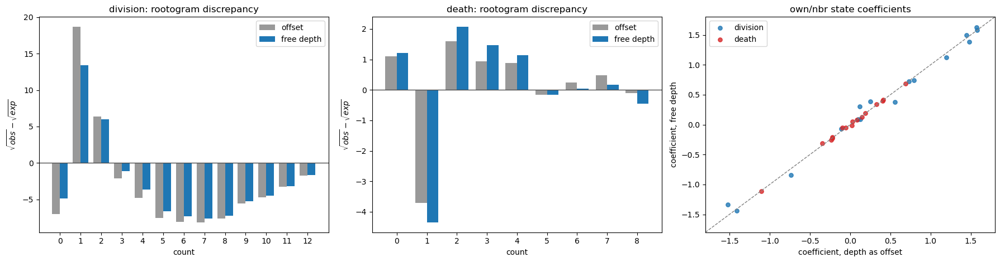

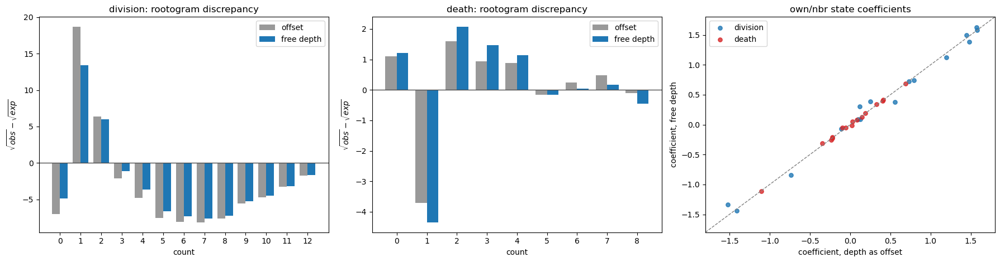

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (m, lab) in zip(axes[:2], [("div", "division"), ("dth", "death")]):
    a, b = R[(m, "offset")], R[(m, "free")]
    w = 0.38; x = np.arange(len(a["ks"]))
    ax.bar(x - w/2, a["disc"], w, label="offset", color="0.6")
    ax.bar(x + w/2, b["disc"], w, label="free depth", color="C0")
    ax.axhline(0, color="0.3", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(a["ks"])
    ax.set_xlabel("count"); ax.set_ylabel(r"$\sqrt{obs}-\sqrt{exp}$")
    ax.set_title("%s: rootogram discrepancy" % lab); ax.legend()

for m, c, lab in (("div", "C0", "division"), ("dth", "C3", "death")):
    j = stab[m]
    axes[2].scatter(j["estimate_off"], j["estimate_free"], s=28, color=c, label=lab, alpha=0.8)
lim = [-1.8, 1.8]
axes[2].plot(lim, lim, "--", color="0.5", lw=1)
axes[2].set_xlim(lim); axes[2].set_ylim(lim)
axes[2].set_xlabel("coefficient, depth as offset"); axes[2].set_ylabel("coefficient, free depth")
axes[2].set_title("own/nbr state coefficients"); axes[2].legend()
fig.tight_layout()
fig

### Verdict: free the depth term for division, keep the offset for death

**The two models behave oppositely, and the reason is the exponent.** A free
(standardized) depth coefficient converts to `beta / sd(log T)` with
`sd(log T) = 1.447`:

| model | implied `d log mu / d log T` | offset assumes |
|---|---:|---:|
| division | **0.703** | 1.000 |
| death | **0.934** | 1.000 |

Division counts scale markedly **sub-proportionally** with depth, so pinning the
coefficient at 1 is badly wrong; death counts are close to proportional, so the
offset is nearly right already. Everything else follows from that.

**Division — freeing depth clearly improves the fit.** The log-likelihood rises by
880 (LR χ² ≈ 1761 on 1 df), the dispersion falls **0.77 → 0.70** (some of what the
NB was absorbing as overdispersion was really depth mis-specification), the PIT
flattens (0.049 → 0.040) and the rootogram misfit shrinks about 20% (RMS 7.7 →
6.3, worst count 18.7 → 13.4). Every diagnostic agrees, for one extra parameter.

**Death — the likelihood improves but the rootogram gets worse.** LR χ² ≈ 65
(p ≈ 8e-16), yet the rootogram degrades (RMS 1.5 → 1.8, worst count 3.7 → 4.4)
while the PIT barely moves (0.0123 → 0.0110 — a difference small enough to sit in
fitter-level numerical noise, and one that flips sign between the statsmodels and
IRLS backends). So the likelihood gain buys nothing real: 65 log-likelihood units
out of ~491,000 at n ≈ 6.8×10⁵ is a trivial relative improvement, and the shape
diagnostic that matters gets worse. A clean reminder that likelihood and
calibration are different criteria, and that at this n the former is close to
useless on its own.

**What freeing depth does *not* fix.** The §11 defects keep their shape: an excess
of exactly-1 counts and systematic over-prediction across counts 5–8. Every count
improves by roughly 15–25%, none disappears. That misfit is **structural** — the
signature of a zero-inflation/hurdle-like feature — not a scaling artefact, and it
will not be repaired by a better depth term.

**Coefficient stability — mostly, with a caveat.** The state coefficients are
highly stable (Pearson r = 0.995 division, 0.999 death; the single death sign flip
is `nbr[CAFs]`, non-significant under both) and every headline effect is
untouched: `own[T-cells]`, `own[Cancer Epithelial]`, `own[B-cells]`, `own[CAFs]`,
`nbr[Cancer Epithelial]`, `nbr[Normal Epithelial]` keep their size and huge |z|
under both specifications. But *marginal* terms move enough to matter — the
largest shift is **9.2 standard errors** (`own[Plasmablasts]`, 0.249 → 0.389) —
and three division terms change significance status: `own[PVL]` (z 2.8 → 7.0) and
`own[Plasmablasts]` strengthen, while `nbr[CAFs]` and `own[Myeloid]` fall below
|z| = 3. So the biology is robust while borderline calls are not, and any claim
resting on a marginal term should be reported under both specifications.

**Cell area: keep it linear.** Splining it is significant (LR χ² ≈ 77 on 4 df) but
buys nothing — the rootogram RMS is unchanged to slightly worse (6.3 → 6.4). At
this n significance is not the relevant test; calibration is, and it says no.

**One interpretive cost.** The offset is what makes this a *rate* model, so
`own[...]`/`nbr[...]` currently read as effects "per transcript captured". With
depth free they become effects on the count at a freely-fitted depth scaling.
Given the exponent is 0.703 rather than 1, the rate framing was never quite right
for division anyway — which is an argument for the switch, not against it.

## 22. What the response variables actually look like

Everything above models two count variables — the summed division signature
(Tirosh S+G2M) and the summed apoptosis signature — so it is worth seeing their
raw distributions plainly. These histograms are the reason several modelling
choices were forced rather than chosen: the heavy zero mass and long right tail
are why the family is negative binomial rather than Gaussian, and the difference
in dispersion between the two is why they behave so differently in §21.

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tissue_dynamics import (read_xenium, read_phi_table, attach_phi,
                             compute_library_size, get_signature_counts)
from tissue_dynamics.gene_sets import TIROSH_S_GENES, TIROSH_G2M_GENES, APOPTOSIS_SIGNATURE

DATA = "../data/Xenium_Prime_Breast_Cancer_FFPE"
bc = read_xenium(DATA, sample_id="BC")
pt = read_phi_table("../data/phispace_normalised.csv", phi_cols="all")
bc = bc[bc.obs["cell_id"].isin(pt.index)].copy()
attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()
compute_library_size(bc)

DIVG = list(dict.fromkeys(list(TIROSH_S_GENES) + list(TIROSH_G2M_GENES)))
y_div, total, div_genes = get_signature_counts(bc, DIVG)
y_dth, _t, dth_genes = get_signature_counts(bc, list(APOPTOSIS_SIGNATURE))

print("%d cells (the modelled set)\n" % bc.n_obs)
print("%-12s %6s %8s %8s %9s %9s %6s %8s" %
      ("signature", "genes", "%cells>0", "mean", "variance", "var/mean", "max", "%zeros"))
for lab, y, g in (("division", y_div, div_genes), ("death", y_dth, dth_genes)):
    print("%-12s %6d %8.1f %8.3f %9.3f %9.2f %6d %8.1f"
          % (lab, len(g), 100*(y > 0).mean(), y.mean(), y.var(),
             y.var()/y.mean(), int(y.max()), 100*(y == 0).mean()))
print("\nquantiles (50/75/90/95/99/99.9%):")
for lab, y in (("division", y_div), ("death", y_dth)):
    print("  %-9s %s" % (lab, np.quantile(y, [.5, .75, .9, .95, .99, .999]).astype(int)))
print("\nlibrary size: median %.0f transcripts/cell (log sd %.3f)"
      % (np.median(total), bc.obs["log_total_counts"].std()))

/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_25405/794037795.py:9: UserWarning: spatialdata-io failed to read this sample (FileNotFoundError(2, 'No such file or directory')); falling back to the manual cell_feature_matrix reader.
  bc = read_xenium(DATA, sample_id="BC")


/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_25405/794037795.py:12: UserWarning: 3592/683798 cells have a NaN phi embedding (a matched row exists, but with missing values -- typically near-empty segmentation artifacts the embedding method couldn't score). These will propagate NaNs into neighbor-averaging and model fitting; filter them out first, e.g. `adata = adata[~np.isnan(adata.obsm['phi']).any(axis=1)].copy()`.
  attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()


680206 cells (the modelled set)

signature     genes %cells>0     mean  variance  var/mean    max   %zeros
division         53     32.0    0.868     6.793      7.83    111     68.0
death            25     29.4    0.497     0.991      1.99     16     70.6

quantiles (50/75/90/95/99/99.9%):
  division  [ 0  1  2  4 13 31]
  death     [0 1 2 2 5 8]

library size: median 52 transcripts/cell (log sd 1.447)


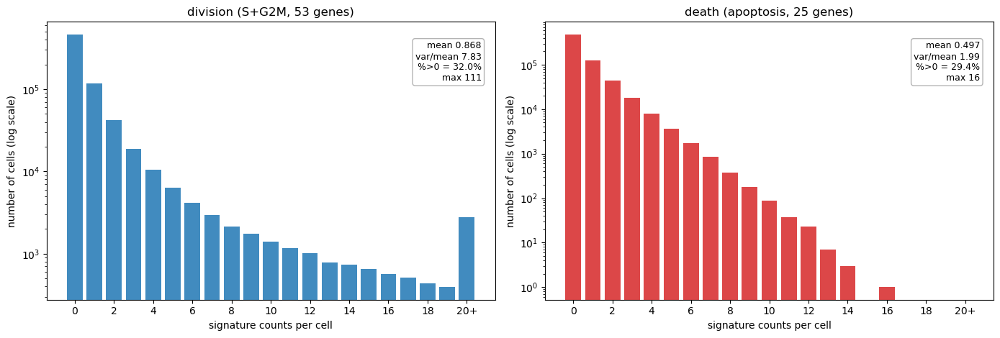

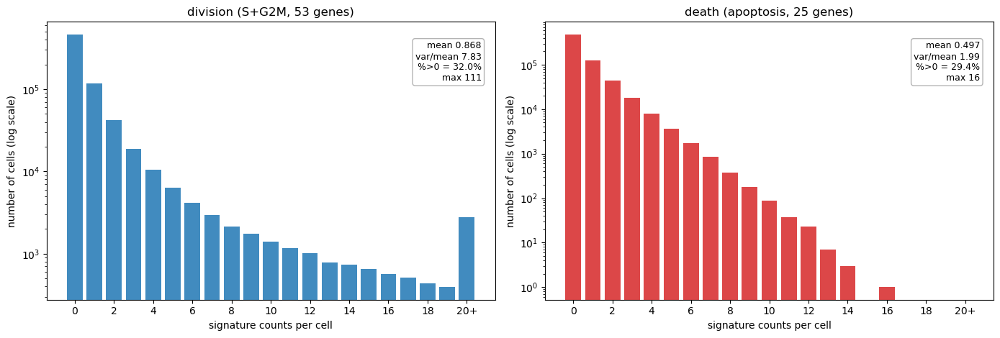

In [2]:
KMAX = 20
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (lab, y, col) in zip(axes, [("division (S+G2M, %d genes)" % len(div_genes), y_div, "C0"),
                                    ("death (apoptosis, %d genes)" % len(dth_genes), y_dth, "C3")]):
    counts = np.array([(y == k).sum() for k in range(KMAX)] + [(y >= KMAX).sum()], dtype=float)
    ax.bar(np.arange(KMAX + 1), counts, color=col, alpha=0.85)
    ax.set_yscale("log")
    ax.set_xticks(list(range(0, KMAX, 2)) + [KMAX])
    ax.set_xticklabels([str(k) for k in range(0, KMAX, 2)] + ["%d+" % KMAX])
    ax.set_xlabel("signature counts per cell"); ax.set_ylabel("number of cells (log scale)")
    ax.set_title(lab)
    ax.text(0.97, 0.93, "mean %.3f\nvar/mean %.2f\n%%>0 = %.1f%%\nmax %d"
            % (y.mean(), y.var()/y.mean(), 100*(y > 0).mean(), int(y.max())),
            transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", ec="0.7"))
fig.tight_layout()
fig

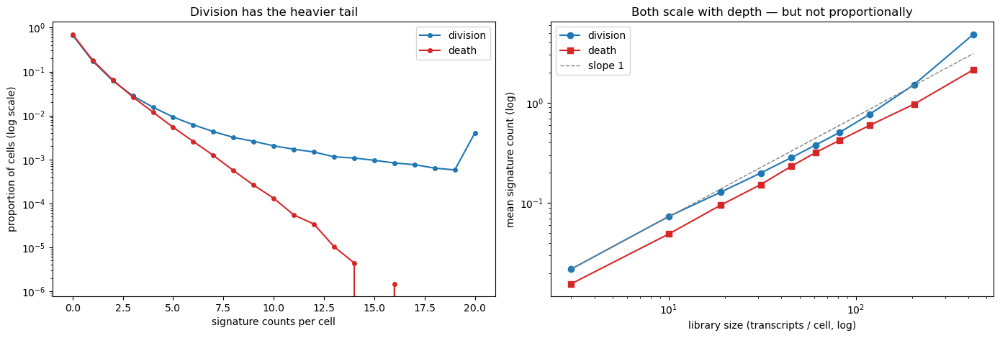

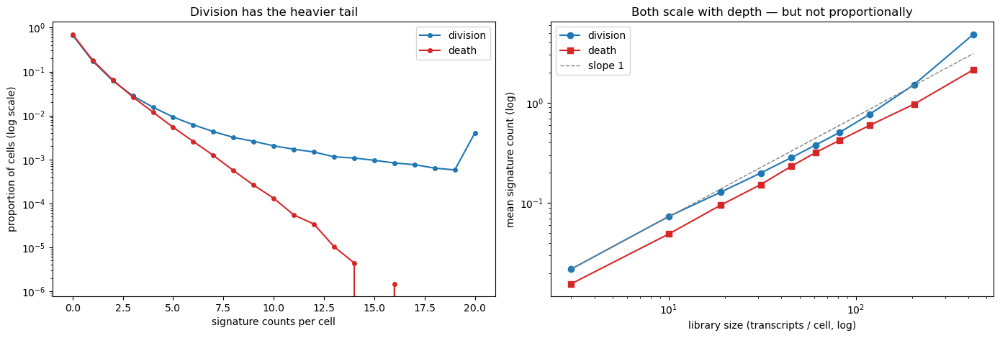

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# overlay as proportions, so the two signatures are directly comparable
for lab, y, col in (("division", y_div, "C0"), ("death", y_dth, "C3")):
    p = np.array([(y == k).mean() for k in range(KMAX)] + [(y >= KMAX).mean()])
    axes[0].plot(np.arange(KMAX + 1), p, "o-", ms=4, color=col, label=lab)
axes[0].set_yscale("log"); axes[0].set_xlabel("signature counts per cell")
axes[0].set_ylabel("proportion of cells (log scale)")
axes[0].set_title("Division has the heavier tail"); axes[0].legend()

# the depth relationship that dominates every model in this notebook
dec = pd.qcut(total, 10, labels=False, duplicates="drop")
d = pd.DataFrame({"dec": dec, "tot": total, "div": y_div, "dth": y_dth})
g = d.groupby("dec").agg(tot=("tot", "median"), div=("div", "mean"), dth=("dth", "mean"))
axes[1].plot(g["tot"], g["div"], "o-", color="C0", label="division")
axes[1].plot(g["tot"], g["dth"], "s-", color="C3", label="death")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("library size (transcripts / cell, log)")
axes[1].set_ylabel("mean signature count (log)")
axes[1].set_title("Both scale with depth — but not proportionally"); axes[1].legend()
# reference slope 1 (what the offset assumes)
x0, x1 = g["tot"].iloc[0], g["tot"].iloc[-1]
y0 = g["div"].iloc[0]
axes[1].plot([x0, x1], [y0, y0 * (x1/x0)], "--", color="0.5", lw=1, label="slope 1")
axes[1].legend()
fig.tight_layout()
fig

Three things in these plots drive decisions made earlier in the notebook.

**Both distributions are zero-dominated with long tails.** Division is 0 in 68%
of cells yet reaches 111; death is 0 in 71% and reaches 16. A Gaussian model is
obviously wrong here, and the log-scale y-axis is the only way to see the tail at
all.

**Division is far more over-dispersed than death** (var/mean ≈ 7.9 versus ≈ 2.0).
That single fact explains the fitted dispersions (α ≈ 0.77 versus ≈ 0.07) and is
why the two models responded so differently to freeing the depth term in §21 —
there is much more excess variance for the division model to reallocate.

**The right-hand panel is the depth relationship in raw form.** Both signatures
climb with library size, but the dashed line shows what proportional scaling
(the offset's assumption, slope 1 on log–log axes) would look like. Division
rises visibly more slowly than that reference — the graphical version of the
0.693 exponent measured in §21 — while death tracks it much more closely (0.922).
That is the whole reason the offset suits one model and not the other.

## 23. Marker-count distributions by cell type

§22 showed the two response variables pooled over all cells. Splitting them by
cell type asks a different question: is the division/death signal concentrated in
particular populations, or spread evenly?

Assigning a discrete type needs care. A plain argmax over the nine
`celltype_major` scores **does not work**, because the columns are on wildly
different scales: `Plasmablasts` has sd 3.55 and reaches 22, while `CAFs` has sd
0.24 and a maximum of 0.21 — below most other columns' means, so CAFs can
essentially never win. Raw argmax duly returns 42% Endothelial (median library
**15** transcripts) and 0.17% CAFs, which is not a breast tumour; it is a readout
of column scale and sequencing depth.

Each column is therefore **z-scored before the argmax**, so the call is "which
type is this cell most unusually high for". The first cell below shows both, so
the difference is visible rather than asserted. Even the corrected labels are a
rough hard call on continuous scores — treat them as strata, not ground truth.

One caution shapes the plots below. Cell types differ substantially in library
size, and §21–22 established that signature counts scale with depth (exponent
≈0.70 for division). So a raw count histogram partly reflects how many
transcripts a cell type yields, not only its biology. Every summary therefore
carries both the **raw mean count** and the **depth-normalised rate** (counts per
1,000 transcripts), and the two do not always agree.

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tissue_dynamics import (read_xenium, read_phi_table, attach_phi,
                             compute_library_size, get_signature_counts)
from tissue_dynamics.gene_sets import TIROSH_S_GENES, TIROSH_G2M_GENES, APOPTOSIS_SIGNATURE

DATA = "../data/Xenium_Prime_Breast_Cancer_FFPE"
bc = read_xenium(DATA, sample_id="BC")
pt = read_phi_table("../data/phispace_normalised.csv", phi_cols="all")
bc = bc[bc.obs["cell_id"].isin(pt.index)].copy()
attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()
compute_library_size(bc)

types = np.array(bc.uns["phi_names"])                 # all nine celltype_major labels
P = np.asarray(bc.obsm["phi"], dtype=float)
lab_raw = types[P.argmax(axis=1)]                     # naive: dominated by column scale
Z = (P - P.mean(0)) / P.std(0)                        # put the columns on equal footing
lab = types[Z.argmax(axis=1)]
bc.obs["cell_type"] = pd.Categorical(lab)

print("per-column scale of the normalised scores (why a raw argmax fails):")
print(pd.DataFrame({"sd": P.std(0), "max": P.max(0)}, index=types).round(2).to_string())
cmp = pd.DataFrame({"raw argmax %": pd.Series(lab_raw).value_counts(normalize=True) * 100,
                    "z-scored %": pd.Series(lab).value_counts(normalize=True) * 100}).round(1)
print("\ncomposition under each rule:"); print(cmp.to_string())
print("\n(blood endothelium was independently ~2.6% of cells from the minor Phi-Space in section 16)")

DIVG = list(dict.fromkeys(list(TIROSH_S_GENES) + list(TIROSH_G2M_GENES)))
y_div, total, _g1 = get_signature_counts(bc, DIVG)
y_dth, _t, _g2 = get_signature_counts(bc, list(APOPTOSIS_SIGNATURE))

df = pd.DataFrame({"type": lab, "div": y_div, "dth": y_dth, "tot": total})
rows = []
for t, g in df.groupby("type", observed=True):
    rows.append(dict(cell_type=t, n=len(g), pct=100*len(g)/len(df),
                     med_lib=np.median(g["tot"]),
                     div_mean=g["div"].mean(), div_pos=100*(g["div"] > 0).mean(),
                     div_vm=g["div"].var()/max(g["div"].mean(), 1e-12),
                     div_rate=1000*g["div"].sum()/g["tot"].sum(),
                     dth_mean=g["dth"].mean(), dth_pos=100*(g["dth"] > 0).mean(),
                     dth_vm=g["dth"].var()/max(g["dth"].mean(), 1e-12),
                     dth_rate=1000*g["dth"].sum()/g["tot"].sum()))
summ = pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)
print("%d cells assigned to %d types\n" % (len(df), summ.shape[0]))
print(summ.rename(columns={"med_lib": "medLib", "div_mean": "div_mu", "div_pos": "div_%>0",
                           "div_vm": "div_v/m", "div_rate": "div_per1k",
                           "dth_mean": "dth_mu", "dth_pos": "dth_%>0",
                           "dth_vm": "dth_v/m", "dth_rate": "dth_per1k"})
          .round(2).to_string(index=False))
order = summ["cell_type"].tolist()

/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_30672/3089714594.py:9: UserWarning: spatialdata-io failed to read this sample (FileNotFoundError(2, 'No such file or directory')); falling back to the manual cell_feature_matrix reader.
  bc = read_xenium(DATA, sample_id="BC")


/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_30672/3089714594.py:12: UserWarning: 3592/683798 cells have a NaN phi embedding (a matched row exists, but with missing values -- typically near-empty segmentation artifacts the embedding method couldn't score). These will propagate NaNs into neighbor-averaging and model fitting; filter them out first, e.g. `adata = adata[~np.isnan(adata.obsm['phi']).any(axis=1)].copy()`.
  attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()


per-column scale of the normalised scores (why a raw argmax fails):
                     sd    max
Endothelial        1.30   3.14
CAFs               0.24   0.21
PVL                0.50   1.20
B-cells            0.57   1.41
T-cells            0.61   1.55
Myeloid            0.79   0.93
Normal Epithelial  0.19   3.08
Plasmablasts       3.55  22.00
Cancer Epithelial  0.61   3.32

composition under each rule:
                   raw argmax %  z-scored %
B-cells                     1.1         8.3
CAFs                        0.2         7.7
Cancer Epithelial           7.7        19.0
Endothelial                42.2         9.0
Myeloid                     1.8         7.3
Normal Epithelial           0.2        14.1
PVL                         0.2         5.4
Plasmablasts               35.4        14.9
T-cells                    11.3        14.4

(blood endothelium was independently ~2.6% of cells from the minor Phi-Space in section 16)


680206 cells assigned to 9 types

        cell_type      n   pct  medLib  div_mu  div_%>0  div_v/m  div_per1k  dth_mu  dth_%>0  dth_v/m  dth_per1k
Cancer Epithelial 129094 18.98   248.0    2.78    71.42     7.29       9.62    1.30    63.19     1.66       4.52
     Plasmablasts 101374 14.90   137.0    1.39    50.74     8.49       7.38    0.92    53.14     1.64       4.91
          T-cells  97843 14.38    42.0    0.30    24.05     1.23       7.03    0.25    20.75     1.13       5.74
Normal Epithelial  96105 14.13    23.0    0.20    15.77     1.40       5.92    0.16    13.06     1.26       4.63
      Endothelial  61172  8.99     7.0    0.10     8.14     1.28       6.29    0.08     6.79     1.16       5.01
          B-cells  56274  8.27    35.0    0.25    20.65     1.21       6.72    0.21    17.49     1.14       5.45
             CAFs  52566  7.73    35.0    0.17    14.16     1.18       4.07    0.16    14.12     1.15       4.01
          Myeloid  49364  7.26    25.0    0.14    12.03     1.

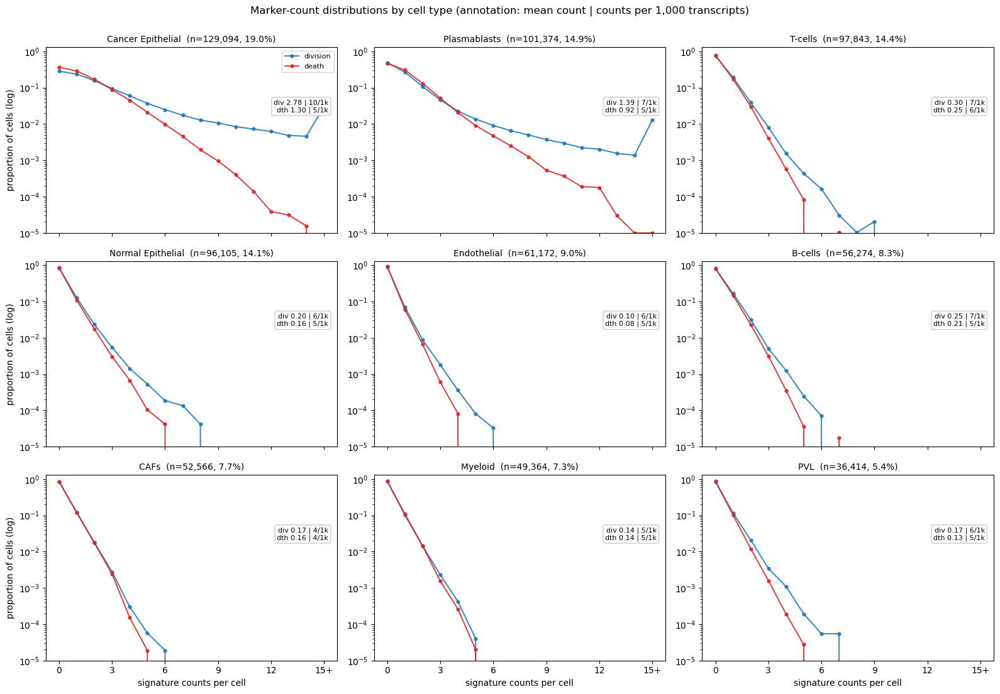

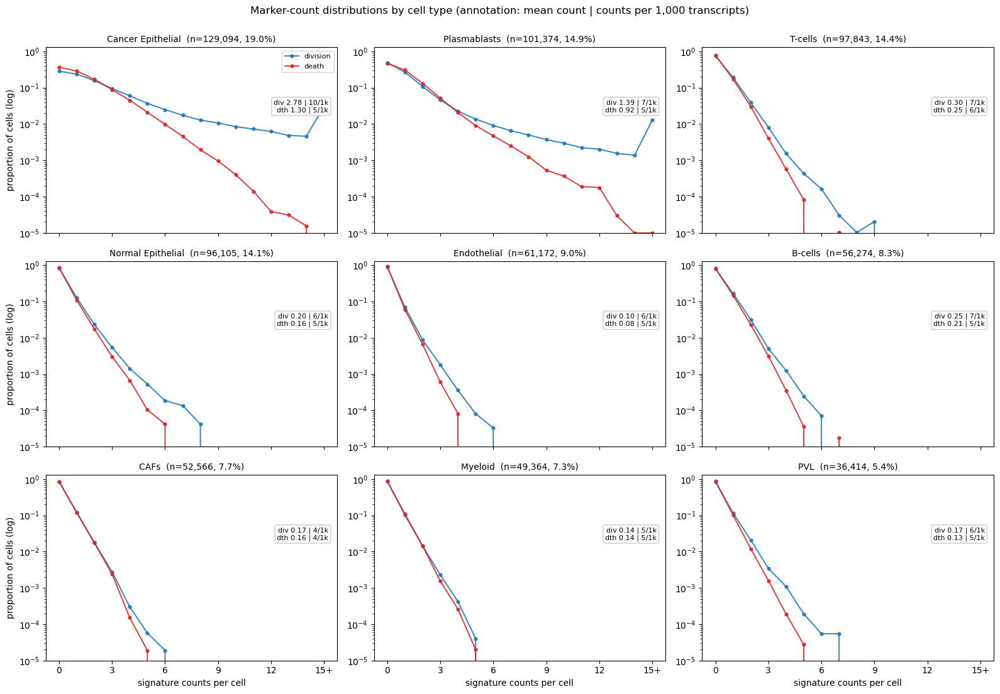

In [2]:
KMAX = 15
fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True)
for ax, t in zip(axes.ravel(), order):
    g = df[df["type"] == t]
    for y, col, lb in ((g["div"], "C0", "division"), (g["dth"], "C3", "death")):
        p = np.array([(y == k).mean() for k in range(KMAX)] + [(y >= KMAX).mean()])
        ax.plot(np.arange(KMAX + 1), p, "o-", ms=3.5, color=col, label=lb, alpha=0.85)
    ax.set_yscale("log"); ax.set_ylim(1e-5, 1.3)
    ax.set_title("%s  (n=%s, %.1f%%)" % (t, format(len(g), ","), 100*len(g)/len(df)), fontsize=10)
    ax.text(0.97, 0.72, "div %.2f | %.0f/1k\ndth %.2f | %.0f/1k"
            % (g["div"].mean(), 1000*g["div"].sum()/g["tot"].sum(),
               g["dth"].mean(), 1000*g["dth"].sum()/g["tot"].sum()),
            transform=ax.transAxes, ha="right", va="top", fontsize=8,
            bbox=dict(boxstyle="round", fc="white", ec="0.8"))
for ax in axes[-1]:
    ax.set_xticks(list(range(0, KMAX, 3)) + [KMAX])
    ax.set_xticklabels([str(k) for k in range(0, KMAX, 3)] + ["%d+" % KMAX])
    ax.set_xlabel("signature counts per cell")
for ax in axes[:, 0]:
    ax.set_ylabel("proportion of cells (log)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Marker-count distributions by cell type (annotation: mean count | counts per 1,000 transcripts)", y=1.0)
fig.tight_layout()
fig

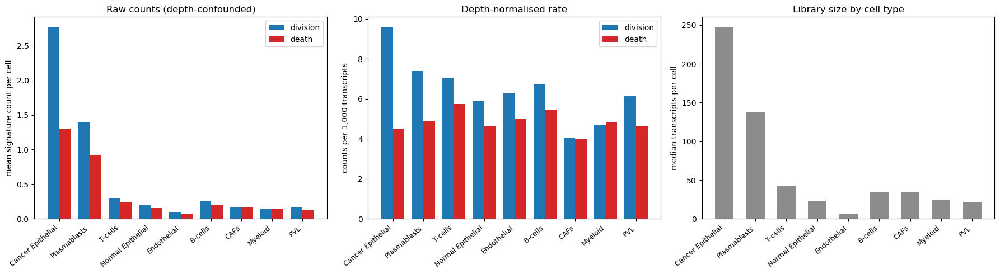

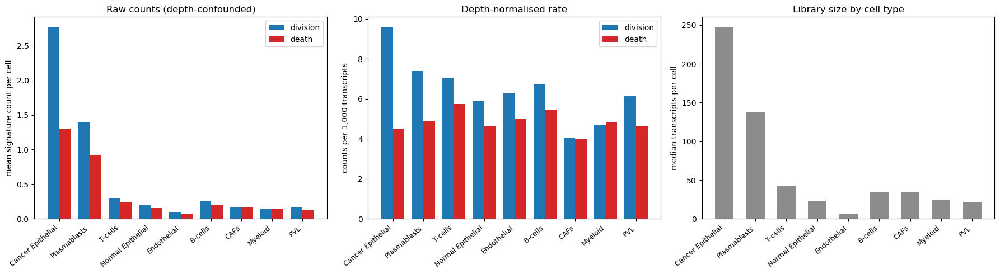

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(len(order)); w = 0.38

axes[0].bar(x - w/2, summ["div_mean"], w, color="C0", label="division")
axes[0].bar(x + w/2, summ["dth_mean"], w, color="C3", label="death")
axes[0].set_ylabel("mean signature count per cell"); axes[0].set_title("Raw counts (depth-confounded)")

axes[1].bar(x - w/2, summ["div_rate"], w, color="C0", label="division")
axes[1].bar(x + w/2, summ["dth_rate"], w, color="C3", label="death")
axes[1].set_ylabel("counts per 1,000 transcripts"); axes[1].set_title("Depth-normalised rate")

axes[2].bar(x, summ["med_lib"], 0.6, color="0.55")
axes[2].set_ylabel("median transcripts per cell"); axes[2].set_title("Library size by cell type")

for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(order, rotation=40, ha="right", fontsize=9)
axes[0].legend(); axes[1].legend()
fig.tight_layout()
fig

### Reading these

**The labels are approximate.** They are a hard argmax over z-scored continuous
scores, so cells near a boundary are assigned arbitrarily, and the z-scoring
imposes a roughly uniform prior across types. The composition it gives (Cancer
Epithelial largest, ~9% endothelial, ~8% CAFs) is at least of the right order for
a breast tumour, and its endothelial share matches the independent minor-Phi-Space
estimate within a factor of a few — unlike the raw argmax, which was out by more
than an order of magnitude.

**The strata are not interchangeable with the model coefficients.** These are
*marginal* distributions: they mix the cell type's own biology with its library
size and with wherever it happens to sit in the tissue. The model coefficients in
§9/§14 are the adjusted version — own state, neighbourhood, depth, density and
area all held fixed — which is why a type can look high here yet carry a negative
`own[...]` coefficient there. Cancer Epithelial is the clearest example: it
dominates the raw counts, but §14 still puts `own[Cancer Epithelial]` *below*
average for death (apoptosis evasion) once depth and composition are controlled.

**Compare the first two panels of the second figure before concluding anything.**
The raw-count ranking largely tracks the library-size ranking in the third panel;
the depth-normalised rates are the fairer comparison, and they compress the
differences considerably. Any cell type that looks proliferative purely because it
yields more transcripts will show up as a gap between those two panels.

**Both signatures stay zero-inflated within every stratum.** No cell type has a
distribution that looks Poisson or Gaussian — the negative binomial is not an
artefact of pooling heterogeneous populations, which is worth knowing, since
mixing distinct sub-populations is one of the standard explanations for
overdispersion and it is ruled out here.

## 24. Letting the dispersion depend on cell state

Every NB model so far has used **one** dispersion for all 680,206 cells:

$$Y_i \sim \text{NB2}(\mu_i,\ \alpha), \qquad \operatorname{Var}(Y_i) = \mu_i + \alpha\mu_i^2$$

That is a strong assumption. §23 showed the marker-count distributions are shaped
very differently across cell types, so a single $\alpha$ can only be a compromise.
This section frees it, letting each cell carry its own dispersion driven by its
Phi-Space state:

$$\log \alpha_i = \gamma_0 + \boldsymbol{\phi}_i^{\!\top}\boldsymbol{\gamma}$$

The mean model is §21's recommended division specification, with log library size
as a **free covariate rather than an offset**. That matters more here than
anywhere else in the notebook: §21 found that pinning the depth exponent at 1
when its true value is ≈0.70 inflates the fitted dispersion from 0.70 to 0.77 —
the mis-specification is absorbed *by the very parameter this section models*. Any
dispersion result computed on the offset spec would partly be measuring depth
mis-specification, so the offset is dropped before anything below is fit.

**On the link.** The request was $\theta_i = \boldsymbol{\phi}_i^{\!\top}\boldsymbol{\gamma}$.
A dispersion must stay strictly positive, and an unconstrained linear predictor on
$\alpha$ wanders negative on real data — the likelihood is then undefined. The
**log link** is the standard fix (it is what a double-GLM / NB-GAMLSS uses) and
keeps $\boldsymbol{\gamma}$ a free coefficient vector on the state, with
$e^{\gamma_j}$ reading as the multiplicative effect of state dimension $j$ on the
dispersion. Nothing else about the model changes.

This is no longer a GLM — the dispersion is itself modelled — so it is fit by
**block coordinate ascent** on the joint likelihood: a $\beta$ step (IRLS at the
current per-cell $\alpha_i$) alternating with a $\gamma$ step (L-BFGS on the
dispersion score, analytic gradient). Both blocks climb the same objective, so the
ascent is monotone; it converges in 4 outer iterations here.

### The baseline has to be re-fit too

One trap decides whether this section says anything. Every constant-$\alpha$ model
in this notebook estimates $\alpha$ by the **Cameron–Trivedi moment estimator**
from a Poisson pre-fit — not by maximum likelihood. Comparing a joint-MLE model
against a moment-estimator baseline would credit the state dependence with a gain
that is really just MLE-vs-moments on a single number. The comparison below
therefore carries **three** rows, and the middle one is the honest baseline.

In [1]:
import os, gc
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tissue_dynamics import (read_xenium, read_phi_table, attach_phi, build_adjacency,
                             average_neighbors, score_division, compute_library_size,
                             compute_local_density, get_signature_counts)
from tissue_dynamics.count_glm import fit_division_nb
from tissue_dynamics.plotting import _rootogram_counts, _pit_histogram
from tissue_dynamics.evaluate import morans_i
from tissue_dynamics.gene_sets import TIROSH_S_GENES, TIROSH_G2M_GENES

DATA, REF = "../data/Xenium_Prime_Breast_Cancer_FFPE", "Endothelial"
bc = read_xenium(DATA, sample_id="BC")
pt = read_phi_table("../data/phispace_normalised.csv", phi_cols="all")
bc = bc[bc.obs["cell_id"].isin(pt.index)].copy()
compute_library_size(bc); compute_local_density(bc, radius=50.0)
attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()

# z-scored argmax strata, exactly as section 23 (raw argmax is scale-dominated)
P = np.asarray(bc.obsm["phi"], dtype=float); types = np.array(bc.uns["phi_names"])
ctype = types[((P - P.mean(0)) / P.std(0)).argmax(axis=1)]
keep_c = [i for i, n in enumerate(types) if n != REF]        # drop the reference column
bc.obsm["phi"] = P[:, keep_c]; bc.uns["phi_names"] = [types[i] for i in keep_c]

build_adjacency(bc, radius=80.0); average_neighbors(bc); score_division(bc)
bc.X = bc.layers["counts"]; del bc.layers["counts"]; gc.collect()

# Section 21's recommended division spec: log library size as a FREE covariate,
# not an offset. Division counts scale sub-proportionally with depth (implied
# exponent 0.70, not 1.0), and pinning it at 1 pushes the mis-specification into
# the dispersion - exactly the parameter this section is trying to model.
RATE = dict(predictors="own+neighbor", offset_key=None,
            spline_keys=("local_density",), spline_df=5,
            covariate_keys=("log_total_counts", "cell_area"), fitter="irls")
fit_v = fit_division_nb(bc, dispersion_predictors="own", **RATE)   # state-dependent alpha
fit_c = fit_division_nb(bc, **RATE)                                # alpha by moments (as before)
d = fit_v["dispersion"]
print("outer iterations to convergence:", d["n_outer"])
print("alpha, moment estimator (every earlier section) = %.4f" % fit_c["alpha"])
print("alpha, constant-alpha MLE (honest baseline)     = %.4f" % d["alpha_constant_alpha"])
a_i = fit_v["alpha"]
print("alpha_i, state-dependent: median %.3f  IQR %.3f-%.3f  range %.3f-%.3f"
      % (np.median(a_i), *np.percentile(a_i, [25, 75]), a_i.min(), a_i.max()))
lr = d["lr_vs_constant_alpha"]
print("\nLR, state-dependent vs constant-alpha MLE: chi2=%.1f  df=%d  p=%.2e"
      % (lr["statistic"], lr["df"], lr["p_value"]))
print("(against the moment-estimator baseline it would read chi2=%.1f - most of which is"
      "\n MLE-vs-moments on the intercept, not state dependence)"
      % (2 * (d["loglik"] - fit_c["loglik"])))

print("\ndispersion coefficients  log alpha_i = gamma . [1, phi_i]")
gt = d["coef"].copy()
print(gt.reindex(gt["z"].abs().sort_values(ascending=False).index).round(3).to_string(index=False))

/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_52232/2477768247.py:13: UserWarning: spatialdata-io failed to read this sample (FileNotFoundError(2, 'No such file or directory')); falling back to the manual cell_feature_matrix reader.
  bc = read_xenium(DATA, sample_id="BC")


/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_52232/2477768247.py:17: UserWarning: 3592/683798 cells have a NaN phi embedding (a matched row exists, but with missing values -- typically near-empty segmentation artifacts the embedding method couldn't score). These will propagate NaNs into neighbor-averaging and model fitting; filter them out first, e.g. `adata = adata[~np.isnan(adata.obsm['phi']).any(axis=1)].copy()`.
  attach_phi(bc, pt); bc = bc[~np.isnan(bc.obsm["phi"]).any(axis=1)].copy()


/var/folders/2_/n1nxpgm97jd5d_yn3nfpwfyr0000gq/T/ipykernel_52232/2477768247.py:25: UserWarning: 54/680206 cells have no spatial neighbors within radius=80.0 (isolated); their neighbor-averaged embedding will be the zero vector.
  build_adjacency(bc, radius=80.0); average_neighbors(bc); score_division(bc)


outer iterations to convergence: 9
alpha, moment estimator (every earlier section) = 0.7049
alpha, constant-alpha MLE (honest baseline)     = 0.6765
alpha_i, state-dependent: median 0.650  IQR 0.621-0.679  range 0.057-3.223

LR, state-dependent vs constant-alpha MLE: chi2=265.9  df=8  p=7.13e-53
(against the moment-estimator baseline it would read chi2=319.5 - most of which is
 MLE-vs-moments on the intercept, not state dependence)

dispersion coefficients  log alpha_i = gamma . [1, phi_i]
                  term  estimate  std_error      z  exp_estimate
             own[CAFs]    -0.975      0.163 -5.988         0.377
              own[PVL]     0.713      0.138  5.150         2.040
own[Cancer Epithelial]     0.338      0.067  5.028         1.402
own[Normal Epithelial]    -0.445      0.092 -4.853         0.641
                 const    -0.899      0.442 -2.037         0.407
          own[T-cells]     0.069      0.080  0.860         1.071
          own[B-cells]    -0.066      0.106 -0.621

### Does the rootogram change?

Three models, one mean specification, differing only in how the dispersion is
handled. The rootogram summary is the RMS hanging discrepancy
$\sqrt{\text{obs}_k}-\sqrt{\text{exp}_k}$ over counts 0–12; PIT is the largest
deviation of a bar from uniform; Moran's $I$ is on the Pearson residuals
(120k-cell subsample, which is why it sits below the whole-tissue values in §9).

                   model  rootogram RMS  worst bin  PIT max|dev|  resid Moran I
constant alpha (moments)         6.3388    13.4438        0.0397         0.0166
    constant alpha (MLE)         6.1877    12.4790        0.0345         0.0167
   state-dependent alpha         5.8444    11.2654        0.0347         0.0166


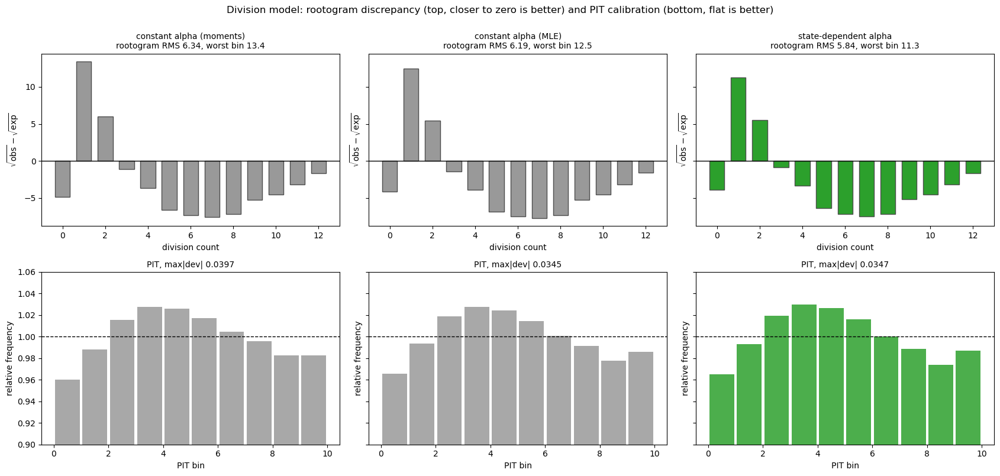

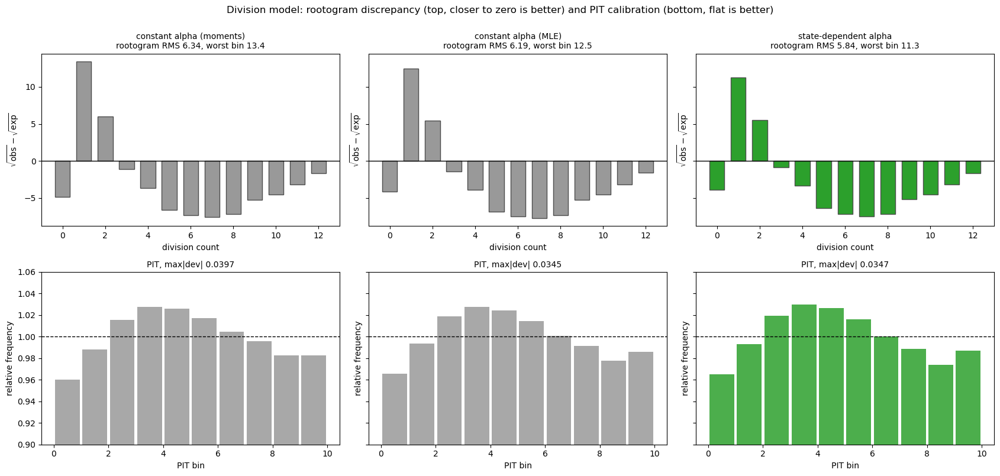

In [2]:
y, _tot, _g = get_signature_counts(bc, list(dict.fromkeys(
    list(TIROSH_S_GENES) + list(TIROSH_G2M_GENES))))
k = fit_v["keep"]
xy = np.asarray(bc.obsm["spatial"], dtype=float)
sub = np.random.default_rng(0).choice(int(k.sum()), 120_000, replace=False)

models = [("constant alpha (moments)",  fit_c["fitted_mu"][k], fit_c["alpha"]),
          ("constant alpha (MLE)",      d["fitted_mu_constant_alpha"][k],
                                        d["alpha_constant_alpha"]),
          ("state-dependent alpha",     fit_v["fitted_mu"][k], a_i)]
yk, xyk = y[k], xy[k]

rows, roots, pits = [], {}, {}
for lab, mu, al in models:
    ks, obs, exp = _rootogram_counts(yk, mu, al, max_count=12)
    disc = np.sqrt(obs) - np.sqrt(exp)
    _e, h = _pit_histogram(yk, mu, al, n_bins=10)
    resid = (yk - mu) / np.sqrt(mu + al * mu ** 2)
    mi = morans_i(resid[sub], coords=xyk[sub], n_neighbors=8, permutations=99, seed=0)
    roots[lab], pits[lab] = (ks, obs, exp), h
    rows.append({"model": lab, "rootogram RMS": np.sqrt(np.mean(disc ** 2)),
                 "worst bin": np.max(np.abs(disc)), "PIT max|dev|": np.max(np.abs(h - 1)),
                 "resid Moran I": mi["I"]})
print(pd.DataFrame(rows).round(4).to_string(index=False))

# The classic hanging rootogram (section 11) is unreadable here: sqrt(freq) at
# count 0 is ~680, so discrepancies of ~15 are invisible. Plot the discrepancy
# itself, on one shared scale, which is exactly what the RMS column summarises.
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharey="row")
for j, (lab, mu, al) in enumerate(models):
    ks, obs, exp = roots[lab]
    ax = axes[0, j]
    ax.bar(ks, np.sqrt(obs) - np.sqrt(exp), width=0.7,
           color=("C2" if j == 2 else "0.6"), edgecolor="0.3")
    ax.axhline(0, color="k", lw=1)
    ax.set_title("%s\nrootogram RMS %.2f, worst bin %.1f"
                 % (lab, rows[j]["rootogram RMS"], rows[j]["worst bin"]), fontsize=10)
    ax.set_xlabel("division count")
    ax.set_ylabel(r"$\sqrt{\rm obs}-\sqrt{\rm exp}$")
    ax = axes[1, j]
    ax.bar(np.arange(10) + 0.5, pits[lab], width=0.9,
           color=("C2" if j == 2 else "0.6"), alpha=0.85)
    ax.axhline(1.0, color="k", ls="--", lw=1)
    ax.set_ylim(0.9, 1.06); ax.set_xlabel("PIT bin"); ax.set_ylabel("relative frequency")
    ax.set_title("PIT, max|dev| %.4f" % rows[j]["PIT max|dev|"], fontsize=10)
fig.suptitle("Division model: rootogram discrepancy (top, closer to zero is better) "
             "and PIT calibration (bottom, flat is better)", y=1.0)
fig.tight_layout(); fig

### Rootograms per cell type, before and after

The pooled rootogram averages over populations whose count distributions §23
showed to be quite different. Stratifying it says *where* a per-cell dispersion
buys anything. The baseline here is the constant-$\alpha$ **MLE**, so the
comparison isolates state dependence.

        cell type      n  RMS constant  RMS state-dep  change %  median alpha_i  marginal var/mean
Cancer Epithelial 129094         7.280          7.437     2.158           0.700              7.286
     Plasmablasts 101374         2.911          2.547   -12.521           0.624              8.488
          T-cells  97843         3.857          3.714    -3.724           0.648              1.230
Normal Epithelial  96105         2.008          1.948    -2.989           0.629              1.404
      Endothelial  61172         0.747          0.773     3.515           0.658              1.276
          B-cells  56274         2.340          2.171    -7.212           0.640              1.206
             CAFs  52566         0.757          0.605   -20.004           0.583              1.183
          Myeloid  49364         1.532          1.519    -0.848           0.651              1.205
              PVL  36414         0.560          0.493   -11.991           0.695              1.304

corr(marg

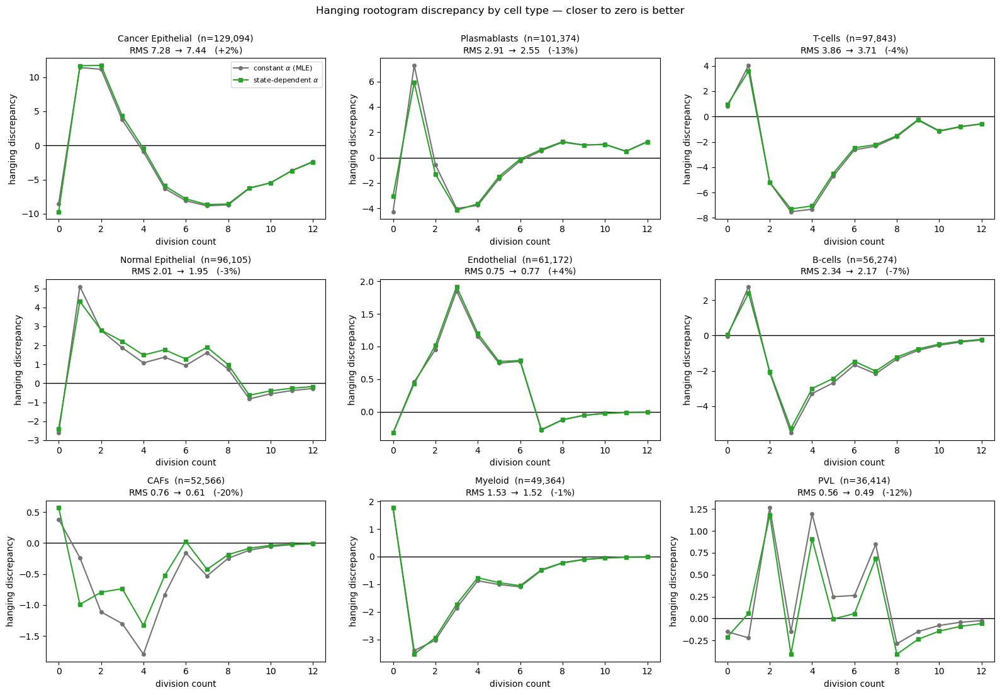

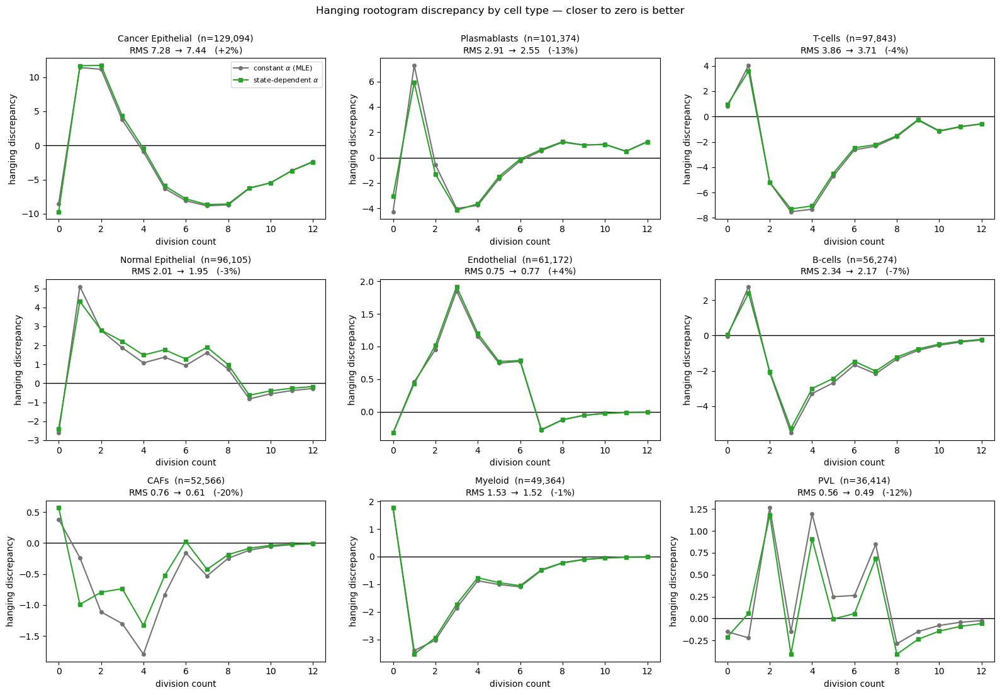

In [3]:
ck = ctype[k]
order = pd.Series(ck).value_counts().index.tolist()
mu_c2, al_c2 = d["fitted_mu_constant_alpha"][k], d["alpha_constant_alpha"]
mu_v2 = fit_v["fitted_mu"][k]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
srows = []
for ax, t in zip(axes.ravel(), order):
    m = ck == t
    ks, o1, e1 = _rootogram_counts(yk[m], mu_c2[m], al_c2, max_count=12)
    ks, o2, e2 = _rootogram_counts(yk[m], mu_v2[m], a_i[m], max_count=12)
    r1 = np.sqrt(np.mean((np.sqrt(o1) - np.sqrt(e1)) ** 2))
    r2 = np.sqrt(np.mean((np.sqrt(o2) - np.sqrt(e2)) ** 2))
    ax.axhline(0, color="k", lw=1)
    ax.plot(ks, np.sqrt(o1) - np.sqrt(e1), "o-", ms=4, color="0.45",
            label="constant $\\alpha$ (MLE)")
    ax.plot(ks, np.sqrt(o2) - np.sqrt(e2), "s-", ms=4, color="C2",
            label="state-dependent $\\alpha$")
    ax.set_title("%s  (n=%s)\nRMS %.2f $\\to$ %.2f   (%+.0f%%)"
                 % (t, format(int(m.sum()), ","), r1, r2, 100 * (r2 - r1) / r1), fontsize=10)
    ax.set_xlabel("division count"); ax.set_ylabel("hanging discrepancy")
    srows.append({"cell type": t, "n": int(m.sum()), "RMS constant": r1, "RMS state-dep": r2,
                  "change %": 100 * (r2 - r1) / r1, "median alpha_i": float(np.median(a_i[m])),
                  "marginal var/mean": float(yk[m].var() / max(yk[m].mean(), 1e-9))})
axes[0, 0].legend(fontsize=8)
fig.suptitle("Hanging rootogram discrepancy by cell type — closer to zero is better", y=1.0)
fig.tight_layout()

st = pd.DataFrame(srows)
print(st.round(3).to_string(index=False))
print("\ncorr(marginal var/mean, RMS improvement %%) = %+.3f"
      % np.corrcoef(st["marginal var/mean"], st["change %"])[0, 1])
fig

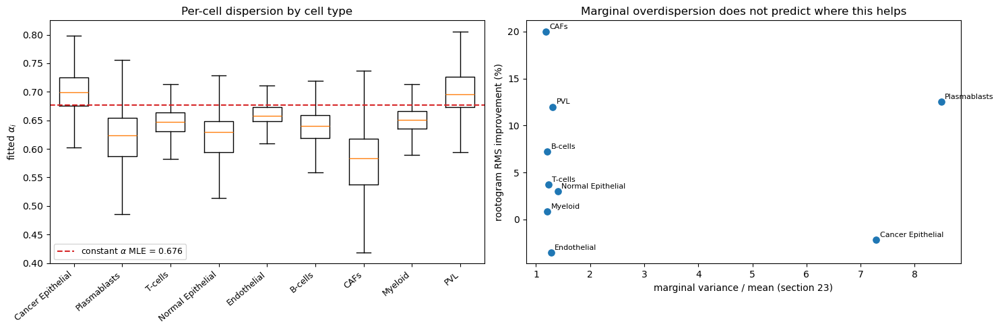

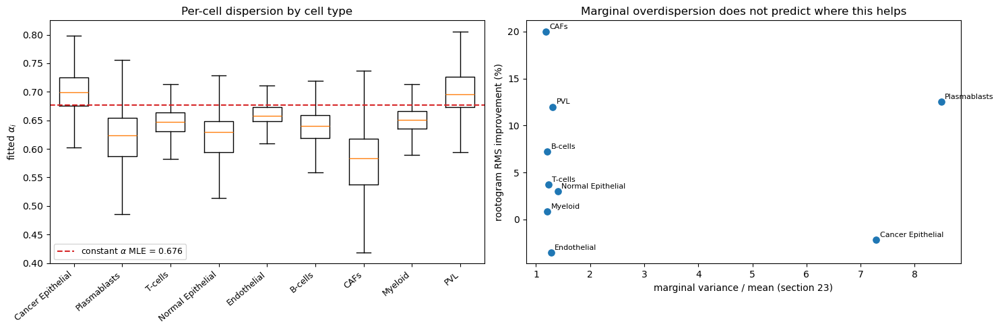

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
pos = np.arange(len(order))
axes[0].boxplot([a_i[ck == t] for t in order], positions=pos, widths=0.6, showfliers=False)
axes[0].axhline(al_c2, color="C3", ls="--", lw=1.5,
                label="constant $\\alpha$ MLE = %.3f" % al_c2)
axes[0].set_ylabel(r"fitted $\alpha_i$"); axes[0].legend(fontsize=9)
axes[0].set_title("Per-cell dispersion by cell type")
axes[1].scatter(st["marginal var/mean"], -st["change %"], s=45, color="C0")
for _, r in st.iterrows():
    axes[1].annotate(r["cell type"], (r["marginal var/mean"], -r["change %"]),
                     fontsize=8, xytext=(4, 3), textcoords="offset points")
axes[1].set_xlabel("marginal variance / mean (section 23)")
axes[1].set_ylabel("rootogram RMS improvement (%)")
axes[1].set_title("Marginal overdispersion does not predict where this helps")
for ax in (axes[0],):
    ax.set_xticks(pos); ax.set_xticklabels(order, rotation=40, ha="right", fontsize=9)
fig.tight_layout(); fig

### Reading section 24

**The rootogram improves, and by less than a naive comparison would say.**
Against the constant-$\alpha$ **MLE** of the same mean model the likelihood-ratio
statistic is $\chi^2 = 266$ on 8 df ($p \approx 7\times10^{-53}$); against the
moment-estimator baseline it would read 320. The pooled rootogram RMS falls from
6.19 to 5.84 (−5.5%), and the worst bin from 12.5 to 11.3.

Both numbers are smaller than they were on the library-size *offset* spec (there:
$\chi^2 = 279$ against the MLE but 741 against moments, RMS 7.31 → 6.69). That is
the point of fitting this on §21's free-depth model. Pinning the depth exponent at
1 when its true value is ≈0.70 inflates the moment estimate of $\alpha$ from 0.705
to 0.774, so a dispersion model fit on the offset spec spends part of its budget
undoing a depth error. Freeing depth removes that, and what is left is the real
state dependence.

**The gain is in the low counts.** The count-1 bin — which every version of this
model **under**-predicts — falls from a discrepancy of 13.4 (moments) to 12.5
(MLE) to 11.3, and the count-0 over-prediction shrinks with it. The
counts-5-to-8 deficit barely moves. A state-dependent dispersion sharpens the bulk
of the distribution; it does not fix the tail, which §21 already identified as
structural (a zero-inflation/hurdle-like feature) rather than a scaling artefact.

**Calibration and spatial structure are untouched.** The PIT is flat to within
noise either way (0.0345 → 0.0347) and Moran's $I$ on the residuals does not move
(0.0167 → 0.0166) — as it must not, since the dispersion model never touches
$\mu_i$. This buys a better-fitting marginal count distribution, nothing else.
Whatever drives the residual autocorrelation, this is not the fix for it.

### Which populations are actually overdispersed — and why the offset spec lied

This is where freeing the depth term changes the *conclusion*, not just the
numbers. The two specs disagree about which cell types carry extra dispersion:

| term | $e^{\gamma}$, offset spec | $e^{\gamma}$, free depth | $z$, free depth |
|---|---:|---:|---:|
| PVL | 1.29 ($z$ = 1.9) | **2.04** | +5.15 |
| Cancer Epithelial | 1.13 ($z$ = 2.0) | **1.40** | +5.03 |
| Normal Epithelial | 0.50 | **0.64** | −4.85 |
| CAFs | 0.275 | **0.38** | −5.99 |
| Plasmablasts | 0.85 ($z$ = −3.4) | 0.97 ($z$ = −0.6) | — |

On the offset spec, tumour cells looked *averagely* dispersed and plasmablasts
looked significantly under-dispersed. On the correctly specified mean model both
reverse: **Cancer Epithelial and PVL are the clearly over-dispersed populations**
(1.4× and 2.0× the baseline), plasmablasts are indistinguishable from average, and
the under-dispersed populations are CAFs (0.38×) and normal epithelium (0.64×).
Every one of those four has $|z| \ge 4.85$.

Read $e^{\gamma}$ and the per-stratum $\alpha_i$ boxplot as two different things.
$e^{\gamma_j}$ is the effect of one unit of *score* $j$, whereas $\alpha_i$
depends on the cell's whole $\boldsymbol{\phi}$ vector and the strata are hard
argmax labels — most cells carry appreciable score on several axes, so the
realised per-stratum medians (0.70 for Cancer Epithelial and PVL, 0.58 for CAFs,
against a constant-$\alpha$ MLE of 0.676) are far more compressed than the
coefficients. The ordering is the same; the spread is not.

So the offset was not a harmless simplification — it actively misassigned
dispersion across cell types, because depth mis-specification is not distributed
evenly across populations that differ in library size (§23, third panel). This is
the strongest argument in the notebook for §21's recommendation.

It also **partly rehabilitates §23's motivation**. §23 found the marginal
variance-to-mean ratio concentrated in Cancer Epithelial (7.29) and Plasmablasts
(8.49), and on the offset spec the fitted dispersion refused to agree. On the free
spec Cancer Epithelial does come out genuinely over-dispersed. Plasmablasts still
do not — and the correlation between marginal variance/mean and where the
rootogram improves is still nil (+0.014). The reason stands: the marginal ratio is
inflated by *explained* variation (tumour cells span a wide range of $\mu_i$),
whereas $\alpha$ is the *conditional* overdispersion left after the mean model.
They are different quantities and only sometimes agree.

**Seven of nine cell types improve; two get slightly worse.** CAFs (−20%),
Plasmablasts (−13%), PVL (−12%) and B-cells (−7%) gain most. Cancer Epithelial
(+2.2%) and Endothelial (+3.5%) degrade slightly — a real trade-off, not a bug:
the fit maximises the *joint* likelihood over 680k cells, and is free to give up a
little marginal-histogram accuracy on one population to gain per-cell accuracy
elsewhere. Cancer Epithelial is the largest stratum and gets the largest $\alpha$
increase, which widens its predictive distribution more than its pooled count
histogram wants.

**Recommendation.** Keep it for the division model, and only on the free-depth
spec. The cost is 8 parameters and about 20 seconds; the LR test is decisive, the
marginal fit improves for seven of nine populations, and the dispersion estimates
are now interpretable — over-dispersed tumour and perivascular cells, tight
stroma and normal epithelium. Do not read it as fixing calibration or spatial
structure; it fixes neither. And do not port it to the death model without
re-testing: §21 kept the offset there, so the same contamination argument does not
apply.